# Model analysis: observational preferences and competing solutions

This notebook assesses saved simulations; it launches no new models. Lower cost means better agreement under the selected objective. Each evaluation remains separate, including repeated parameter sets. PA is treated as an ordinary linear parameter.

## Two primary views — different questions

| View | Candidate pool | Interpretation |
|---|---|---|
| **A. Available models per objective** | All eligible models with finite scores for that objective, partitioned by relevant scoring compatibility | Best available fits and selected parameter ranges. Different objectives can have different candidates; changes between these ranges cannot be attributed solely to adding data. |
| **B. Shared models per comparison** | Candidates with every score required by the two objectives being compared | Both objectives assess exactly the same candidates. Differences describe the effect of adding an observable on this sampled pool. Unrelated observable scores are not required. |

For example, SED → SED+INT requires SED and INT scores, but not PDI or ALMA. Each comparison has its own shared pool. Its SED winner can differ from the winner using every available SED model.

Both views require usable evaluations at the **configured final budget**, finite native cost, a successful native-cost consistency audit, and known compatible physical/numerical metadata. The audit compares cost with the evaluation's original objective, never with an arbitrary subset score. Intermediate-budget evaluations remain excluded. Unknown historical data versions remain a compatibility limitation.

`POOL_ID` chooses a physical/numerical setup, not an objective or solution. Within it, relevant scoring differences create separate score pools; these are never silently merged. SED-specific data hashes are not supplied by the current loader, so SED compatibility relies on the available physical/numerical metadata. Pool labels are snapshot-local; exports retain full keys and evaluation IDs.

## Stages and assessment rules

| Stage | What happens | Assessment |
|---|---|---|
| 1. Settings and audit | Load histories, parameters, scores and metadata | Flag failures, missing scores and native-cost mismatches |
| 2. Physical pool | Select one compatible physical/numerical setup | Keep usable final-budget evaluations; retain repeats |
| 3. View A: available models | Build a separate pool for each objective | Lowest summed original score wins; retain ties; summarise competitive parameter ranges |
| 4. View B: shared comparisons | Rescore each objective pair on the same candidates | Measure parameter shifts and width changes after adding observations |
| 5. Selection robustness | Repeat both views across allowances, retained fractions and histories | Show sample counts and mask unsupported effects |
| 6. Fully scored supplement | Select one pool containing every observable | Provides a fixed reference across all objectives; clearly separate from views A/B |
| 7. Parameter trade-offs | Compare Spearman associations and sampled score envelopes | Identify compensation candidates, not established identifiability |
| 8. Alternative solutions | Group near-best parameter sets and find Pareto candidates | Identify distinct competitive families and observable trade-offs |
| 9. Weight sensitivity | Temporarily vary one observable group's weight | Check whether winning models and selected sets change |
| 10. Export and follow-up | Save membership, winners, metrics, settings and candidate IDs | Preserve evidence and identify further experiments needed |

The detailed cross-objective regret, prefix checks, correlations, families, Pareto and weight experiments below use the **fully scored supplement**. They are skipped if it is unavailable; views A/B still run. Every objective/pool has its own minimum and selection threshold. These are descriptive analyses of adaptive optimiser samples, not posterior probabilities or confidence intervals.


In [15]:
from pathlib import Path
import sys, json, hashlib, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
# Explicit inline backend ensures figures are embedded in executed notebook outputs.
get_ipython().run_line_magic('matplotlib', 'inline')

# Locate the notebook helpers whether Jupyter starts here or at the workspace root.
search = [p/q for p in [Path.cwd(), *Path.cwd().parents]
          for q in [Path('.'), Path('scripts/post-processing'), Path('modelling_optimisation/scripts/post-processing')]]
NOTEBOOK_DIR = next(p for p in search if (p/'model_analysis_utils.py').is_file())
REPOSITORY = NOTEBOOK_DIR.parents[1]
sys.path.insert(0, str(NOTEBOOK_DIR))
from parameter_labels import parameter_label
from run_summary_utils import load_runs, coverage_table, SUBSETS, scoring_fingerprint
from observation_convergence_utils import (readable_model_labels, parameter_reference,
    parameter_values, plot_restriction, parameter_score_diagnostic)
from model_analysis_utils import (GROUPS, objective_design, addition_design, score_matrix,
    competitive_mask, restriction_tables, association_table, alternative_families,
    pareto_mask, empirical_profiles, distribution_effect, bootstrap_history_effects, plot_heatmap)
pd.set_option('display.max_columns', 24)
figures = {}
def show(name, figure):
    if figure is not None:
        figures[name] = figure
        display(figure)
        plt.close(figure)

from model_analysis_utils import eligible_pool_candidates, analyse_pool_views, plot_available_pool_costs


## 1. Settings: what each control means

`POOL_ID` selects a physical/numerical compatibility group; relevant score metadata are checked separately for each objective or comparison. `PARAMETERS` selects independent varied ConfigSpace names, not derived/tied values. No model is discarded because of a top-N display limit.

The allowance rule is **score ≤ best + max(|best| × relative_allowance, absolute_allowance)**. Thus a positive best of 100 with allowance 0.5 admits scores ≤150. It is not “50% probability”. Matched fractions keep the lowest-scoring fraction including ties and expose changes caused simply by retaining different numbers of models. Every objective has its own minimum and selection.

In [16]:
# Input: each root may contain multiple histories and optimiser seeds.
RUN_FOLDERS = {'Dubrulle': Path('/fred/oz061/kandrych/smac/1_akke_2zones_wider_tapered/dubrulle')}
POOL_ID = None                 # None: largest eligible physical/numerical pool, including partial-score models.
# Copy a 'Physical pool NN' label from physical_pool_inventory to select another setup.
PARAMETERS = None              # None: all varied, nonconstant, independent parameters in that pool.
RELATIVE_ALLOWANCES = [0.10, 0.25, 0.50]  # Cost tolerances for robustness, not confidence levels.
ABSOLUTE_ALLOWANCE = 0.0        # Minimum additive slack in original score units; useful when best=0.
MATCHED_FRACTIONS = [0.05, 0.10, 0.20]    # Approximate retained fractions; cutoff ties stay included.
DISPLAY_ALLOWANCE = 0.50       # Main selected sample; not a change to the optimiser.
DISPLAY_FRACTION = 0.10        # Equal-size comparison shown in attribution heatmaps.
MIN_MODELS = 20                # Minimum valid values before reporting a supported effect.
HISTOGRAM_BINS = 15            # Shared fixed parameter bins; rerun with 10/25 to assess bin sensitivity.
PROFILE_MIN_MODELS = 10        # Sparse profile bins retain counts but have masked plotted summaries.
# Profile plots automatically include every parameter in references; no parameter shortlist.
VIEW_A_COST_ALLOWANCES = (0.10, 0.50, 1.0)  # Relative excess: 10%, 50%, 100% above best.
VIEW_A_PANELS_PER_PAGE = 6  # All parameters are shown, across as many pages as needed.
POINT_SIZE = 16                # Circle area in points squared, identical for all/selected candidates.
POINT_ALPHA = 0.55             # Opacity, identical for all/selected candidates; black/blue distinguish them.
PAIR_PLOTS = 4                 # Display strongest selected numeric associations; all pairs stay in the table.
FAMILY_ALLOWANCE = 0.10        # Near-best all-data sample for searching distinct alternatives.
FAMILY_DISTANCE_CUTS = [0.10, 0.20, 0.30] # Diagnostic mixed-distance thresholds, not physical equivalence tests.
WEIGHT_FACTORS = [0.5, 1.0, 2.0]         # Explicit stress test of one group's weight; original scores untouched.
PREFIX_FRACTIONS = [0.50, 0.75, 1.0]     # Chronological saved-search prefixes; not independent replicates.
# NOT USED NOW
# To assess the stability of resulting parameter distribution, but vaguely
# Only fill after confirming same design, scoring, numerical setup and independent optimiser histories.
VERIFIED_REPLICATE_HISTORIES = []        # >=5 for conditional history-level bootstrap; current runs differ in strategy.
BOOTSTRAP_REPETITIONS = 1000             # Resamples whole run effects, never individual adaptive trials.
RANDOM_SEED = 42                         # Reproducibility of bootstrap only; no new simulation seeds are generated.
SAVE_OUTPUTS = False                     # Set True to export all evidence tables, plots and provenance.
OUTPUT_DIR = NOTEBOOK_DIR/'model_analysis_outputs'

# View A descriptive score weighting: delta is the score increase that HALVES weight.
SCORE_WEIGHTED_ENABLED = True
SCORE_WEIGHTED_RETAIN_FRACTION = 0.40  # Lowest-scoring 40% per objective/pool, including cutoff ties.
SCORE_WEIGHTED_OBJECTIVES = None  # None: every available View-A objective, each pool separately.
# None includes ALL independent varied parameters, regardless of PARAMETERS above.
SCORE_WEIGHTED_PARAMETERS = None
# None: physical groups aligned with seed1; only independent parameters in this pool are used.
# Override with {'Group title': ['parameter_name', ...], ...}; unassigned names remain in Other parameters.
SCORE_WEIGHTED_PARAMETER_GROUPS = None
SCORE_WEIGHTED_COLOR_SCALE = 'auto'  # Log for positive varying scores; otherwise linear.
SCORE_WEIGHTED_STYLE = 'reference'  # 'reference': one black chain + score cloud; 'sensitivity': overlays.
SCORE_WEIGHTED_REFERENCE_SETTING = None  # None: middle configured setting (25% by default).
# Explicit setting IDs, e.g. 'half_weight_01', are listed in score_temperatures.
SCORE_WEIGHTED_HALF_WEIGHT_FRACTIONS = (0.10, 0.25, 0.50)  # delta = fraction * abs(pool best).
# Absolute deltas REPLACE fractions. Keys: objective or (objective, full score_pool_key).
# Illustrative syntax only: {'PDI': [2., 5., 10.], 'ALMA': [1., 2., 4.]}.
# These numbers are NOT calibrated values. A best score of zero requires an override.
SCORE_WEIGHTED_ABSOLUTE_DELTAS = {}
SCORE_WEIGHTED_CONTOUR_MASSES = (0.68, 0.95, 0.997)  # Fractions of plotted weight, not confidence levels.
SCORE_WEIGHTED_BINS = 20
SCORE_WEIGHTED_SMOOTH = 2  # Gaussian histogram smoothing for the reference style; 0 shows raw bins.
SCORE_WEIGHTED_MIN_ESS = 20  # Weight-concentration guard, not independent sample size.


## 2. Scientific audit of the current scoring logic

**Assessment:** defensible as an explicitly chosen multi-observable optimisation loss; insufficient for calibrated parameter confidence intervals, likelihood-ratio tests, AIC/BIC or posterior probabilities.

| Term | Current implementation | Consequence | Recommended scientific improvement (not applied here) |
|---|---|---|---|
| SED | Sum of squared residuals/variances, divided by N−1; extinction is fitted as a nuisance parameter | Dataset-normalised loss; N−1 is not the global model's residual degrees of freedom | Fit an explicit flux likelihood, handle calibration/correlated/noncontemporaneous photometry as justified; profile or marginalise extinction |
| Interferometry | Each instrument's squared-error sum divided by N−1; four instruments are added | Group sizes are implicitly reweighted; correlations and fitted nuisance fractions complicate inference | Use visibility covariance/calibration model and jointly account for nuisance parameters; do not divide each likelihood by N−1 |
| PDI | Weighted squared differences of polarisation fraction, radial means and quadrant sums; weights 1e5, 1e4, 5e3 in the current caller | Empirical weights, different summary units, shared pixels and correlated summaries; no error model | Estimate a joint summary covariance from noise propagation/injection or calibrated resampling; avoid independent treatment of overlapping summaries; alternatively fit suitable Stokes data with covariance |
| ALMA | 100 × sum(residual²)/sum(observed²) within an aperture | Flux-energy relative error, not noise-normalised χ²; beam correlations not represented by an independent-pixel likelihood | Prefer calibrated visibility likelihood when available; otherwise beam-correlated image noise, fixed mask, calibration/background nuisance terms |
| Total | Sum of those terms | Relative influence is a modelling choice, not automatically statistical information | Either retain and explicitly justify this engineering loss, or implement a separately versioned probabilistic model after validating uncertainties |

For a Gaussian data vector a coherent candidate objective is

\[
-2\log L(\theta)=r(\theta)^T C(\theta)^{-1}r(\theta)+\log\det C(\theta)+\text{constant}.
\]

Add likelihoods only for conditionally independent blocks; shared calibration or overlapping PDI summaries require covariance or a joint model. The log determinant matters if covariance depends on the model or fitted noise. SED/interferometry code already computes a Gaussian log-likelihood, but the optimiser uses reduced χ². If its optional model-dependent systematic variance is enabled, dropping the normalisation can favour inflated variance. Inspect the recorded configuration before claiming this occurred.

Do **not** make scores numerically similar by arbitrary renormalisation and call that inference. Measurement uncertainties, simulation noise and model discrepancy are different quantities. Validate each against residuals and repeats; excessive discrepancy may indicate model inadequacy, not merely errors needing inflation. A new likelihood changes relative dataset influence and requires a new score version and validation runs.

**Concrete code-review findings:** PDI's saved `loss_definition` string says “mean(...)”, while the function returns a **sum** of weighted components; the metadata string alone is insufficient provenance. The callable currently ignores legacy PDI error/tolerance arguments with a warning. PDI quadrants depend on candidate PA; observed summaries and covariance must be recomputed consistently. The shared aperture depends on available image extents; verify this is constant across trials. Guard N≤1 in future SED/interferometry revisions. None of these modelling functions is changed here.

Sources: correlated interferometric errors can bias fitting ([Lachaume 2021](https://www.cambridge.org/core/journals/publications-of-the-astronomical-society-of-australia/article/biasfree-model-fitting-of-correlated-data-in-interferometry/692E419C7A651CE54983572D303D0A9E)); nuisance-reoptimised profiles can reveal practical non-identifiability ([Raue et al. 2009](https://academic.oup.com/bioinformatics/article/25/15/1923/213246)). These motivate future validation, not retroactive likelihood claims for saved scalar costs.

In [17]:
# Hash source files before analysis; these are CURRENT-code hashes, not historical run hashes.
source_paths = [REPOSITORY/'SMAC3.py', *sorted((REPOSITORY/'lib').glob('*.py'))]
source_hashes_before = {str(path): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_paths}
evaluations, inventory, records, configspaces = load_runs(RUN_FOLDERS)
evaluations = readable_model_labels(evaluations)
coverage = coverage_table(evaluations)
display(inventory[['history','optimizer_seed','configured_max_budget','recorded_trials',
                   'configspace_hash','template_hash','photon_settings','stages']])
display(coverage)
cost_audit = evaluations.groupby(['history','cost_audit_status','exclusion']).size().rename('n').reset_index()
display(cost_audit)
# Recorded descriptors can differ from current source. Keep them reviewable.
recorded_scoring = pd.DataFrame([{'history': row.history, 'objective': row.objective_key,
    'comparison_key': row.comparison_key,
    'scoring_metadata': json.dumps(records[row.evaluation_id]['scoring_metadata'], sort_keys=True)}
    for row in evaluations.drop_duplicates(['history','comparison_key']).itertuples()])
display(recorded_scoring)


,history,optimizer_seed,configured_max_budget,recorded_trials,configspace_hash,template_hash,photon_settings,stages
0,Dubrulle/sed [seed 609655],609655,1.0,2000,c80973cf7b720f8fdae5111585580858dc0c1227b2f8e6...,d7b0fff23c67654da5612b12be8bafaad5333568b13663...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""sed"", ""products"": [""sed""], ""budget..."
1,Dubrulle/sed_alma [seed 609070],609070,3.0,1001,c80973cf7b720f8fdae5111585580858dc0c1227b2f8e6...,d7b0fff23c67654da5612b12be8bafaad5333568b13663...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""sed"", ""products"": [""sed""], ""budget..."
2,Dubrulle/sed_interf [seed 85033],85033,3.0,1000,c80973cf7b720f8fdae5111585580858dc0c1227b2f8e6...,d7b0fff23c67654da5612b12be8bafaad5333568b13663...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""sed"", ""products"": [""sed""], ""budget..."
3,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,426447,1.0,1000,c80973cf7b720f8fdae5111585580858dc0c1227b2f8e6...,d7b0fff23c67654da5612b12be8bafaad5333568b13663...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""all"", ""products"": [""sed"", ""vis2_1p..."
4,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],2692,9.0,2000,c80973cf7b720f8fdae5111585580858dc0c1227b2f8e6...,d7b0fff23c67654da5612b12be8bafaad5333568b13663...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""sed"", ""products"": [""sed""], ""budget..."
5,Dubrulle/sed_pdi [seed 326699],326699,3.0,1001,c80973cf7b720f8fdae5111585580858dc0c1227b2f8e6...,d7b0fff23c67654da5612b12be8bafaad5333568b13663...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""sed"", ""products"": [""sed""], ""budget..."


,history,budget,stage,products,recorded,usable,excluded,failures,unfinished,best_cost,evaluation_wall_hours
0,Dubrulle/sed [seed 609655],1.0,sed,sed,2000,1447,553,553,0,14.196439,193.892165
1,Dubrulle/sed_alma [seed 609070],1.0,sed,sed,502,502,0,0,0,20.046707,62.931521
2,Dubrulle/sed_alma [seed 609070],3.0,sed_alma,"alma, sed",498,498,0,0,0,38.208401,78.748693
3,Dubrulle/sed_alma [seed 609070],1.0,sed,,1,0,1,0,1,NaN,0.000000
4,Dubrulle/sed_interf [seed 85033],1.0,sed,sed,502,502,0,0,0,22.484466,43.739246
5,Dubrulle/sed_interf [seed 85033],3.0,sed-interf,"sed, vis2_1perband",498,498,0,0,0,173.783291,94.529268
6,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,1.0,all,"alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",990,973,17,17,0,328.441622,363.544430
7,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,1.0,all,,10,0,10,0,10,NaN,0.000000
8,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],1.0,sed,sed,827,779,48,48,0,16.094146,99.974601
9,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],3.0,sed-interf,"sed, vis2_1perband",719,679,40,40,0,151.984414,184.365146


,history,cost_audit_status,exclusion,n
0,Dubrulle/sed [seed 609655],incomplete_terms,recorded_failure,553
1,Dubrulle/sed [seed 609655],match,usable,1447
2,Dubrulle/sed_alma [seed 609070],incomplete_terms,unfinished,1
3,Dubrulle/sed_alma [seed 609070],match,usable,1000
4,Dubrulle/sed_interf [seed 85033],match,usable,1000
5,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,incomplete_terms,recorded_failure,17
6,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,incomplete_terms,unfinished,10
7,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,match,usable,973
8,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],incomplete_terms,non_success,1
9,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],incomplete_terms,recorded_failure,111


,history,objective,comparison_key,scoring_metadata
0,Dubrulle/sed [seed 609655],SED,755c95fe85585effc8c3d22ab89b33f4d2b5e15a40e7b2...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
1,Dubrulle/sed_alma [seed 609070],SED,755c95fe85585effc8c3d22ab89b33f4d2b5e15a40e7b2...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
2,Dubrulle/sed_alma [seed 609070],SED+ALMA,40949e44f00ca7954397c9b643b47a962a4671773ab138...,"{""alma_observed"": {""aperture_pixel_count"": 325..."
3,Dubrulle/sed_alma [seed 609070],No products,6664e570571ad53061a82b0cc7626bfaa3f4611801cb84...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
4,Dubrulle/sed_interf [seed 85033],SED,755c95fe85585effc8c3d22ab89b33f4d2b5e15a40e7b2...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
5,Dubrulle/sed_interf [seed 85033],SED+INT(band),db2fe2f5bf908545bdf50ba1c3355d85583eea46203e20...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
6,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,"SED+INT(band)+PDI(V,I,H)+ALMA",5607e60fbf67c428dcfbfb01676c674e7dccadd7c7fcaf...,"{""alma_observed"": {""aperture_pixel_count"": 325..."
7,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,No products,6664e570571ad53061a82b0cc7626bfaa3f4611801cb84...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
8,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,"SED+INT(band)+PDI(V,I,H)+ALMA",2f29683dcabc8bbc2f8a4985ec92245dc539c7a83076e0...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
9,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],SED,755c95fe85585effc8c3d22ab89b33f4d2b5e15a40e7b2...,"{""alma_observed"": {""aperture_pixel_count"": nul..."


## Primary results: available-objective pools and shared-comparison pools

**View A** uses every eligible evaluation possessing the requested scores. **View B** recomputes both selections on each comparison's shared candidates. These are the primary parameter-assessment results. The availability table includes empty requests; no score is filled in or inferred.

For each score pool, the winner has the lowest sum of the requested original score terms; ties are retained. Competitive models satisfy `score ≤ best + max(abs(best) × relative_allowance, absolute_allowance)`. The matched-fraction control retains the lowest-scoring fraction, including cutoff ties. Both are repeated within each source history and across all configured thresholds.

Plots identify the view and score-pool key. View-A panels show independent preferred ranges, **not a chronological sequence or data-attribution experiment**. View-B panels show the before/after selections on identical candidates. Tables report the candidate count, selected count and support; intervals are sampled ranges, not confidence intervals. Shared-comparison effects include normalised distribution shifts, 10–90% width ratios and selection overlap.


,n,unique_parameters,histories,physical_pool_key
physical_pool,,,,
Physical pool 01,4335,4335,6,7bd1689f57fbfdf4085bca2a02497b1fffd456ab6158b9...


,view,comparison,n_eligible,n_score_pools
0,available_per_objective,SED,4335,1
1,available_per_objective,SED+INT,1891,1
2,available_per_objective,SED+PDI,1892,2
3,available_per_objective,SED+ALMA,1891,1
4,available_per_objective,SED+INT+PDI,1393,1
5,available_per_objective,SED+INT+ALMA,1393,1
6,available_per_objective,SED+PDI+ALMA,1393,1
7,available_per_objective,All,1393,1
8,available_per_objective,INT,1891,1
9,available_per_objective,PDI,1892,2


### A — Available models per objective

**Winners**

,view,comparison,score_pool_key,selected_by,model_id,objective_score
0,available_per_objective,SED,746b16227955075c991cd74bff93e1f6fb2f8c6aeac21b...,SED,Model 0009,14.196439
1,available_per_objective,SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED+INT,Model 4644,135.999693
2,available_per_objective,SED+PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,SED+PDI,Model 7861,116.273093
3,available_per_objective,SED+PDI,4e1cbdff70d81329293a5f559525f770d7cf6cc96908f6...,SED+PDI,Model 5547,105.760851
4,available_per_objective,SED+ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,SED+ALMA,Model 6432,37.692370
5,available_per_objective,SED+INT+PDI,f5271aaa739160510807caf74c533e48aa8374451e3e0e...,SED+INT+PDI,Model 5719,299.683274
6,available_per_objective,SED+INT+ALMA,5a226b496d938adcb809a8318936a8ecd907429b0d3eb4...,SED+INT+ALMA,Model 4644,158.769233
7,available_per_objective,SED+PDI+ALMA,c1961823b8d19a47c20ff3d1a2080f7a34d05924b682eb...,SED+PDI+ALMA,Model 5547,133.466093
8,available_per_objective,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,All,Model 5306,325.883644
9,available_per_objective,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,INT,Model 4644,117.368670


**Counts**

,view,comparison,score_pool_key,objective,n_pool,n_selected,best_score,cutoff
2,available_per_objective,SED,746b16227955075c991cd74bff93e1f6fb2f8c6aeac21b...,SED,4335,220,14.196439,21.294658
44,available_per_objective,SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED+INT,1891,181,135.999693,203.999539
68,available_per_objective,SED+PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,SED+PDI,498,41,116.273093,174.409639
80,available_per_objective,SED+PDI,4e1cbdff70d81329293a5f559525f770d7cf6cc96908f6...,SED+PDI,1394,9,105.760851,158.641277
104,available_per_objective,SED+ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,SED+ALMA,1891,306,37.692370,56.538554
128,available_per_objective,SED+INT+PDI,f5271aaa739160510807caf74c533e48aa8374451e3e0e...,SED+INT+PDI,1393,192,299.683274,449.524911
146,available_per_objective,SED+INT+ALMA,5a226b496d938adcb809a8318936a8ecd907429b0d3eb4...,SED+INT+ALMA,1393,163,158.769233,238.153849
164,available_per_objective,SED+PDI+ALMA,c1961823b8d19a47c20ff3d1a2080f7a34d05924b682eb...,SED+PDI+ALMA,1393,19,133.466093,200.199140
182,available_per_objective,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,All,1393,217,325.883644,488.825467
200,available_per_objective,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,INT,1891,291,117.368670,176.053004


**Metrics**

,view,comparison,score_pool_key,objective,parameter,n_pool,n_selected,supported,minimum_in_parameter_units,median_in_parameter_units,maximum_in_parameter_units,category_fractions,best_parameter_values
30,available_per_objective,SED,746b16227955075c991cd74bff93e1f6fb2f8c6aeac21b...,SED,alpha_viscosity,4335,220,True,NaN,NaN,NaN,"{""0.1"": 0.15, ""0.01"": 0.8363636363636363, ""0.0...",[0.01]
31,available_per_objective,SED,746b16227955075c991cd74bff93e1f6fb2f8c6aeac21b...,SED,disk_Rmid,4335,220,True,10.040751,12.379629,39.436725,NaN,[11.4248484033734]
32,available_per_objective,SED,746b16227955075c991cd74bff93e1f6fb2f8c6aeac21b...,SED,disk_pa,4335,220,True,0.000000,110.000000,167.000000,NaN,[130]
33,available_per_objective,SED,746b16227955075c991cd74bff93e1f6fb2f8c6aeac21b...,SED,disk_total_dust_mass,4335,220,True,0.000456,0.001222,0.032752,NaN,[0.0012225977188]
34,available_per_objective,SED,746b16227955075c991cd74bff93e1f6fb2f8c6aeac21b...,SED,inclination,4335,220,True,0.000000,11.000000,29.000000,NaN,[2]
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4270,available_per_objective,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,INT+PDI+ALMA,zone_1_species_1_porosity,1393,212,True,NaN,NaN,NaN,"{""0.0"": 0.09433962264150944, ""0.3"": 0.35377358...",[0.3]
4271,available_per_objective,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,INT+PDI+ALMA,zone_1_surface_density_exp,1393,212,True,1.606664,3.006853,3.998767,NaN,[1.680155062913]
4272,available_per_objective,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,INT+PDI+ALMA,zone_2_-gamma_exp,1393,212,True,-1.869853,-0.738983,-0.104541,NaN,[-0.1369577836508]
4273,available_per_objective,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,INT+PDI+ALMA,zone_2_Rc,1393,212,True,60.000000,70.000000,237.000000,NaN,[68]


**Effects**

,view,comparison,score_pool_key,parameter,supported,shift,width_ratio,sample_jaccard


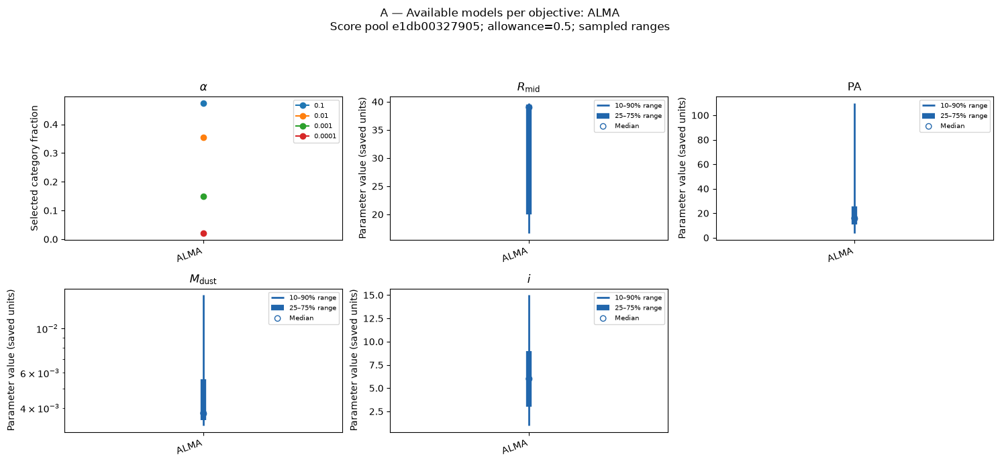

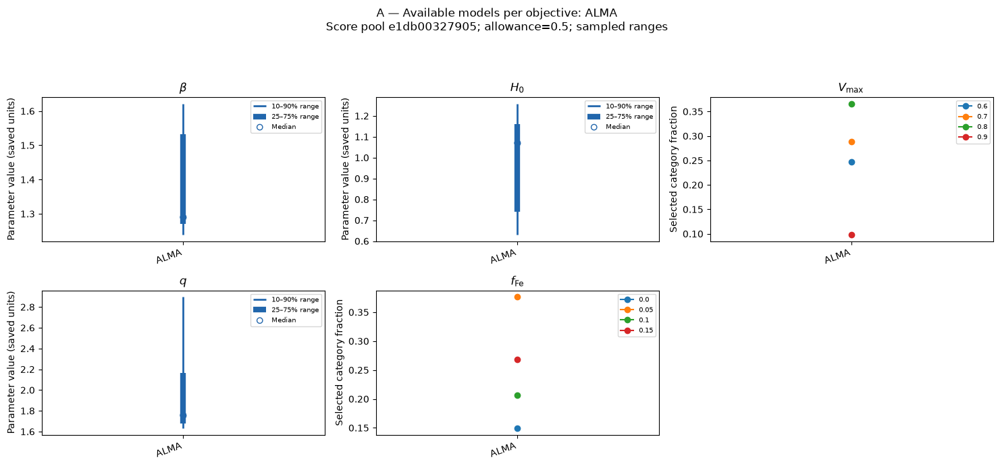

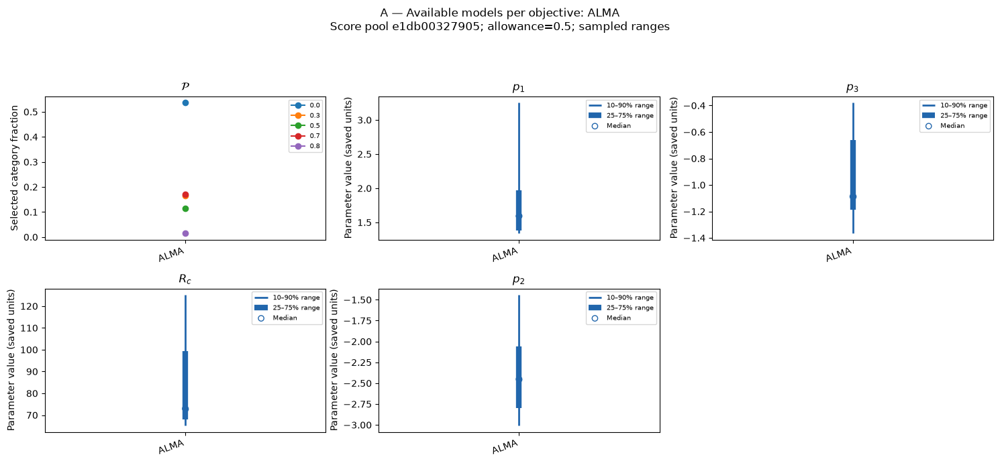

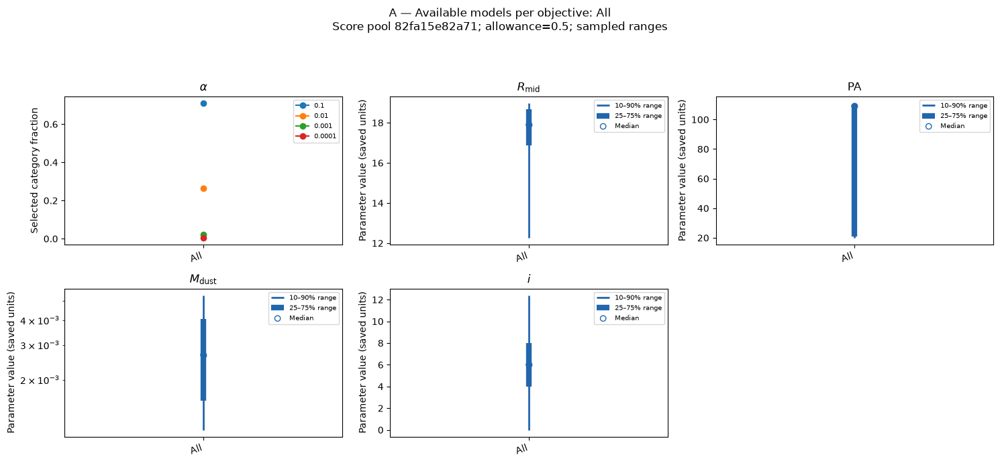

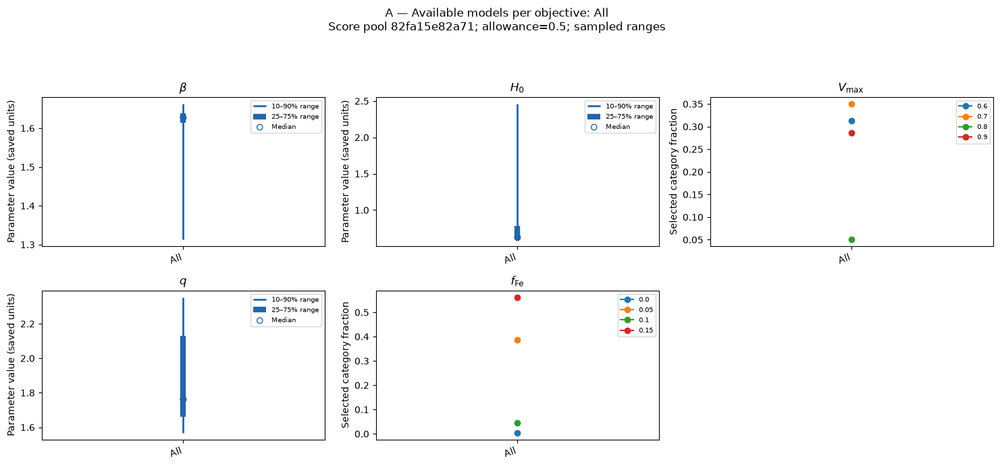

...

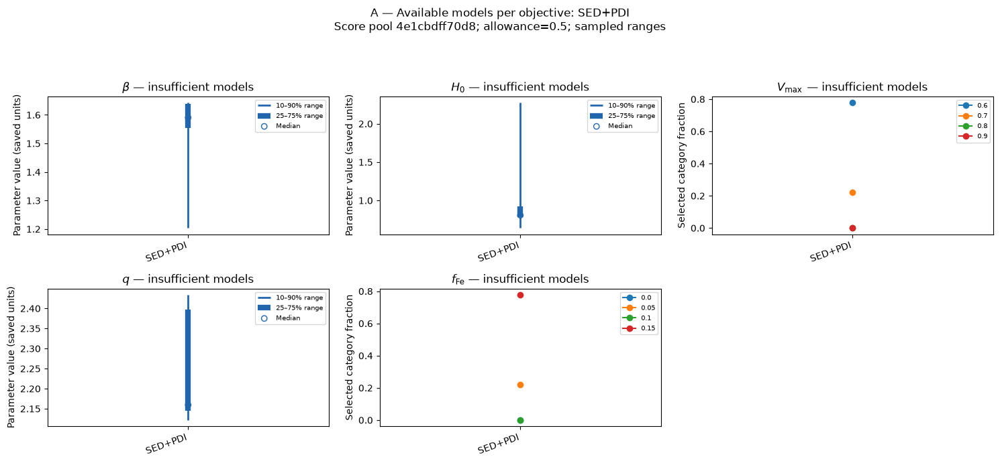

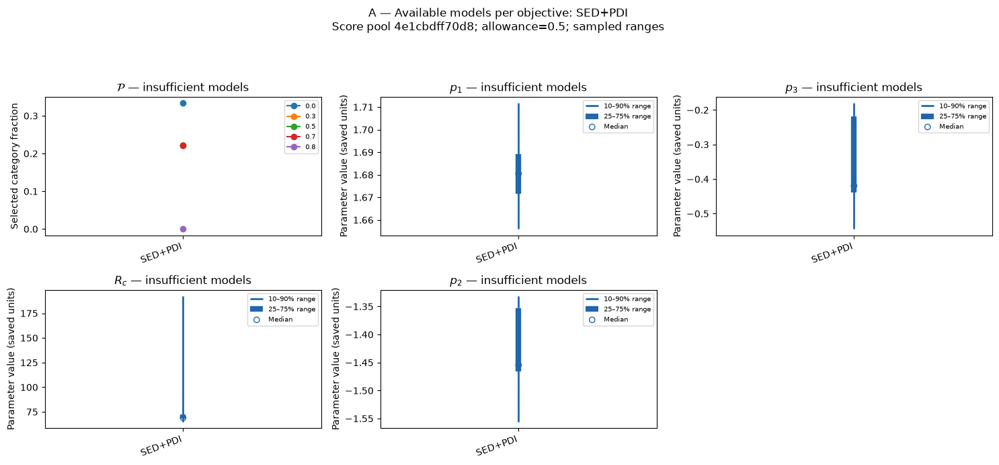

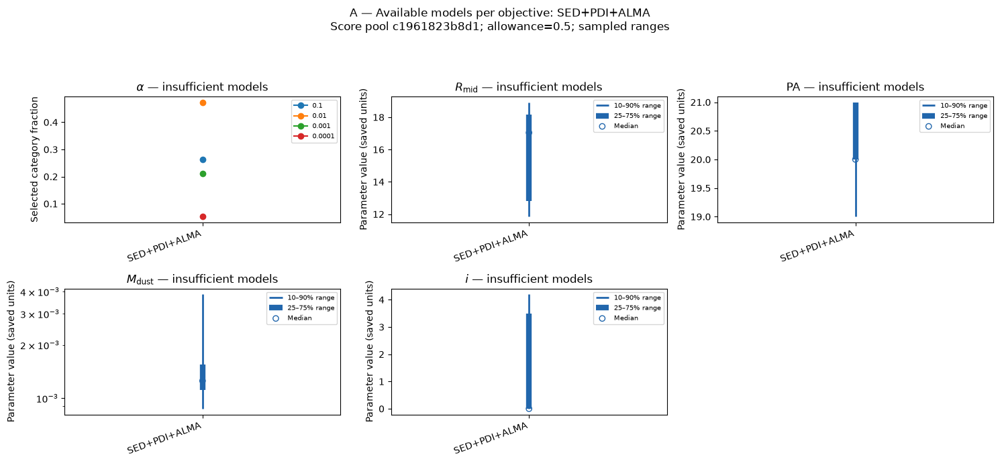

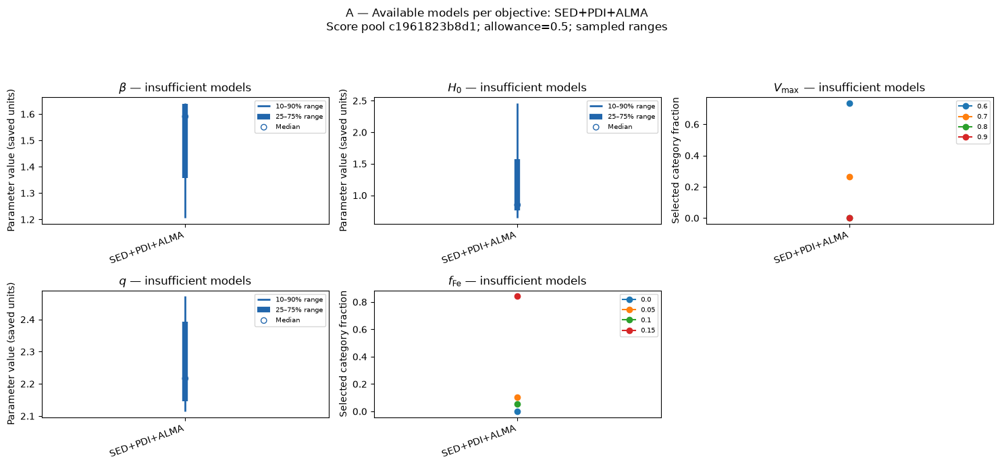

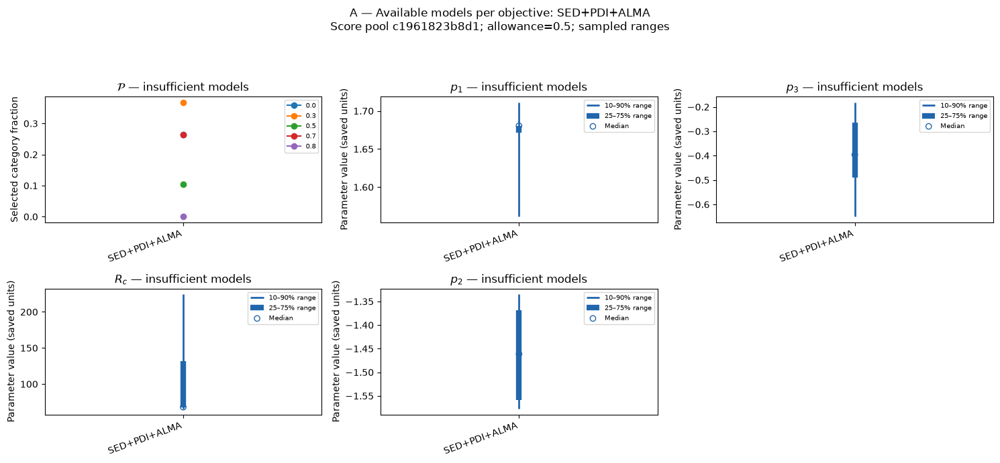

### B — Shared candidates for each comparison

**Winners**

,view,comparison,score_pool_key,selected_by,model_id,objective_score
14,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED,Model 6997,17.533823
15,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED+INT,Model 4644,135.999693
16,shared_per_comparison,SED → SED+PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,SED,Model 7371,22.960377
17,shared_per_comparison,SED → SED+PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,SED+PDI,Model 7861,116.273093
18,shared_per_comparison,SED → SED+PDI,4e1cbdff70d81329293a5f559525f770d7cf6cc96908f6...,SED,Model 6997,17.533823
19,shared_per_comparison,SED → SED+PDI,4e1cbdff70d81329293a5f559525f770d7cf6cc96908f6...,SED+PDI,Model 5547,105.760851
20,shared_per_comparison,SED → SED+ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,SED,Model 6997,17.533823
21,shared_per_comparison,SED → SED+ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,SED+ALMA,Model 6432,37.692370
22,shared_per_comparison,SED+INT → SED+INT+PDI,f5271aaa739160510807caf74c533e48aa8374451e3e0e...,SED+INT,Model 4644,135.999693
23,shared_per_comparison,SED+INT → SED+INT+PDI,f5271aaa739160510807caf74c533e48aa8374451e3e0e...,SED+INT+PDI,Model 5719,299.683274


**Counts**

,view,comparison,score_pool_key,objective,n_pool,n_selected,best_score,cutoff
304,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED,1891,116,17.533823,26.300734
305,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED+INT,1891,181,135.999693,203.999539
352,shared_per_comparison,SED → SED+PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,SED,498,11,22.960377,34.440565
353,shared_per_comparison,SED → SED+PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,SED+PDI,498,41,116.273093,174.409639
376,shared_per_comparison,SED → SED+PDI,4e1cbdff70d81329293a5f559525f770d7cf6cc96908f6...,SED,1394,108,17.533823,26.300734
377,shared_per_comparison,SED → SED+PDI,4e1cbdff70d81329293a5f559525f770d7cf6cc96908f6...,SED+PDI,1394,9,105.760851,158.641277
424,shared_per_comparison,SED → SED+ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,SED,1891,138,17.533823,26.300734
425,shared_per_comparison,SED → SED+ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,SED+ALMA,1891,306,37.692370,56.538554
472,shared_per_comparison,SED+INT → SED+INT+PDI,f5271aaa739160510807caf74c533e48aa8374451e3e0e...,SED+INT,1393,153,135.999693,203.999539
473,shared_per_comparison,SED+INT → SED+INT+PDI,f5271aaa739160510807caf74c533e48aa8374451e3e0e...,SED+INT+PDI,1393,192,299.683274,449.524911


**Metrics**

,view,comparison,score_pool_key,objective,parameter,n_pool,n_selected,supported,minimum_in_parameter_units,median_in_parameter_units,maximum_in_parameter_units,category_fractions,best_parameter_values
4560,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED,alpha_viscosity,1891,116,True,NaN,NaN,NaN,"{""0.1"": 0.6982758620689655, ""0.01"": 0.22413793...",[0.1]
4561,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED,disk_Rmid,1891,116,True,10.040751,17.997305,34.617200,NaN,[10.32218352775]
4562,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED,disk_pa,1891,116,True,0.000000,107.000000,177.000000,NaN,[22]
4563,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED,disk_total_dust_mass,1891,116,True,0.000300,0.002424,0.043994,NaN,[0.0010496503997]
4564,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,SED,inclination,1891,116,True,0.000000,7.000000,26.000000,NaN,[5]
...,...,...,...,...,...,...,...,...,...,...,...,...,...
14485,shared_per_comparison,INT+PDI+ALMA → All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,All,zone_1_species_1_porosity,1393,217,True,NaN,NaN,NaN,"{""0.0"": 0.16589861751152074, ""0.3"": 0.34562211...",[0.3]
14486,shared_per_comparison,INT+PDI+ALMA → All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,All,zone_1_surface_density_exp,1393,217,True,1.292193,3.069985,3.965594,NaN,[1.6805263778607]
14487,shared_per_comparison,INT+PDI+ALMA → All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,All,zone_2_-gamma_exp,1393,217,True,-1.574686,-0.834295,-0.104541,NaN,[-0.3731962003394]
14488,shared_per_comparison,INT+PDI+ALMA → All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,All,zone_2_Rc,1393,217,True,60.000000,70.000000,237.000000,NaN,[68]


**Effects**

,view,comparison,score_pool_key,parameter,supported,shift,width_ratio,sample_jaccard
30,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,alpha_viscosity,True,0.112879,NaN,0.247899
31,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,disk_Rmid,True,0.056089,0.466276,0.247899
32,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,disk_pa,True,0.053517,0.994475,0.247899
33,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,disk_total_dust_mass,True,0.021032,1.167603,0.247899
34,shared_per_comparison,SED → SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,inclination,True,0.024677,1.076923,0.247899
...,...,...,...,...,...,...,...,...
4990,shared_per_comparison,INT+PDI+ALMA → All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,zone_1_species_1_porosity,True,0.075711,NaN,0.688976
4991,shared_per_comparison,INT+PDI+ALMA → All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,zone_1_surface_density_exp,True,0.014962,1.002088,0.688976
4992,shared_per_comparison,INT+PDI+ALMA → All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,zone_2_-gamma_exp,True,0.018343,1.000037,0.688976
4993,shared_per_comparison,INT+PDI+ALMA → All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,zone_2_Rc,True,0.043123,11.616667,0.688976


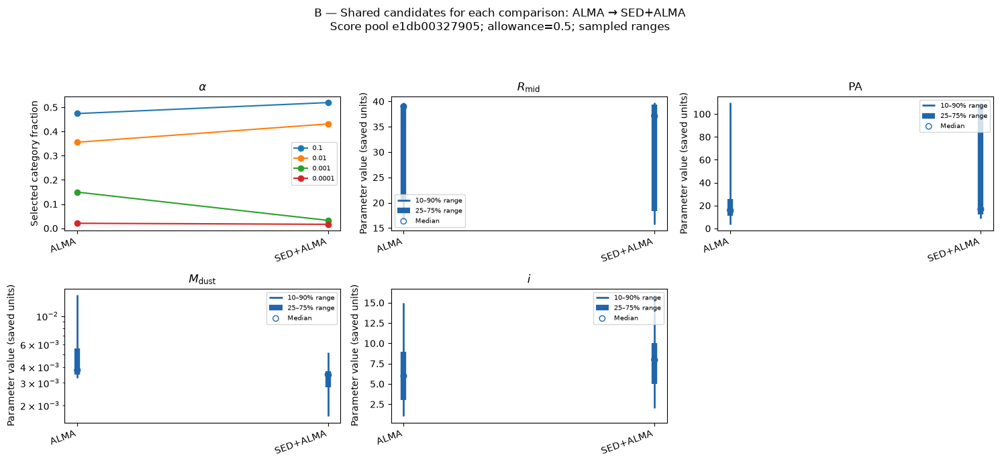

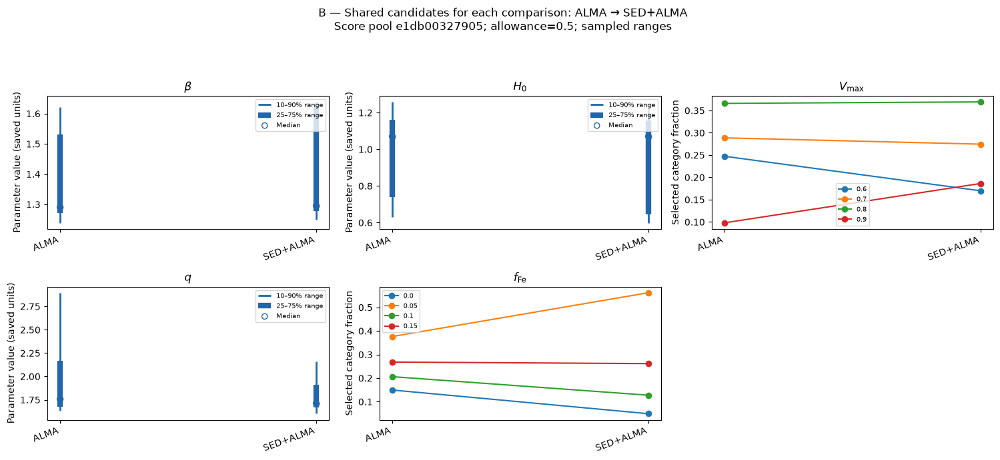

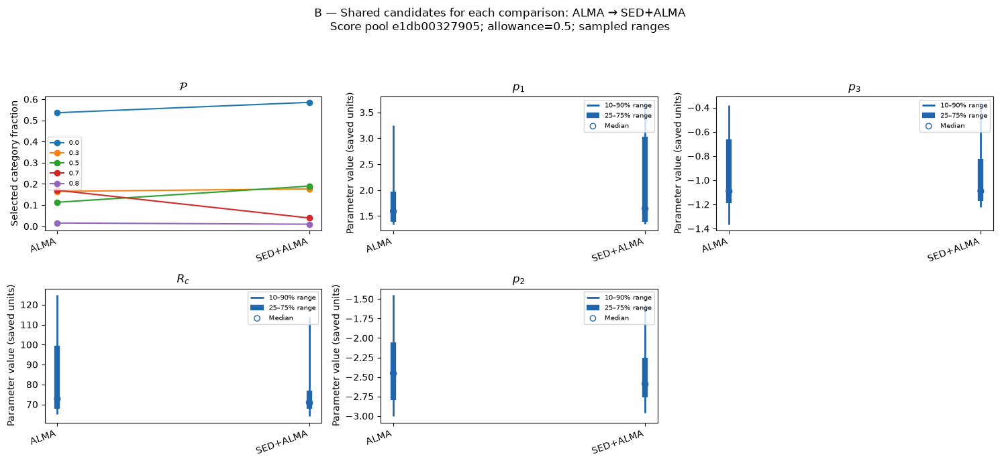

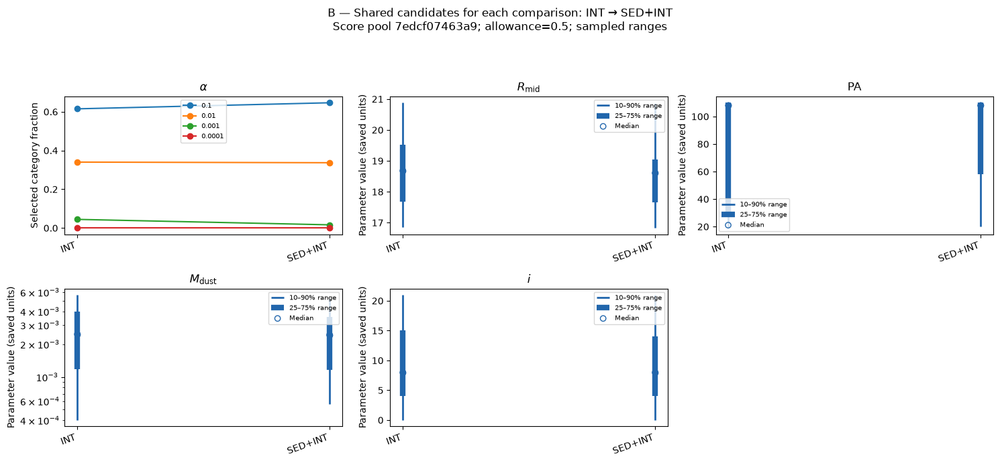

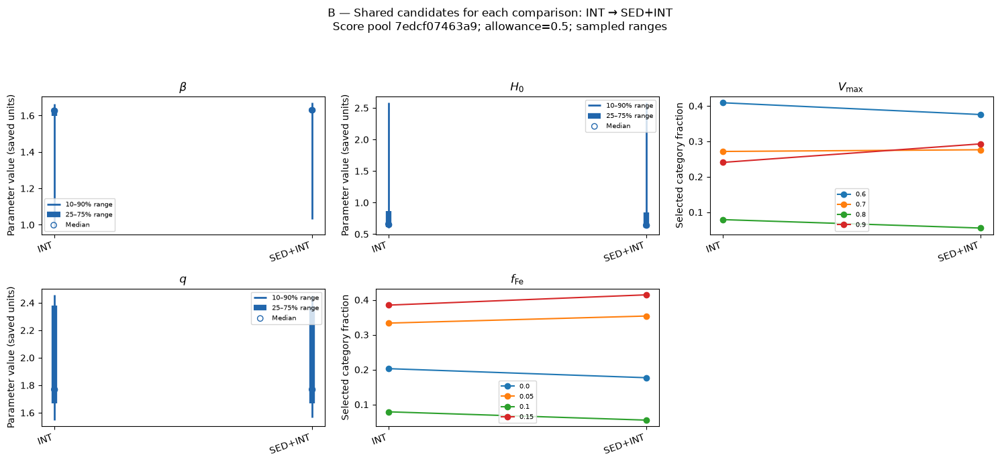

...

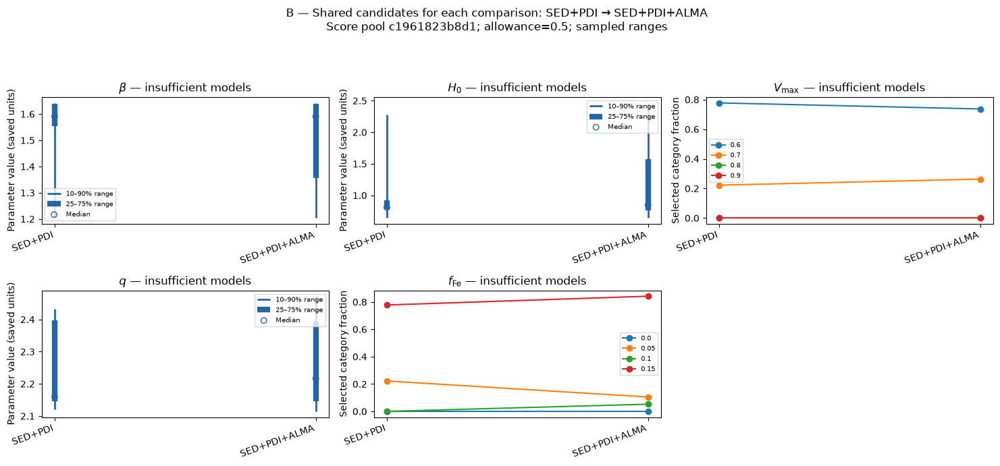

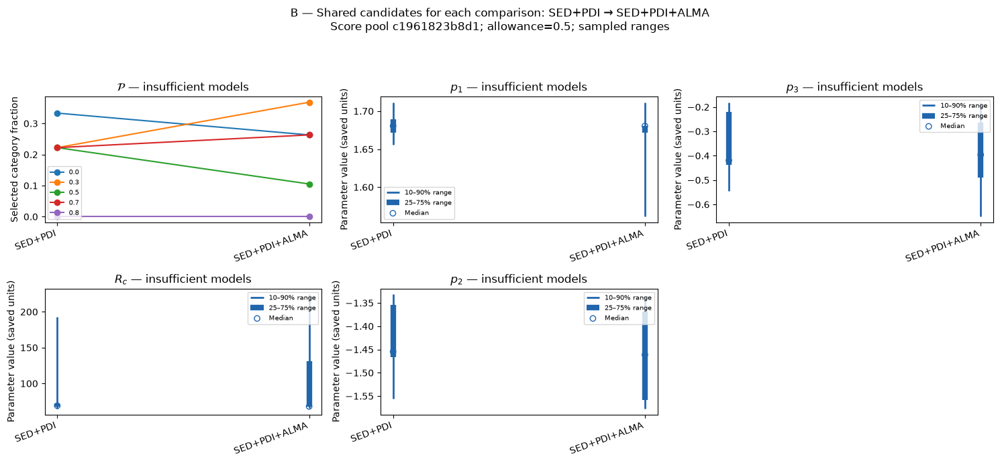

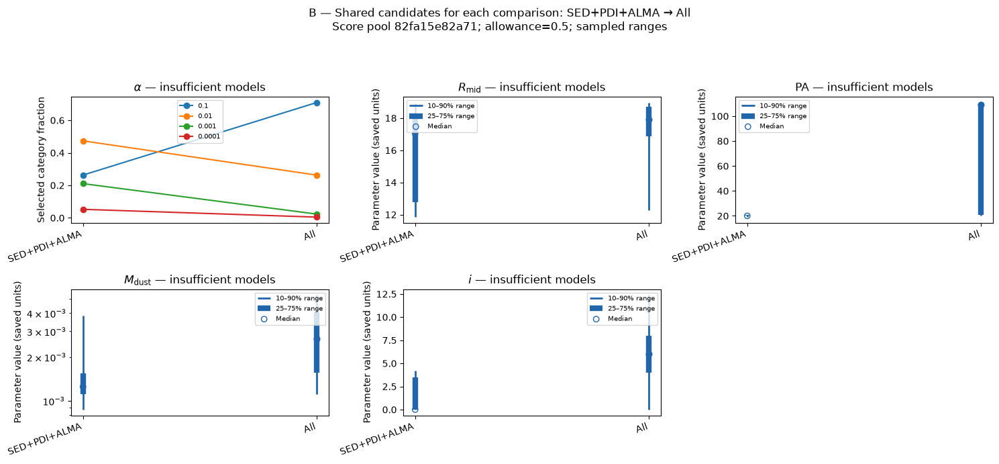

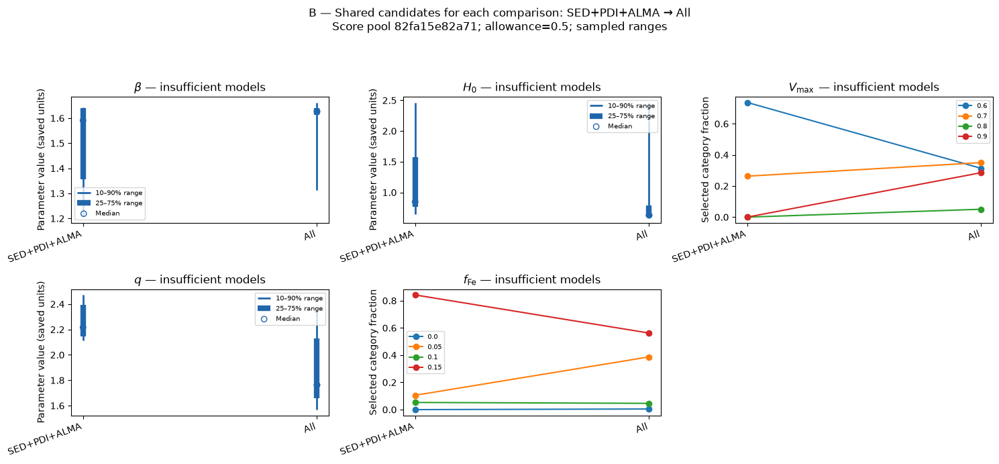

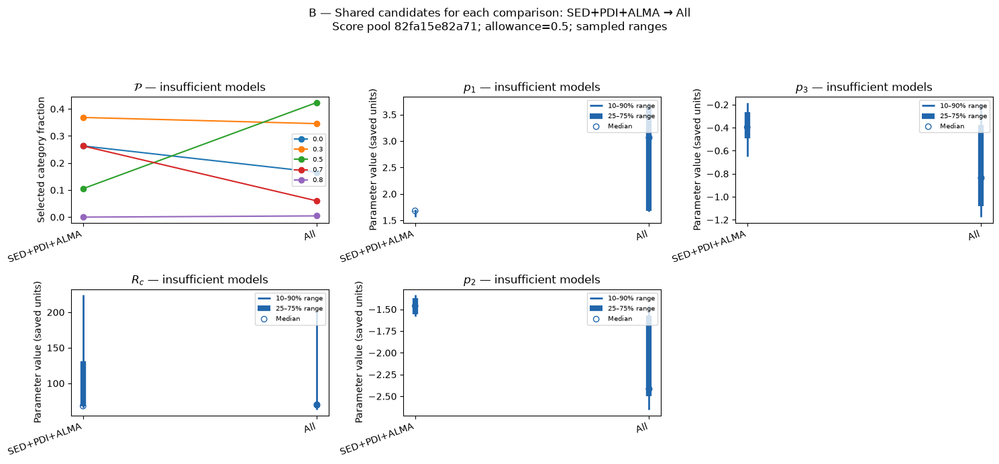

In [18]:
eligible_candidates = eligible_pool_candidates(evaluations, inventory, records)
if eligible_candidates.empty:
    raise ValueError('No eligible final-budget evaluations with known physical metadata and consistent native costs.')
physical_pool_inventory = eligible_candidates.groupby('physical_pool').agg(
    n=('evaluation_id','size'), unique_parameters=('parameter_hash','nunique'),
    histories=('history','nunique'), physical_pool_key=('physical_pool_key','first'))
display(physical_pool_inventory)
selected_physical_pool = POOL_ID if POOL_ID is not None else physical_pool_inventory.n.idxmax()
if selected_physical_pool not in physical_pool_inventory.index:
    raise ValueError('POOL_ID must match a Physical pool label in physical_pool_inventory.')
base_candidates = eligible_candidates.loc[
    eligible_candidates.physical_pool.eq(selected_physical_pool)].copy().reset_index(drop=True)
definitions = {item['name']:item for item in configspaces[base_candidates.history.iloc[0]]['hyperparameters']}
view_parameters = PARAMETERS if PARAMETERS is not None else [c[7:] for c in base_candidates
    if c.startswith('param__') and definitions.get(c[7:],{}).get('type') != 'constant'
    and base_candidates[c].nunique(dropna=True)>1
    and not base_candidates[c].dropna().map(lambda x:isinstance(x,str) and 'param__'+x in base_candidates).any()]
view_references = {name:parameter_reference(base_candidates,name,definitions[name],
    period=None,bins=HISTOGRAM_BINS) for name in view_parameters}
view_selection_levels = {'allowance':sorted(set(RELATIVE_ALLOWANCES+[DISPLAY_ALLOWANCE])),
                         'fraction':sorted(set(MATCHED_FRACTIONS+[DISPLAY_FRACTION]))}
pool_views = analyse_pool_views(base_candidates,records,objective_design(),definitions,
    view_references,view_selection_levels,ABSOLUTE_ALLOWANCE,MIN_MODELS)
display(pool_views['availability'])
for view, label in [('available_per_objective','A — Available models per objective'),
                    ('shared_per_comparison','B — Shared candidates for each comparison')]:
    display(Markdown('### '+label))
    for name in ['winners','counts','metrics','effects']:
        table=pool_views[name]
        if table.empty:continue
        table=table.loc[table.view.eq(view)]
        if 'scope' in table:
            table=table.loc[table.scope.eq('pooled') & table['mode'].eq('allowance')
                            & np.isclose(table.level,DISPLAY_ALLOWANCE)]
        columns=[c for c in ['view','comparison','score_pool_key','selected_by','model_id',
            'objective_score','objective','parameter','n_pool','n_selected','supported','best_score',
            'cutoff','minimum_in_parameter_units','median_in_parameter_units','maximum_in_parameter_units',
            'category_fractions','best_parameter_values','shift','width_ratio','sample_jaccard'] if c in table]
        display(Markdown('**'+name.capitalize()+'**'))
        display(table[columns])
    data=pool_views['metrics']
    if data.empty:continue
    data=data.loc[data.view.eq(view) & data.scope.eq('pooled')]
    for group_index,((comparison,key),rows) in enumerate(data.groupby(['comparison','score_pool_key']),1):
        order={name:i for i,name in enumerate(rows.objective.unique())}
        rows=rows.assign(step=rows.objective.map(order),subset=rows.objective)
        for first in range(0,len(view_parameters),5):
            fig=plot_restriction(rows,view_parameters[first:first+5],'allowance',DISPLAY_ALLOWANCE)
            if fig is not None:
                fig.suptitle(f'{label}: {comparison}\nScore pool {key[:12]}; allowance={DISPLAY_ALLOWANCE:g}; sampled ranges')
                fig.tight_layout(rect=(0,0,1,.92))
            show(f'{view}_{group_index:02d}_{first}',fig)
# Full tables retain both selection modes, every allowance and within-history controls.


## View A — cost versus every varied parameter

Each figure belongs to **one objective and one compatible score pool**. Every independently varied model parameter is shown in a subplot; figures continue onto additional pages. These plots do not apply a top-N model filter. They include all candidates in that pool, even when other observable scores are missing.

- **Grey:** all evaluations. **Light blue:** within 100% of the best cost. **Blue:** within 50%. **Orange:** within 10%. Selections are nested; orange is drawn last. Legend counts are cumulative, not disjoint categories.
- Cutoffs are exactly `best + allowance × abs(best)` for allowances 0.1, 0.5 and 1.0. For positive costs these are 1.1, 1.5 and 2 times the best cost. No absolute slack is added in these panels. If best cost is zero, all three cutoffs equal zero. Dashed lines show the actual cutoffs.
- The vertical axis shows the objective's original summed cost, logarithmically when all costs are positive. Numeric parameters use saved values or log10 coordinates as labelled; categories occupy separate equally spaced slots. Missing/invalid parameter values are omitted only from their panel, with valid counts shown.
- Pool counts, unique configurations and source histories document coverage. Repeated evaluations remain separate and can overlap. The exported coverage and cutoff tables make the displayed selections auditable.

**Interpretation:** these plots represent the available saved evaluations, which were sampled adaptively by the optimiser. Dense regions are not posterior probability, and 10%/50%/100% allowances are not confidence levels. Read them alongside the matched-fraction and within-history checks in views A/B; neither colour nor sample count alone establishes statistical representativeness.


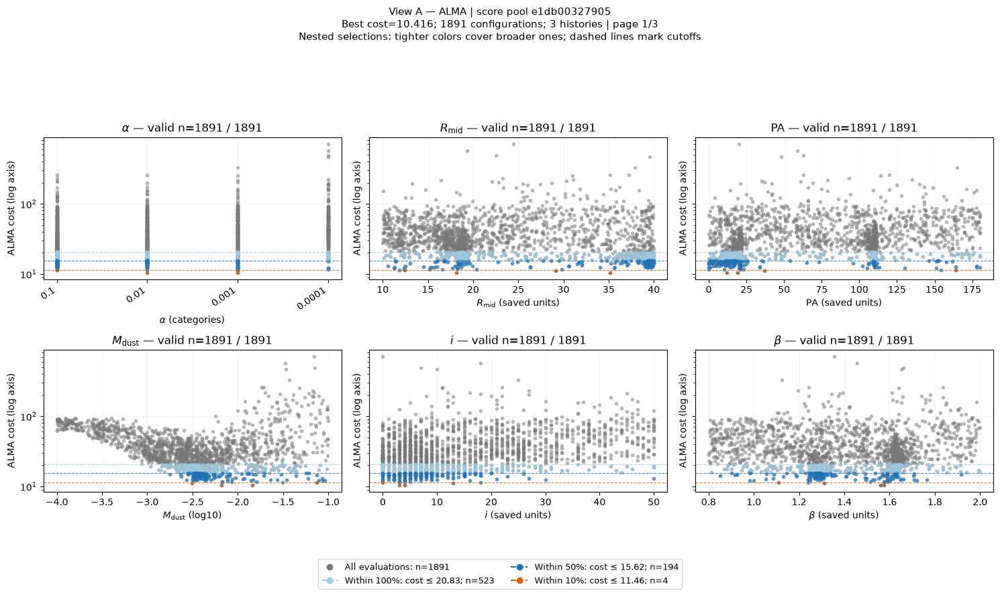

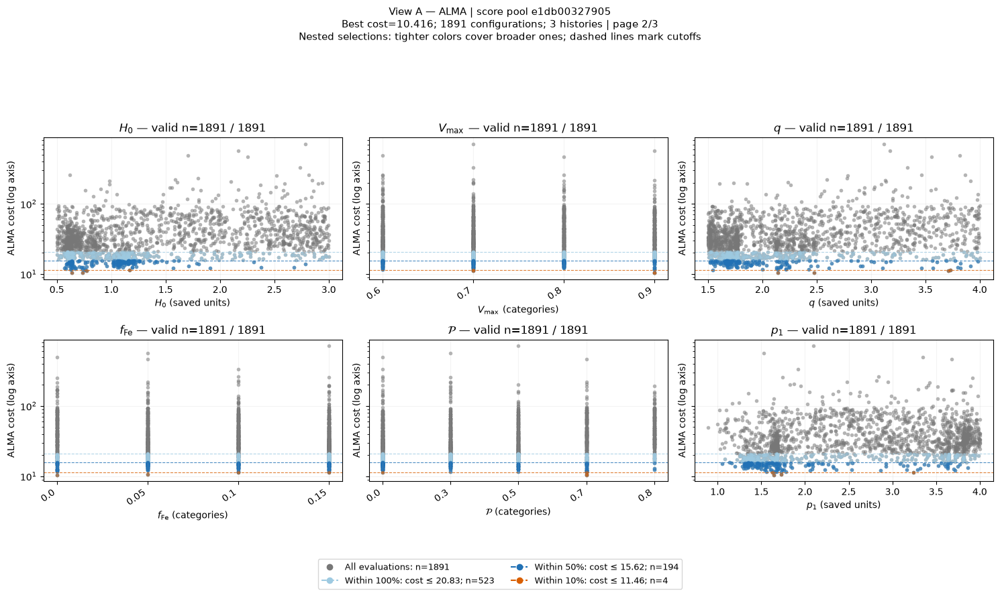

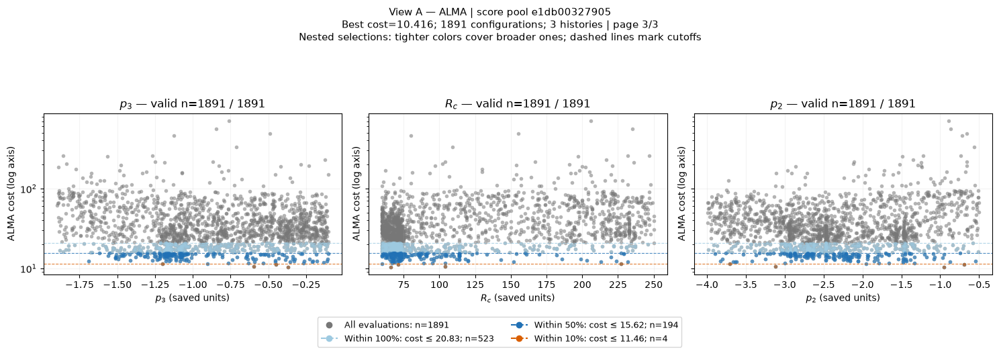

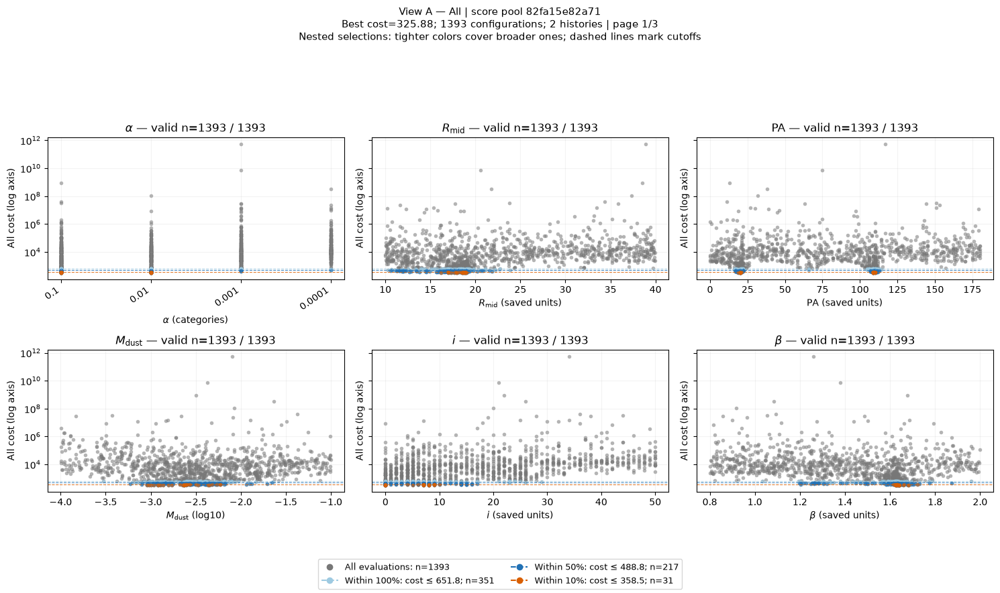

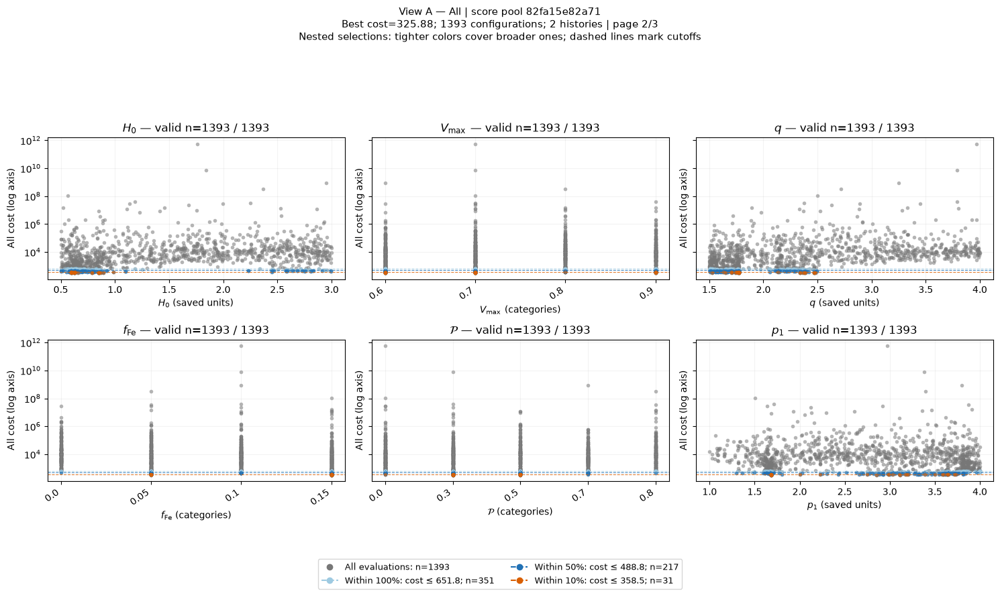

...

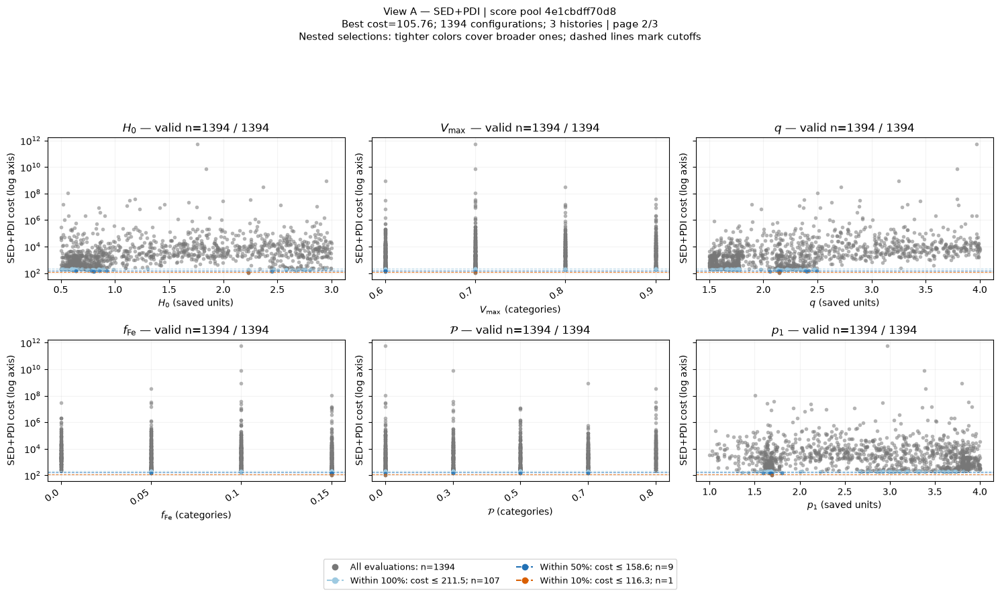

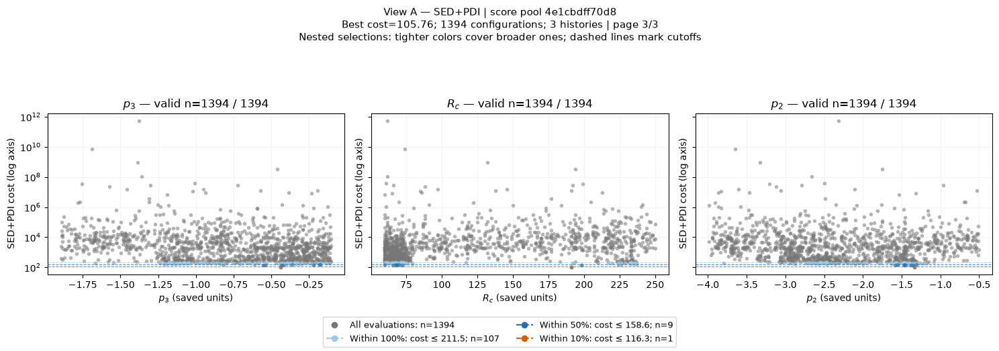

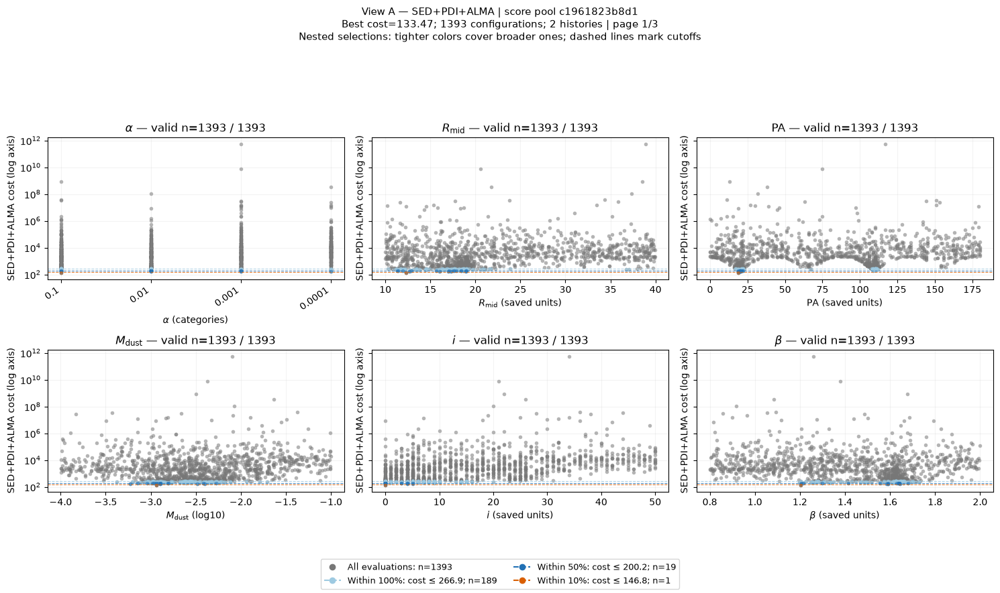

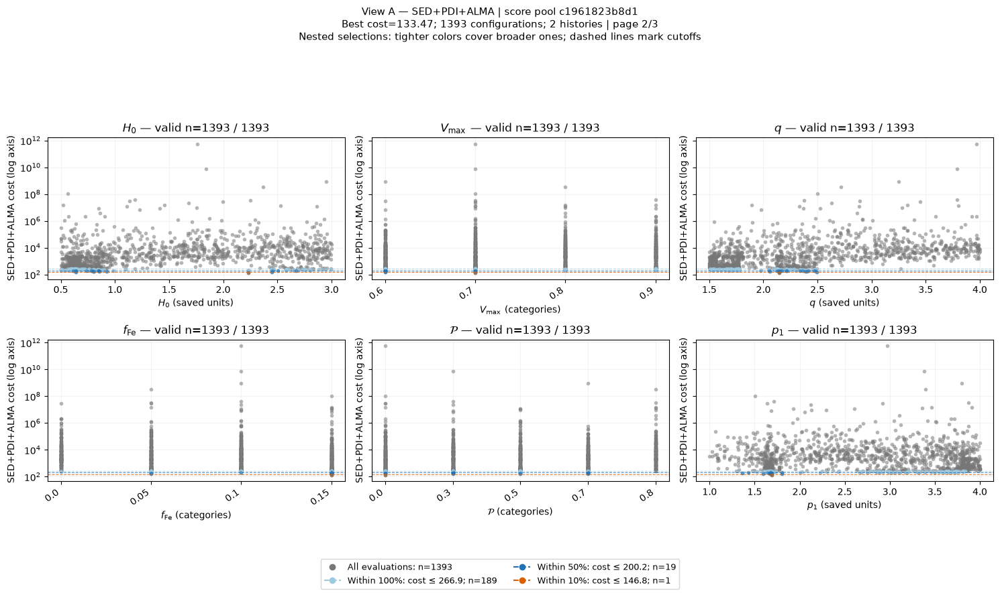

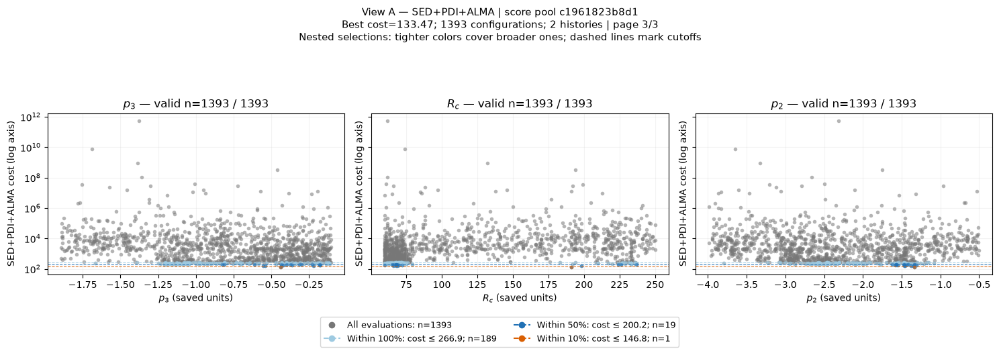

,objective,score_pool_key,allowance,best_score,cutoff,n_pool,n_selected,n_unique_configurations,n_histories
0,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,1.0,10.415510,20.831021,1891,523,1891,3
1,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,0.5,10.415510,15.623265,1891,194,1891,3
2,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,0.1,10.415510,11.457061,1891,4,1891,3
3,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,1.0,325.883644,651.767289,1393,351,1393,2
4,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,0.5,325.883644,488.825467,1393,217,1393,2
5,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,0.1,325.883644,358.472009,1393,31,1393,2
6,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,1.0,117.368670,234.737339,1891,482,1891,3
7,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,0.5,117.368670,176.053004,1891,291,1891,3
8,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,0.1,117.368670,129.105537,1891,60,1891,3
9,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,1.0,275.494709,550.989418,1393,357,1393,2


In [19]:
# Use all independent varied model parameters, even if PARAMETERS filters other summaries.
cost_parameters = [c[7:] for c in base_candidates if c.startswith('param__')
    and c[7:] in definitions and definitions[c[7:]].get('type') != 'constant'
    and not base_candidates[c].dropna().map(lambda x:isinstance(x,str) and 'param__'+x in base_candidates).any()]
cost_references = {name:parameter_reference(base_candidates,name,definitions[name],
    period=None,bins=HISTOGRAM_BINS) for name in cost_parameters}
cost_cutoff_parts, cost_coverage_parts = [], []
view_a_members = pool_views['members']
if not view_a_members.empty:
    view_a_members = view_a_members.loc[view_a_members.view.eq('available_per_objective')]
    for group_index,((objective,key),candidates) in enumerate(
            view_a_members.groupby(['comparison','score_pool_key'],sort=True),1):
        candidates=candidates.reset_index(drop=True)
        pages,cutoffs,coverage_rows=plot_available_pool_costs(candidates,objective,
            objective_design()[objective],cost_references,VIEW_A_COST_ALLOWANCES,
            VIEW_A_PANELS_PER_PAGE,POINT_SIZE,POINT_ALPHA)
        cost_cutoff_parts.append(cutoffs);cost_coverage_parts.append(coverage_rows)
        for page,fig in enumerate(pages,1):
            show(f'available_per_objective_costs_{group_index:02d}_{page:02d}',fig)
pool_views['cost_cutoffs']=pd.concat(cost_cutoff_parts,ignore_index=True) if cost_cutoff_parts else pd.DataFrame()
pool_views['cost_panel_coverage']=pd.concat(cost_coverage_parts,ignore_index=True) if cost_coverage_parts else pd.DataFrame()
display(pool_views['cost_cutoffs'])


## View A — score-weighted available-model distributions (ChainConsumer)

**What is plotted.** For each objective and compatible score pool, start from its eligible final-budget evaluations and retain the **lowest-scoring 40%**, controlled by `SCORE_WEIGHTED_RETAIN_FRACTION=0.40`. The cutoff is the score of the ceil(0.40 × N)-th ranked evaluation; include all ties at that score, so the realised fraction may be slightly larger. This means the best 40% **by count**, not scores within 40% of the minimum. Ranking is performed independently for every objective/compatibility pool, before parameter-completeness checks.

The cloud, contours, marginal distributions and categorical bars all use this selected subset. Assign equal baseline mass to each retained evaluation, then tilt those masses towards better original scores and normalise over retained evaluations only:

\[
w_i(T)=\frac{\exp[-(J_i-J_{\min})/T]}{\sum_j\exp[-(J_j-J_{\min})/T]}.
\]

This is a discrete Gibbs distribution on the **retained best-scoring evaluations**. It can be called a *quasi-posterior conditional on the evaluated pool*. It is not a posterior over continuous physical parameter space: SMAC's adaptive sampling density, unequal history sizes, missing score availability and repeated configurations remain influential. No physical prior or proposal-density correction is applied. Repeats stay separate, exactly as in View A; a frequently evaluated configuration receives extra total mass. Simulation noise can also favour an unusually low-scoring repeat. Compare with the existing within-history diagnostics.

**Define temperature by a score difference, not by the name of the observable.** Choose a positive score increase \(\Delta J_{1/2}\) that should halve an individual evaluation's weight relative to a best-scoring evaluation:

\[
\frac{w(J_{\min}+\Delta J_{1/2})}{w(J_{\min})}=\tfrac12,
\qquad T=\frac{\Delta J_{1/2}}{\ln 2}.
\]

At twice that increase, the weight is one quarter of the best evaluation's weight. This is a weight **ratio**, not a statement that a model has 50% probability. Larger T gives broader weighting; smaller T concentrates on the best fits. T has the same units/scale as the selected original objective.

**Default sensitivity experiment:** `SCORE_WEIGHTED_HALF_WEIGHT_FRACTIONS = (0.10, 0.25, 0.50)` sets \(\Delta J_{1/2}=f|J_{\min}|\), separately for each objective/pool. For positive scores these correspond to half weight at 1.10, 1.25 and 1.50 times the best cost. These values align with existing descriptive allowances; they are not calibrated error bars. The exported table records every numerical delta and T. This rule depends on the best score and its zero point: adding a constant to all scores changes this relative rule. For comparisons across pool snapshots, use a fixed, justified absolute delta. With fixed absolute delta, adding a constant to all scores leaves weights unchanged. A zero best score requires an absolute override; the notebook reports and skips that pool rather than inventing a temperature.

| Objective | Meaning of the saved score | How to choose an explicit descriptive delta |
|---|---|---|
| PDI | Sum over saved bands of empirically weighted fraction, radial-profile and quadrant squared differences; the current caller uses weights 1e5, 1e4 and 5e3. There is no measurement covariance model. | Choose an acceptable increase in the **total saved PDI score**, preferably after inspecting synthetic images/profiles at those increases. Use the relative sensitivity experiment until an absolute tolerance is justified. A tolerance for one component cannot automatically calibrate the whole PDI score. |
| ALMA | Current loss is \(J=100\sum(M-D)^2/\sum D^2\) in the aperture. It is residual energy relative to observed energy, not a noise-normalised chi-square. | A delta of 1 score unit means an increase of 0.01 in the residual-energy ratio (one percentage point), giving T=1/ln(2)≈1.443. This is an illustrative tolerance, not a measured uncertainty and not 1% flux error. Choose a tolerance using residual-map acceptability with a fixed aperture/normalisation. |
| Combined objectives | The original sum of included score terms. | Apply **one** T to that original sum. Separate PDI/ALMA temperatures in the exponent would change their relative influence and define a different objective; that is not done here. |

For example, **if** the best PDI score were 20, the 10% setting gives delta=2 and T≈2.885; scores 22 and 24 receive respectively half and one quarter of the best evaluation's weight. **If** the best ALMA score were 8, it gives delta=0.8 and T≈1.154. These are arithmetic examples, not results from this pool. Absolute overrides use `SCORE_WEIGHTED_ABSOLUTE_DELTAS = {'PDI': [2., 5., 10.], 'ALMA': [1., 2., 4.]}`; substitute scientifically justified tolerances. A key `(objective, full_score_pool_key)` overrides that objective's general choice for just one pool.

**SED and interferometry: chi-square-based scores are not automatically likelihood weights.** The current SED code computes \(J_{\rm SED}=\chi^2_{\rm SED}/(N_{\rm SED}-1)\). With fixed Gaussian errors, fixed observations and the same nuisance-parameter treatment, likelihood ratios use
\[
w_i\propto\exp[-\tfrac12\Delta\chi_i^2]
=\exp[-\tfrac12(N_{\rm SED}-1)\Delta J_i].
\]
Thus a temperature on the reduced SED score would be \(T=2/(N_{\rm SED}-1)\), not the relative half-weight temperatures used here. Here N−1 is the actual code normalisation, not a claim about correct residual degrees of freedom. Interferometry sums separate instrument scores \(J_k=\chi_k^2/(N_k-1)\); the fixed-error Gaussian exponent would be \(-\frac12\sum_k(N_k-1)J_{k,i}\), up to a common subtraction for numerical stability. A single T multiplying \(\sum_kJ_k\) generally cannot reproduce this when instrument counts differ. SED+INT needs the unreduced terms from every included dataset, with compatible masks and data versions. This would change their influence relative to the optimisation loss and must be an explicitly separate weighting mode.

Both scoring functions also compute a Gaussian log-likelihood with variance normalisation; use validated per-component log-likelihoods when errors depend on the model (e.g. a model-dependent systematic term), because chi-square alone then omits a varying term. Optimised extinction/background parameters yield a profiled construction, not nuisance-marginalised Bayesian inference. Covariance assumptions and adaptive pool sampling still matter. **The current 10%/25%/50% weights are descriptive for SED and INT as well as PDI and ALMA; the style update does not convert them to Gaussian likelihood weights.** See the current implementations in [obriy_sed.py](../../lib/obriy_sed.py) and [obriy_interferometry.py](../../lib/obriy_interferometry.py); historical scores require their own provenance checks.

**For calibrated physical uncertainty:** scalar saved PDI/ALMA scores alone are insufficient to infer T. Use a validated observation-noise/model-discrepancy model (including beam/pixel and overlapping-summary correlations), or calibrate a declared generalized-posterior procedure using synthetic-data recovery across known truths and repeated noisy observations. Repeat simulations measure numerical scatter, not the entire observational uncertainty, so their score scatter alone is not a calibrated T. Even calibrated temperatures would not correct the adaptive pool's sampling measure. The current scoring conventions do not justify setting T=2.

**Reference style (default).** The layout follows the supplied ChainConsumer example: one black contour set, magma-coloured evaluation points, top/right marginal curves for a two-parameter plot (`flip=True`), shaded marginal ranges, and a star plus burgundy dashed reference lines. `SCORE_WEIGHTED_PARAMETERS=None` includes all independent varied parameters, regardless of the `PARAMETERS` filter used by other summaries. Parameters are split by physical origin, with a numeric corner (or one-dimensional marginal) and categorical weighted bars for each nonempty group:

- **Disc geometry and orientation:** radii, radial density exponents, scale height, flaring, inclination and position angle. `disk_Rmid` belongs here once.
- **Dust distribution, settling and heating:** total dust mass and `alpha_viscosity` (alpha controls both settling and viscous heating in seed1).
- **Grain properties and composition:** grain-size limits/exponent, DHS void fraction, material porosity and iron fraction.

Stellar or numerical-grid parameters receive separate groups if independently varied; unknown names remain visible in **Other parameters**. `SCORE_WEIGHTED_PARAMETER_GROUPS` accepts an explicit mapping to customise these groups; duplicate assignments are rejected. The grouping table is displayed and exported as `score_weighted_parameter_groups`. Only within-group parameter pairs are shown; cross-group correlations are not displayed.

**Seed1 alignment:** checked against `smac/1_tapered_2zones_dubrulle/lower_precision/seed1/*/configuration_tapered.yaml`, launch flags and the parameter writer. Its 18 free parameters split 10/2/6 across the three groups above. `inclination` drives both `imin` and `imax`; zone boundaries and masses are derived; scale height/flaring and grain properties are shared between zones; the outer taper exponent is tied to the outer density slope. These are not added as independent axes. Types come from each pool's recorded definitions: seed1 has continuous `Vmax`/porosity and categorical alpha/iron fraction; older runs can have different types and an independently varied taper exponent. This grouping does not switch `RUN_FOLDERS` or mix different physical pools.

 Constant/unavailable parameters are reported in coverage. Set an explicit parameter list only when a smaller view is wanted. For more than three numeric parameters, contours use thinner lines and omit repeated inline percentage labels to keep the coloured points visible; contour masses remain listed in the figure title.

`SCORE_WEIGHTED_REFERENCE_SETTING=None` selects the middle configured weighting (25% half-weight increase with the defaults); an explicit ID such as `'half_weight_01'` selects another. Every configured weight table and temperature diagnostic is computed on that subset. `score_weighted_selection` records counts, realised fractions and cutoffs; `score_weighted_membership` records every candidate ID and its retention flag. Figure titles report the selection and cutoff. Contour percentages refer to weight inside this selected subset, not the full eligible pool. Set the retain fraction to 1.0 to restore all eligible evaluations. `SCORE_WEIGHTED_STYLE='sensitivity'` restores the multi-temperature overlay. Both styles use the same selected subset and renormalised weights. The reference style does not remove T or replace the weights with likelihood weights.

- Point colour is the **original objective score**, labelled “lower is better”. `SCORE_WEIGHTED_COLOR_SCALE='auto'` uses a logarithmic colour scale when plotted scores are positive and varying, and a linear scale otherwise. The colourbar reports the actual scale and retains original score values. Magma is restricted to its brighter 20–95% portion so the best models are purple rather than nearly black. The full score range of the selected subset is used for colour, with no additional percentile clipping; weights and contours are unchanged. Use `'linear'` to restore linear scaling or `'log'` to require positive scores. The score is not chi-square unless the selected original score actually is chi-square. Equal-size cloud points show evaluated locations, not a resampling from the weights; point density therefore still reflects the SMAC search.
- Black contours enclose approximately **68%, 95%, and 99.7% of the smoothed plotted weight**. These are not calibrated confidence levels. Chains use `multimodal=True` and `statistics=SummaryStatistic.HDI`. Marginal shading shows 68% highest-density bands of the smoothed plotted distribution, which may split into separate intervals. The 68% refers to the bands together, not to each band; these are descriptive pool weights, not calibrated uncertainty. `score_weighted_coverage` exports one row per band with `lower`, `center`, `upper`, `center_kind`, `band_index` and `n_bands`; `center` is not the overall marginal median. For a single band the library falls back to its contiguous HDI summary.
- Star/dashes identify the **best displayed evaluation by original score**, not a known physical truth and not the vector of marginal medians. Ties choose the first evaluation ID in sorted order; its ID, score and tie count are exported. ChainConsumer's `Truth` object is used only to draw these reference lines. A separate negative-score ranking column locates the star; it is not a log posterior or likelihood.
- `SCORE_WEIGHTED_SMOOTH=2` enables Gaussian histogram smoothing for the visual style; `0` shows raw histograms. No KDE is used. Smoothing changes the displayed density estimates and marginal summaries, not input weights or original scores; check sensitivity to this setting. It does not establish support in unevaluated regions or force Gaussian/elliptical shapes.
- Linear/log10 coordinate conventions are preserved, PA remains linear, and the log-coordinate intervals describe log10 values. Constant parameters are listed in coverage. The star is one actual model; a vector of median values need not be a simulated model.

All physical groups use the same best-40% selection and weights, with a shared complete-case mask over every selected varying numeric parameter. Thus splitting the figure does not change the models, best-model reference or score-colour range between numeric groups. Weights are renormalised on this shared subset; omitted weight and counts are reported per group. Categorical bars use this same numeric mask and additionally require their own category value to be valid. Floating-point underflow can make negligible weights zero: these rows remain in the exported weight table and are omitted only from ChainConsumer's strictly-positive-weight input. `evaluation_weight_ess = 1/sum(w_i**2)` and its configuration-aggregated analogue quantify concentration, **not** independence, MCMC convergence or inferential accuracy. A selected temperature's corner curves are suppressed when either plotted weight ESS is below `SCORE_WEIGHTED_MIN_ESS`; the weights and diagnostics remain available. Changing this threshold does not make sparse coverage trustworthy.

View-A curves from different objectives can have different candidates and different temperature scales. Their widths cannot establish the effect of adding observations; use View B for same-candidate comparisons. Source metadata compatibility still has the limitations documented above.

**Dependency:** in the active notebook kernel, run `%pip install chainconsumer==1.3.0` once if needed (restart the kernel if requested). This is a plotting dependency; weighting and original analysis helpers do not require it. [ChainConsumer weights](https://samreay.github.io/ChainConsumer/api/chain/) and [plot configuration](https://samreay.github.io/ChainConsumer/api/plotconfig/).


,parameter_group,parameter,coordinates
0,Disc geometry and orientation,inclination,linear
1,Disc geometry and orientation,disk_pa,linear
2,Disc geometry and orientation,disk_Rmid,linear
3,Disc geometry and orientation,zone_1_scale_height,linear
4,Disc geometry and orientation,zone_1_flaring_exp,linear
5,Disc geometry and orientation,zone_1_surface_density_exp,linear
6,Disc geometry and orientation,zone_2_Rc,linear
7,Disc geometry and orientation,zone_2_surface_density_exp,linear
8,Disc geometry and orientation,zone_2_-gamma_exp,linear
9,"Dust distribution, settling and heating",disk_total_dust_mass,log10


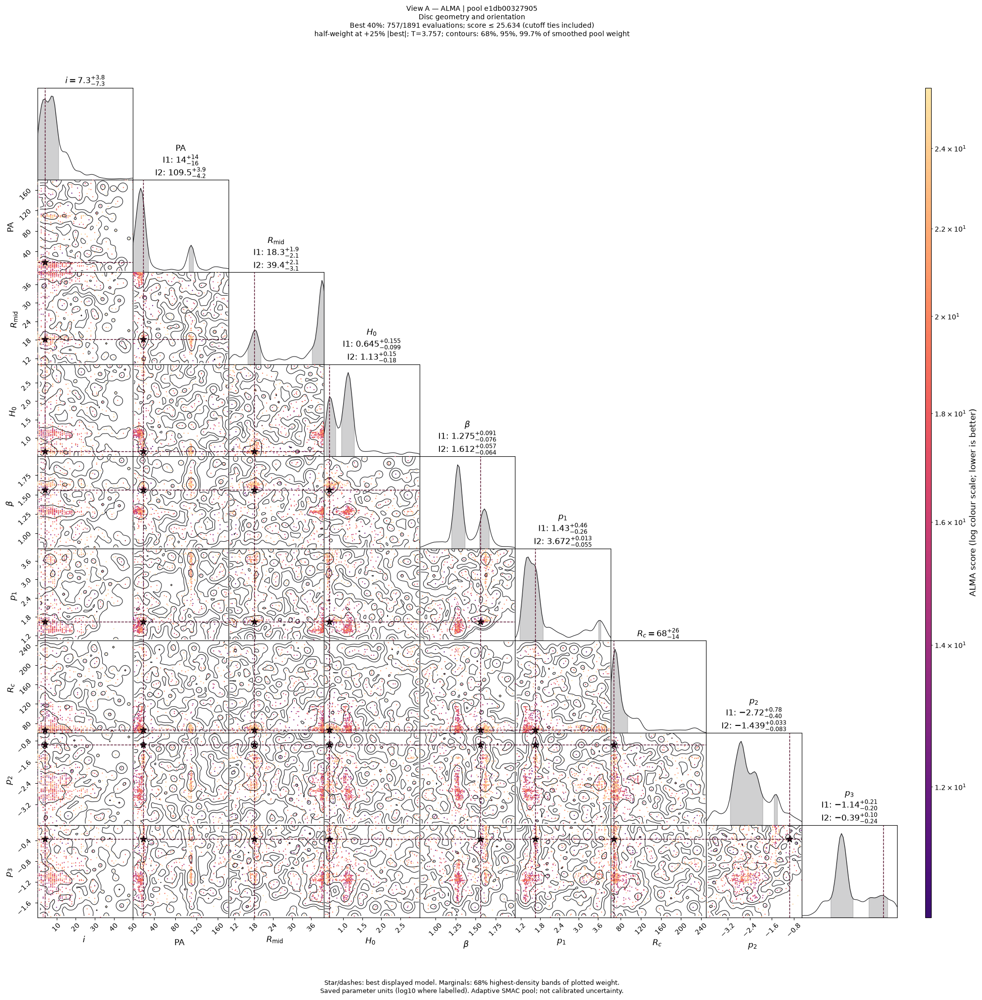

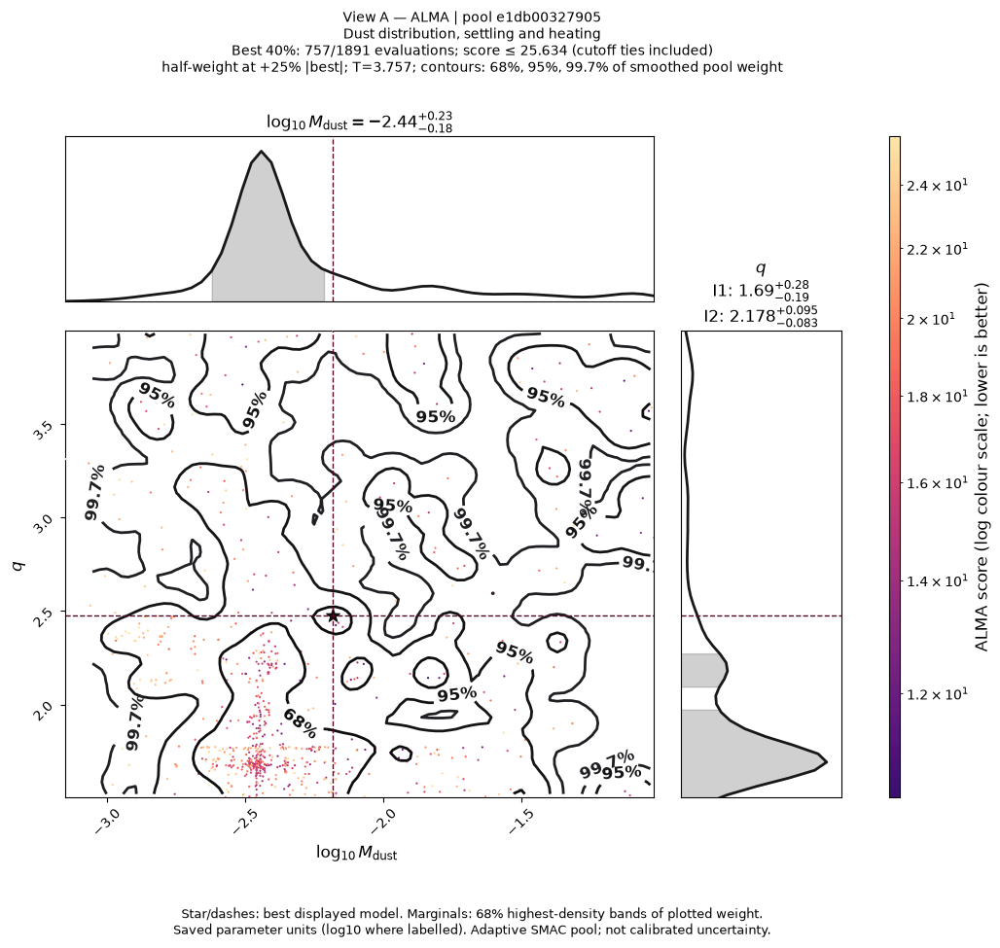

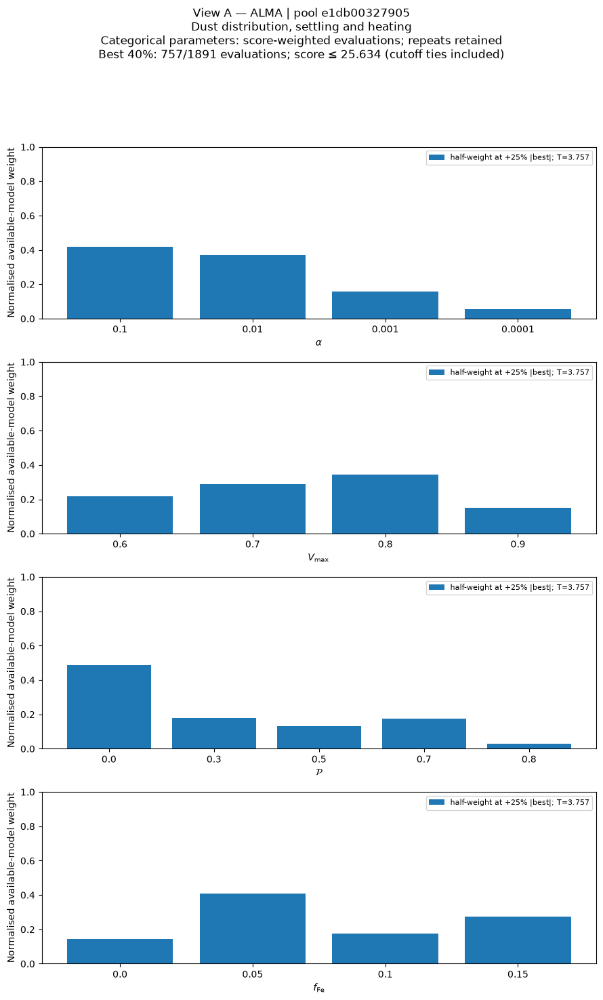

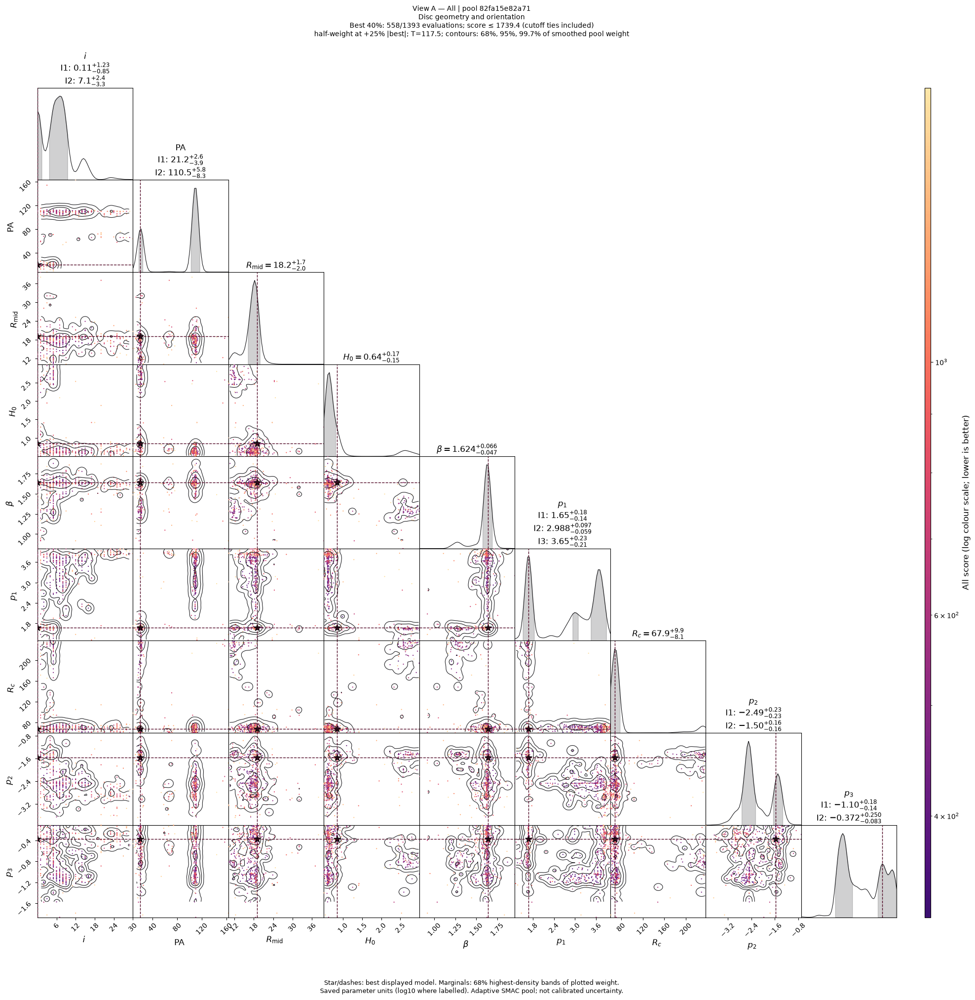

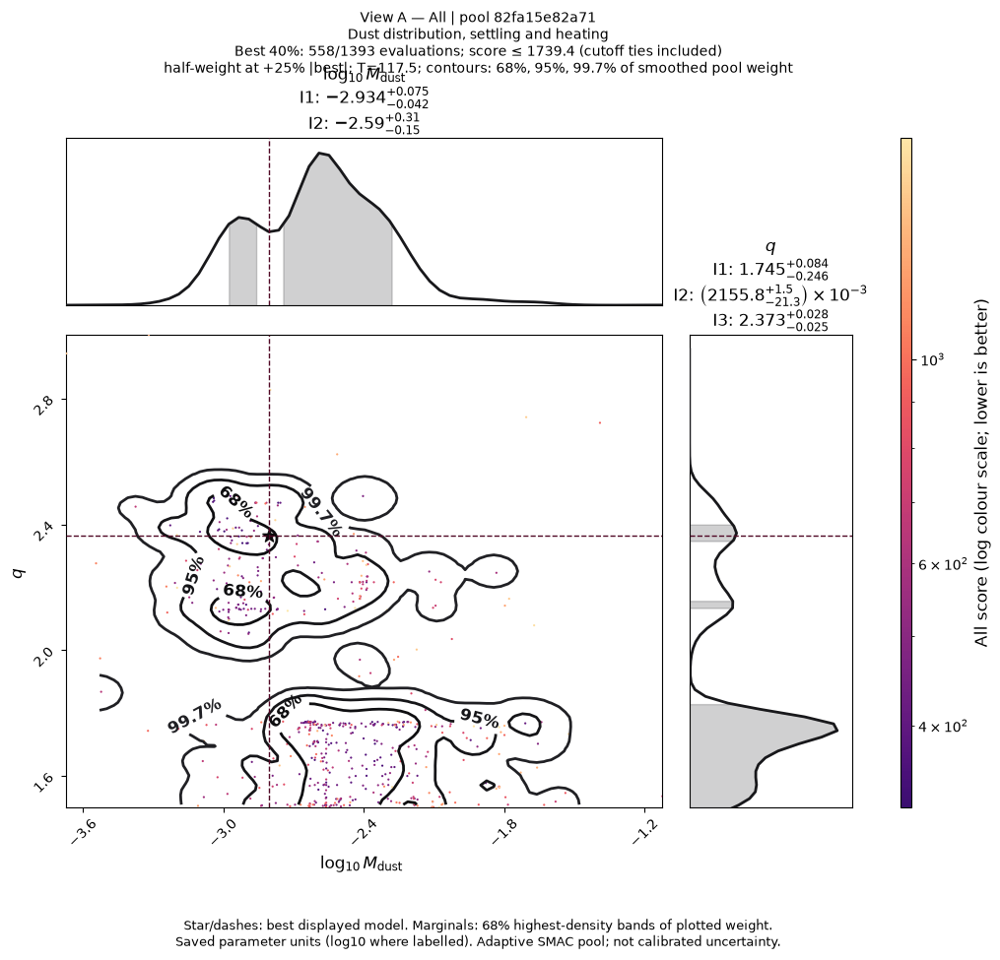

...

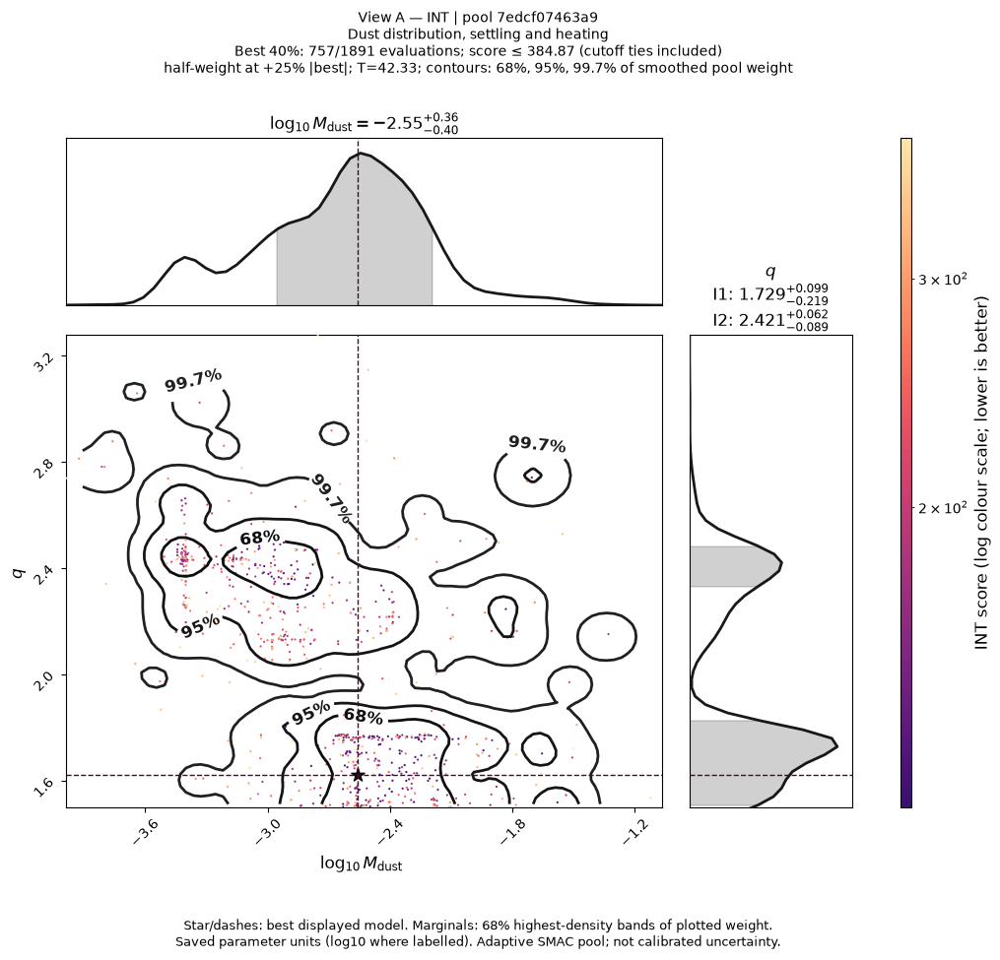

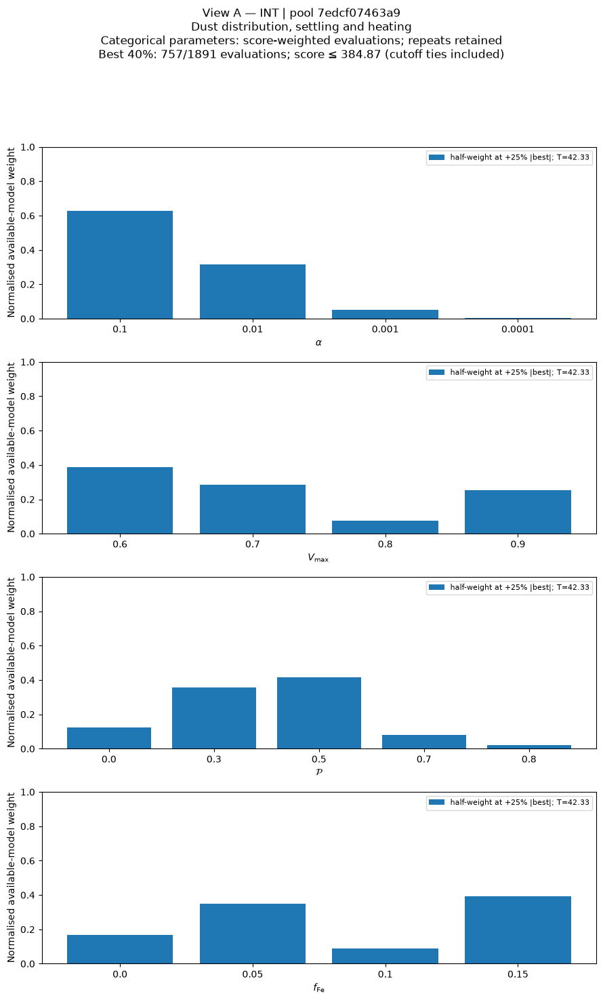

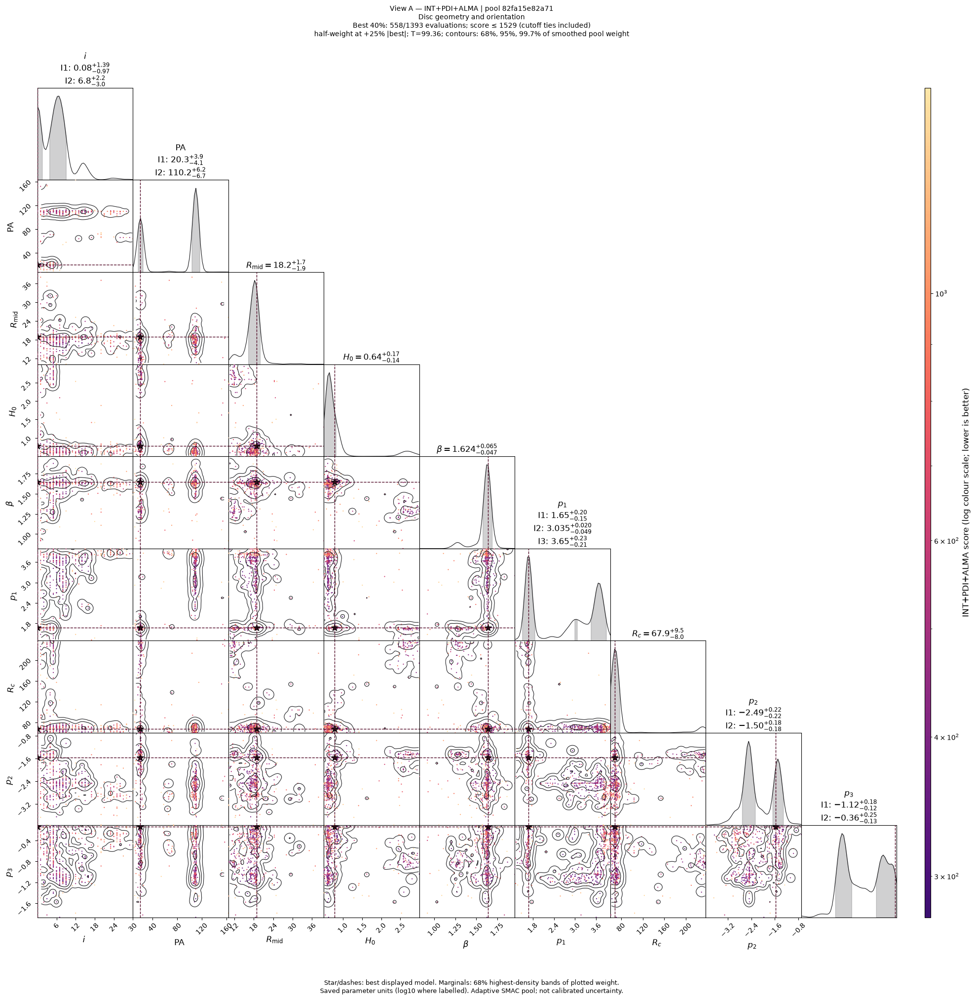

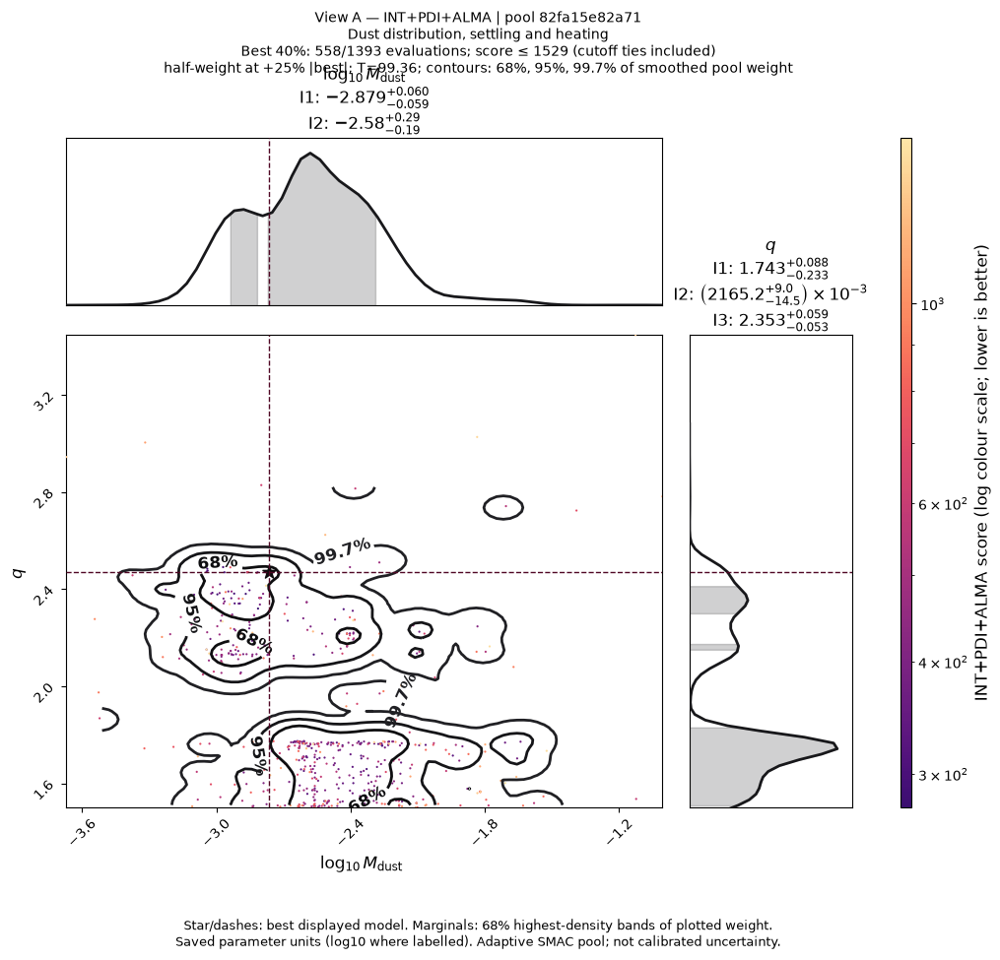

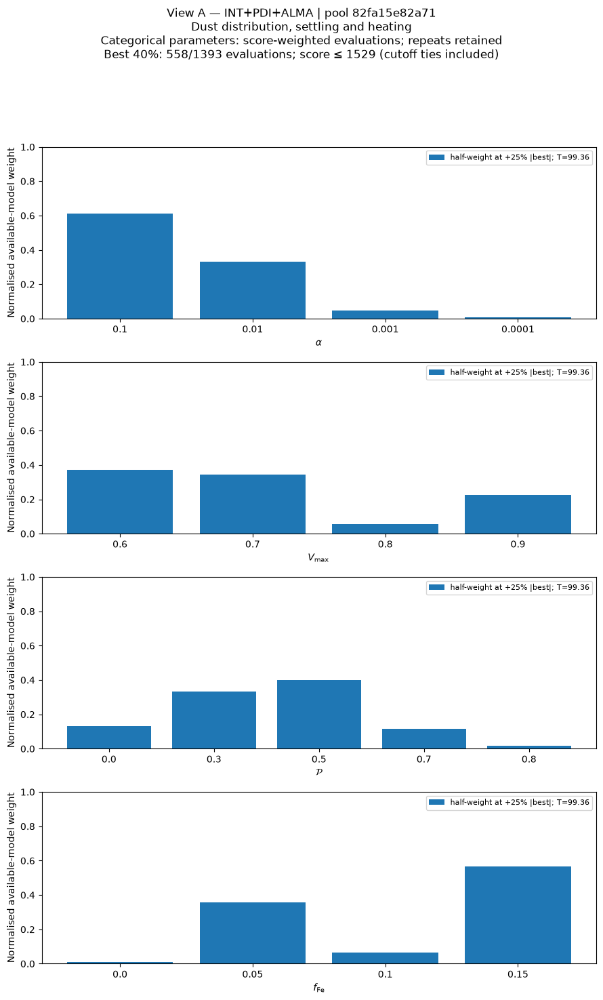

/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 200 samples available to compute an HDI for column 'inclination' in chain 'half-weight at +25% |best|; T=27.83'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:584: UserWarning: Only 200 samples available to compute an HDI for column 'inclination' in chain 'half-weight at +25% |best|; T=27.83'. Results may be unreliable; consider enabling KDE or providing more samples.
  summary = self.get_parameter_summary_hdi(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 200 samples available to compute an HDI for column 'disk_pa' in chain 'half-weight at +25% |best|; T=27.83'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chai

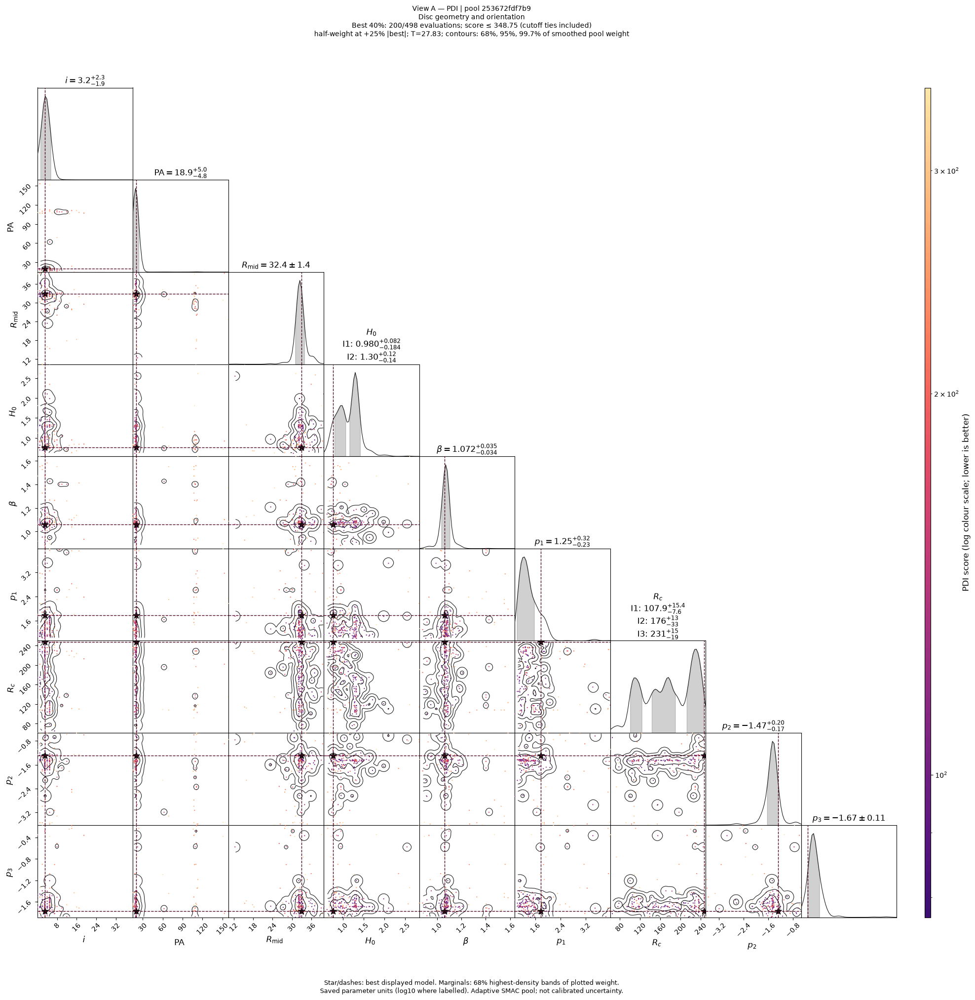

/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 200 samples available to compute an HDI for column 'disk_total_dust_mass' in chain 'half-weight at +25% |best|; T=27.83'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:584: UserWarning: Only 200 samples available to compute an HDI for column 'disk_total_dust_mass' in chain 'half-weight at +25% |best|; T=27.83'. Results may be unreliable; consider enabling KDE or providing more samples.
  summary = self.get_parameter_summary_hdi(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 200 samples available to compute an HDI for column 'zone_1_species_1_aexp' in chain 'half-weight at +25% |best|; T=27.83'. Results may be unreliable; consider enabling KDE or providing more

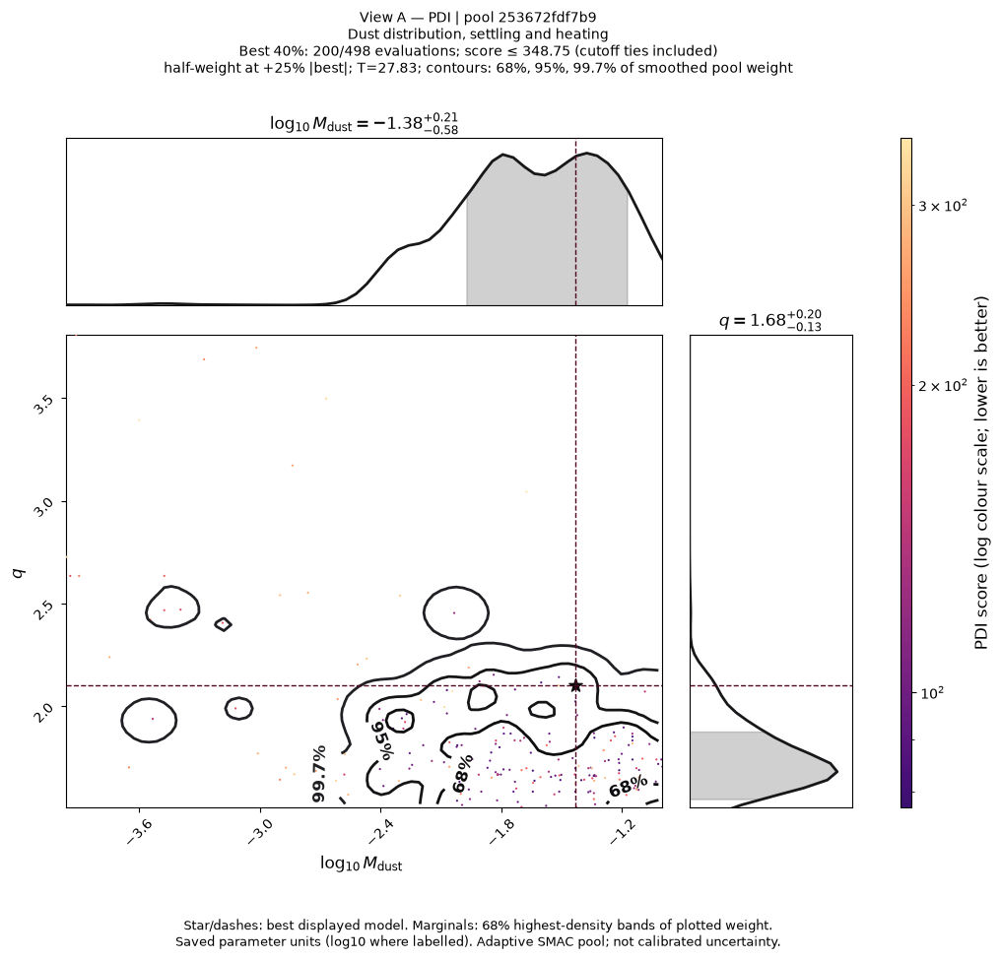

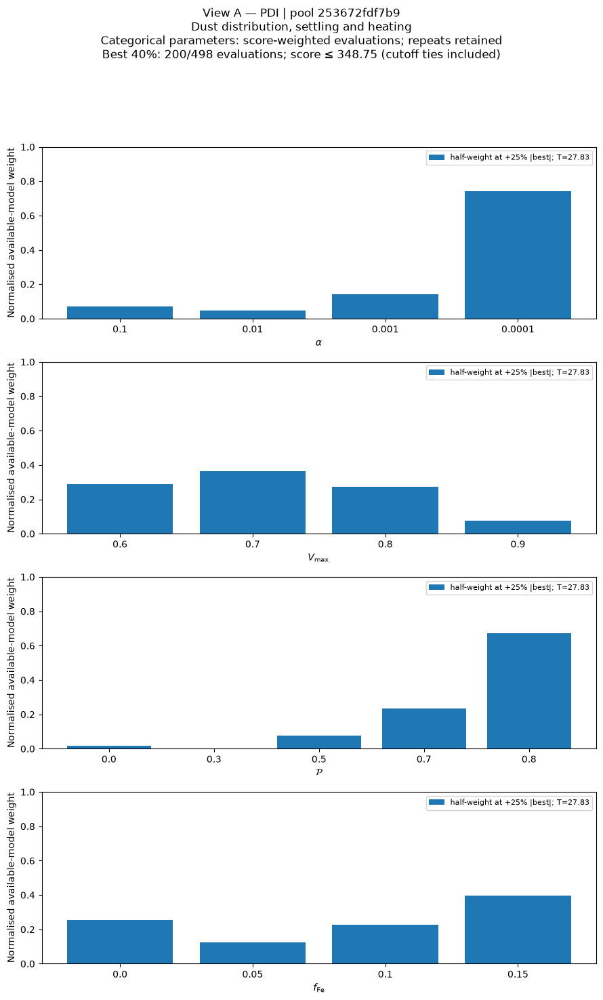

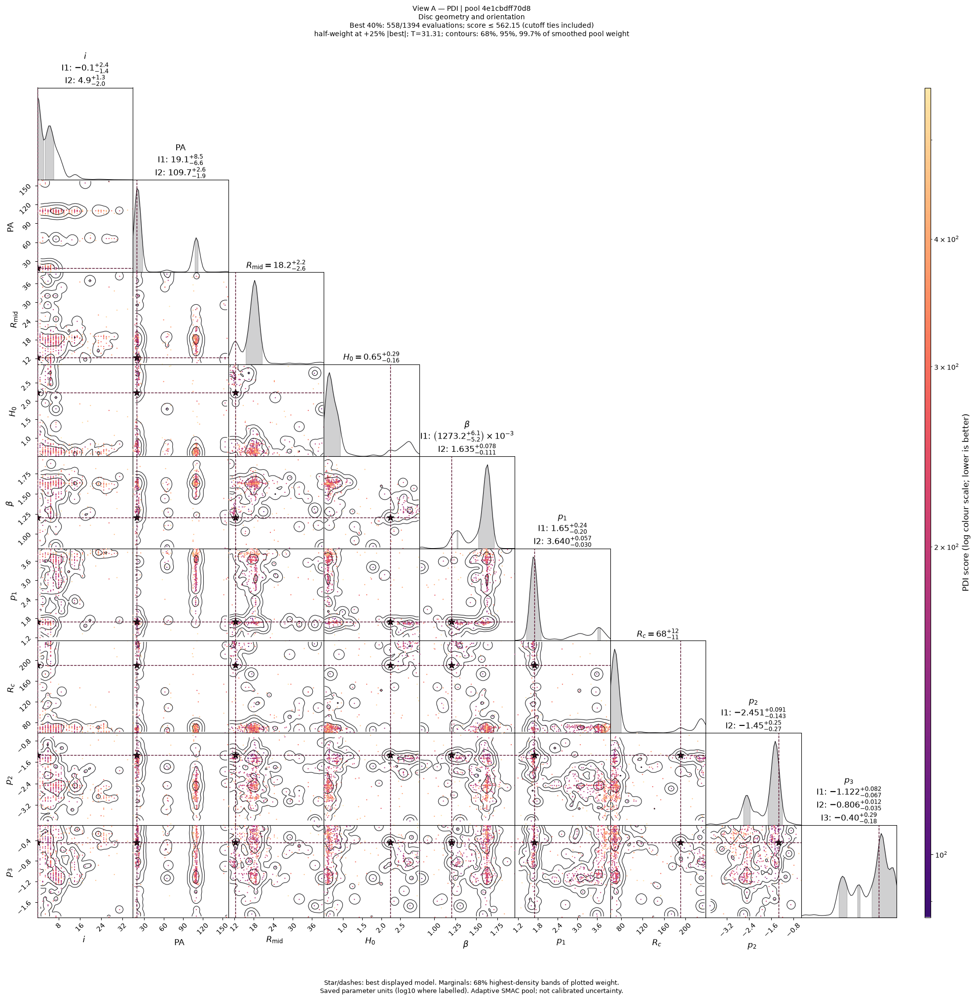

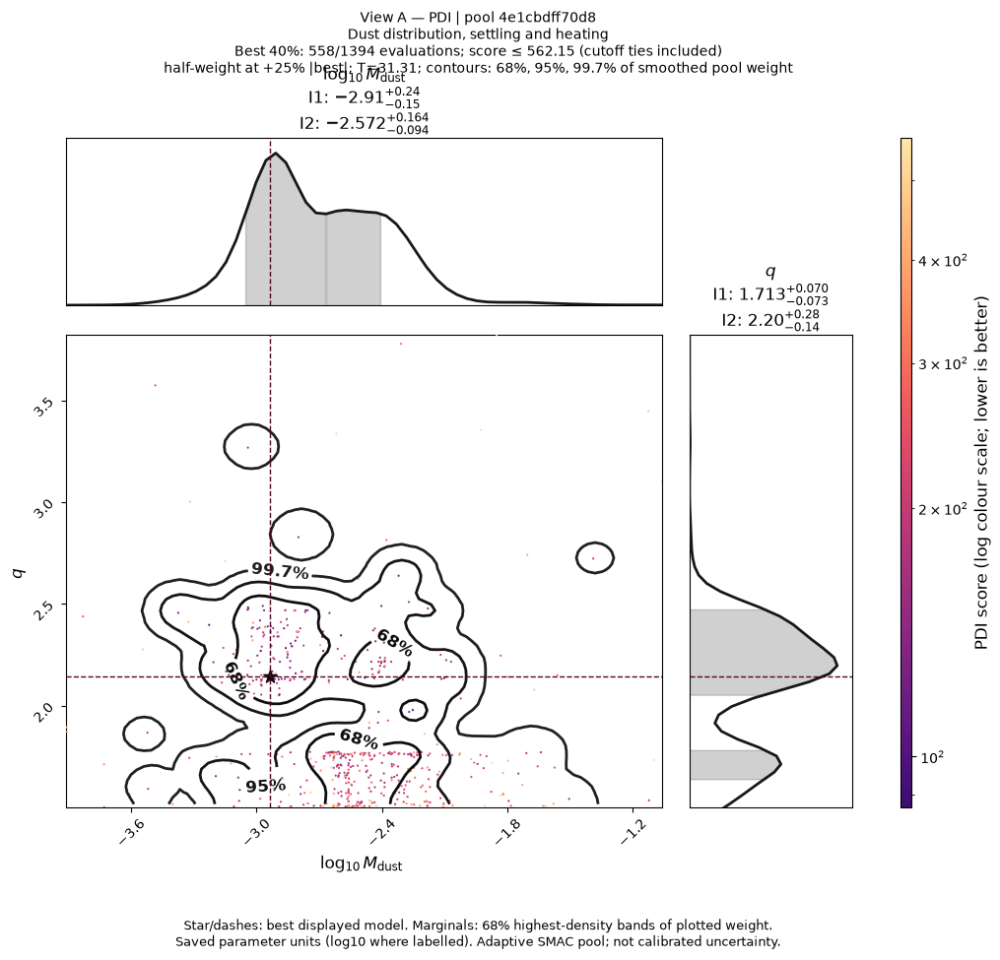

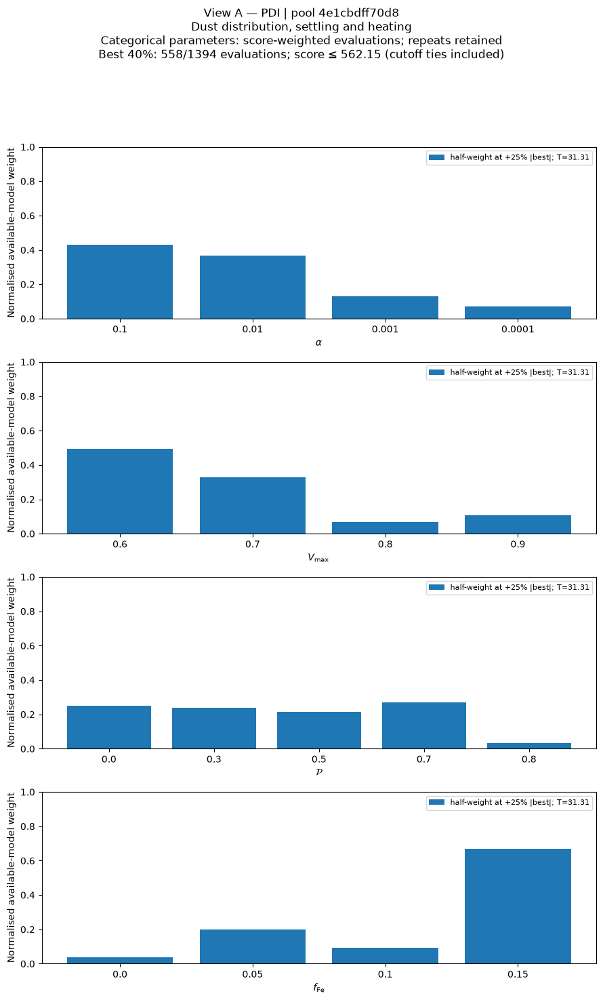

...

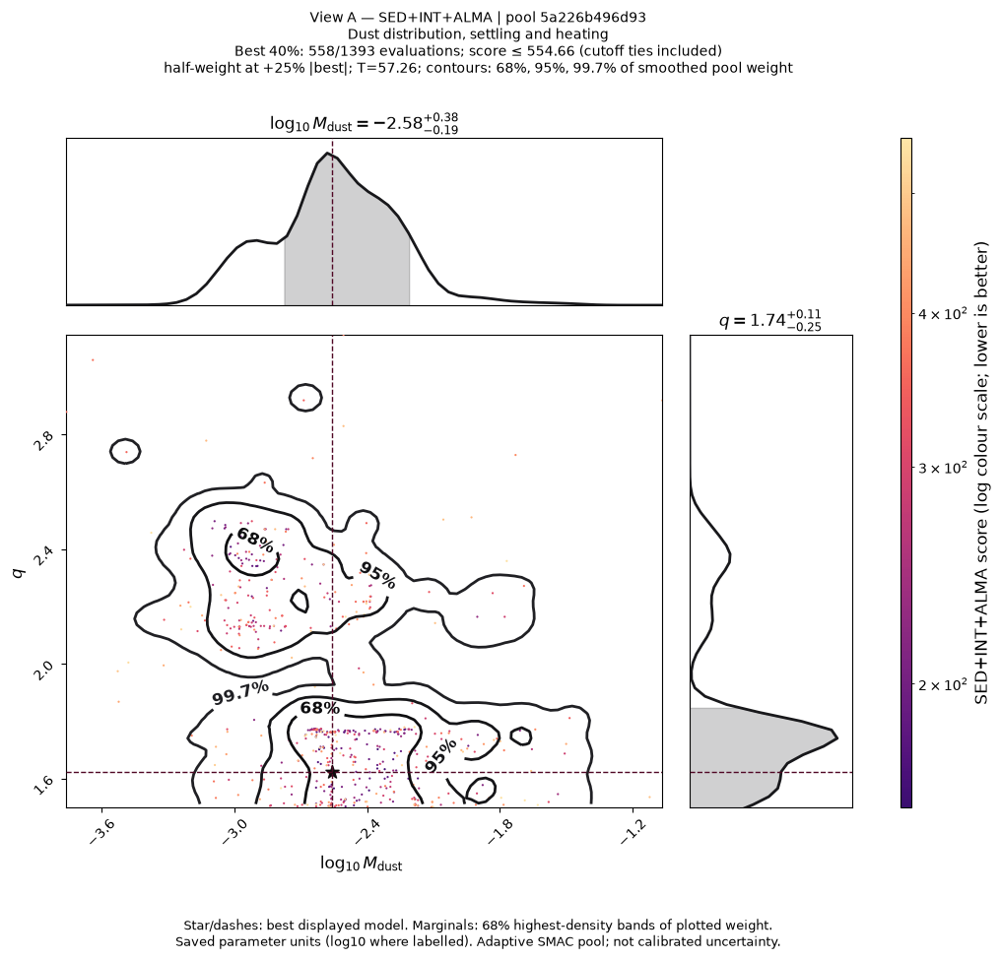

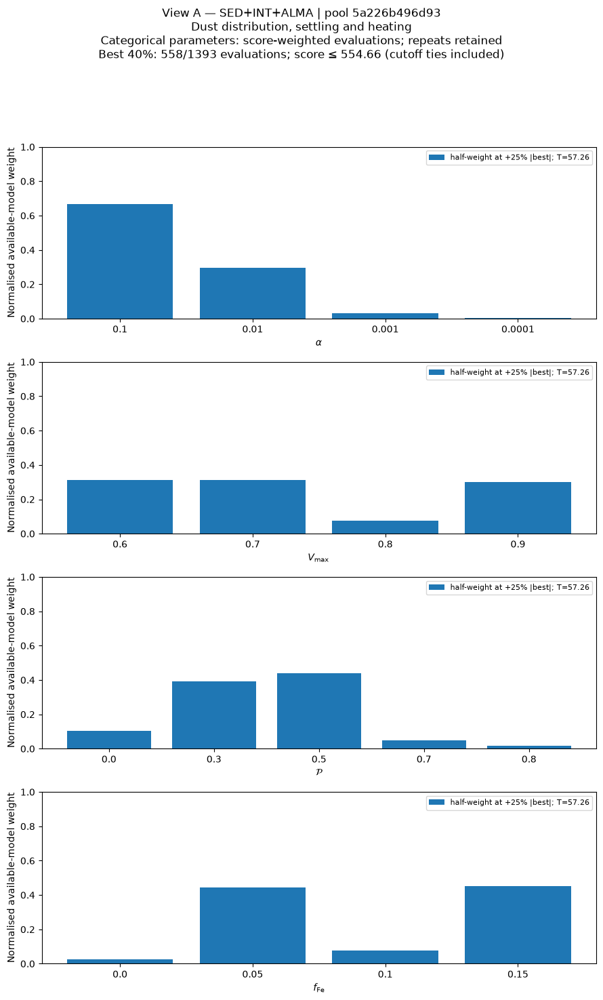

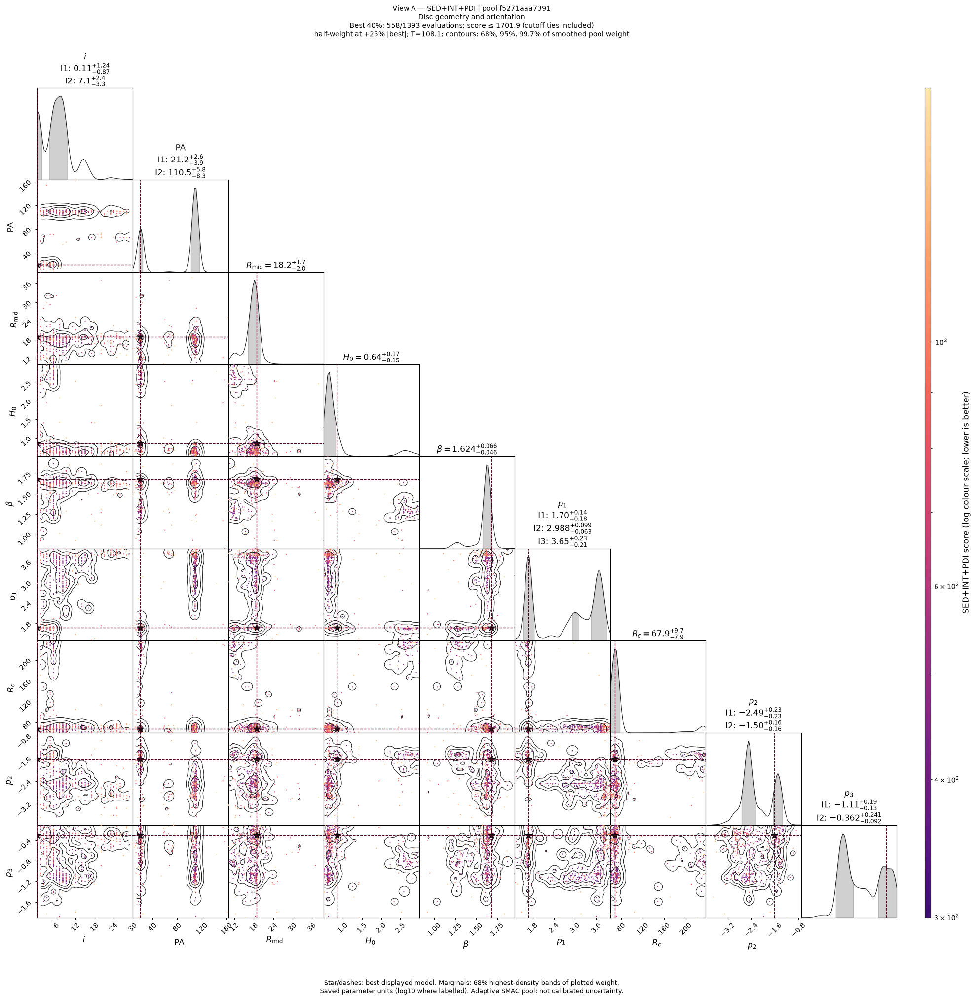

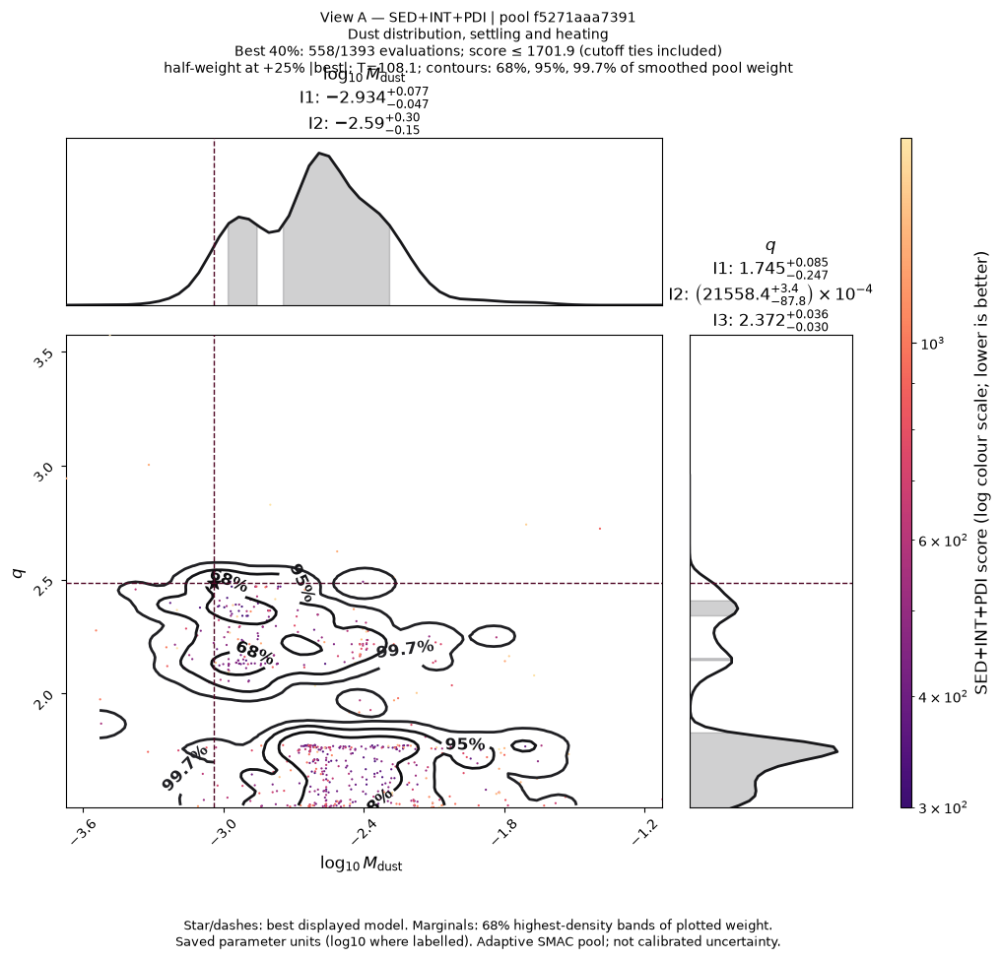

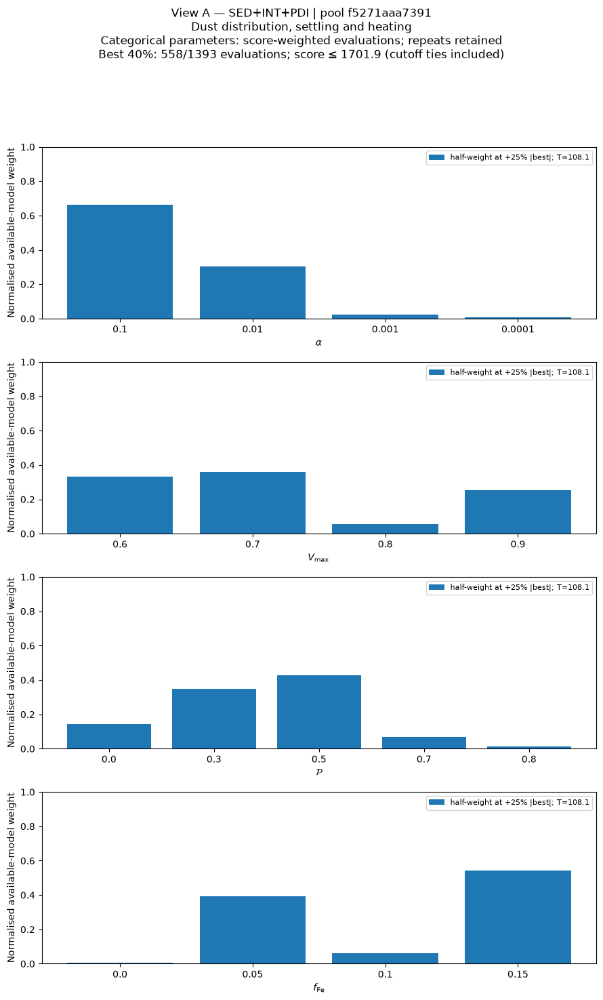

/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 200 samples available to compute an HDI for column 'inclination' in chain 'half-weight at +25% |best|; T=41.94'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:584: UserWarning: Only 200 samples available to compute an HDI for column 'inclination' in chain 'half-weight at +25% |best|; T=41.94'. Results may be unreliable; consider enabling KDE or providing more samples.
  summary = self.get_parameter_summary_hdi(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 200 samples available to compute an HDI for column 'disk_pa' in chain 'half-weight at +25% |best|; T=41.94'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chai

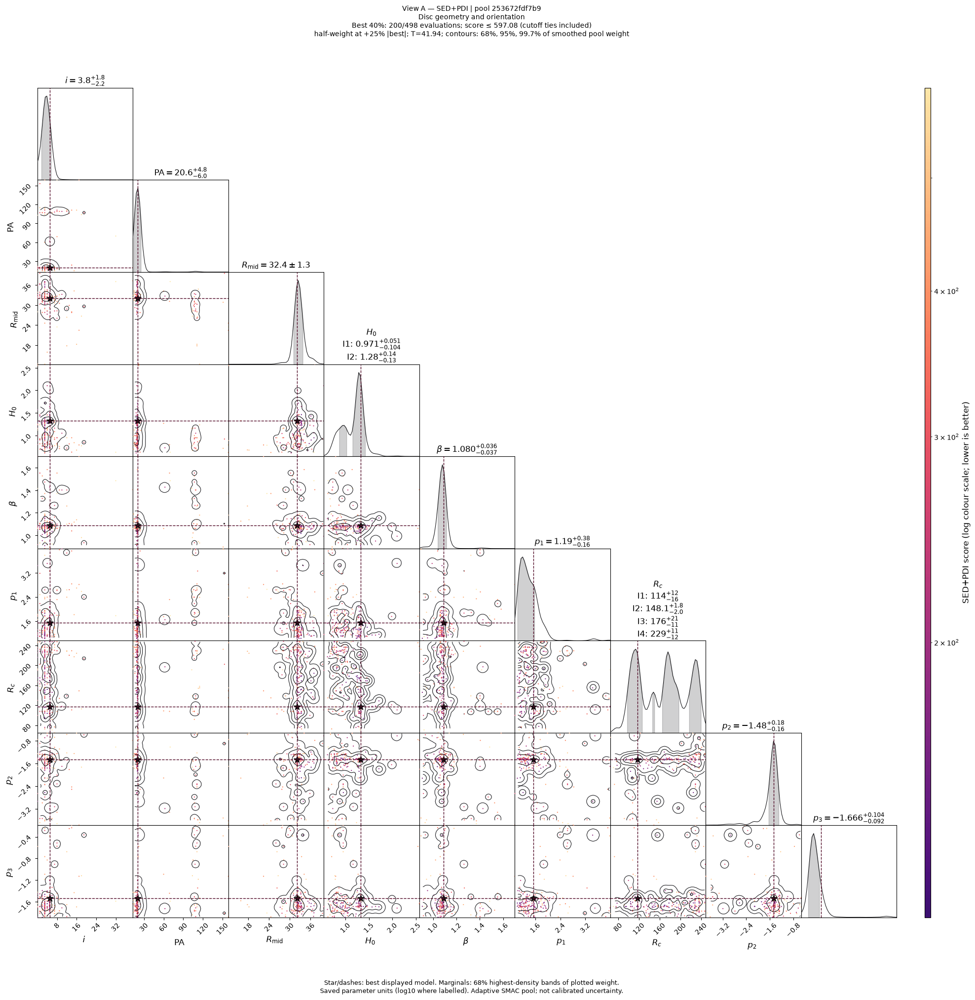

/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 200 samples available to compute an HDI for column 'disk_total_dust_mass' in chain 'half-weight at +25% |best|; T=41.94'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:584: UserWarning: Only 200 samples available to compute an HDI for column 'disk_total_dust_mass' in chain 'half-weight at +25% |best|; T=41.94'. Results may be unreliable; consider enabling KDE or providing more samples.
  summary = self.get_parameter_summary_hdi(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 200 samples available to compute an HDI for column 'zone_1_species_1_aexp' in chain 'half-weight at +25% |best|; T=41.94'. Results may be unreliable; consider enabling KDE or providing more

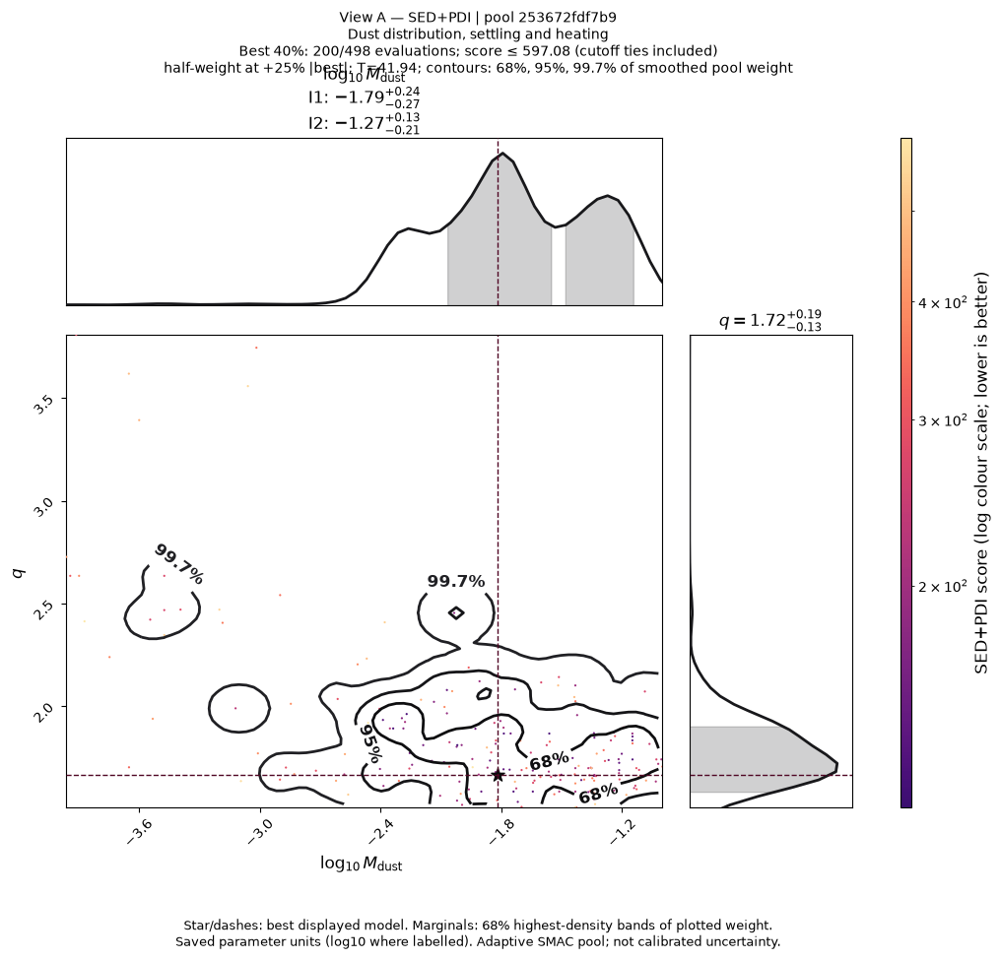

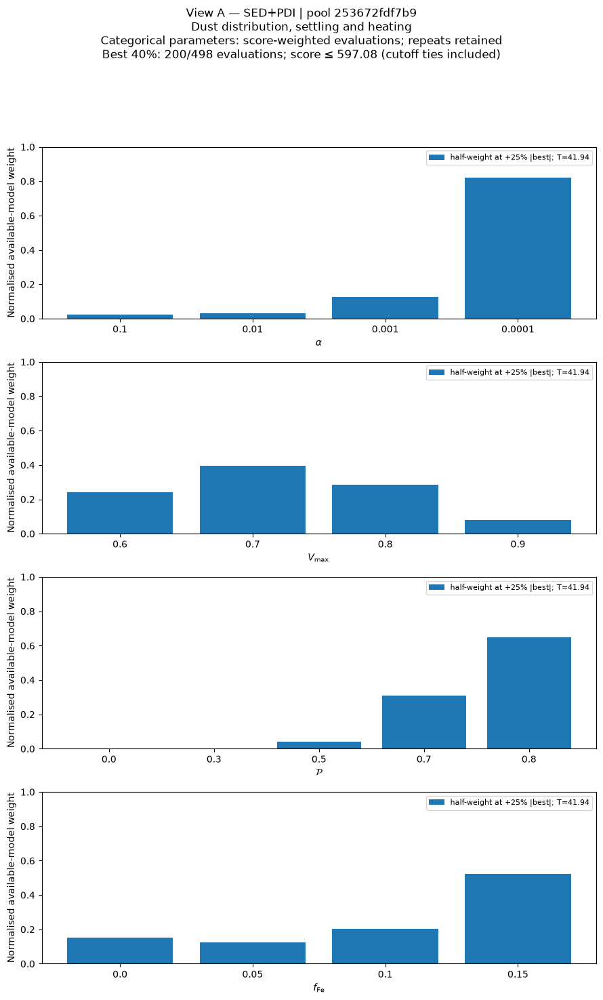

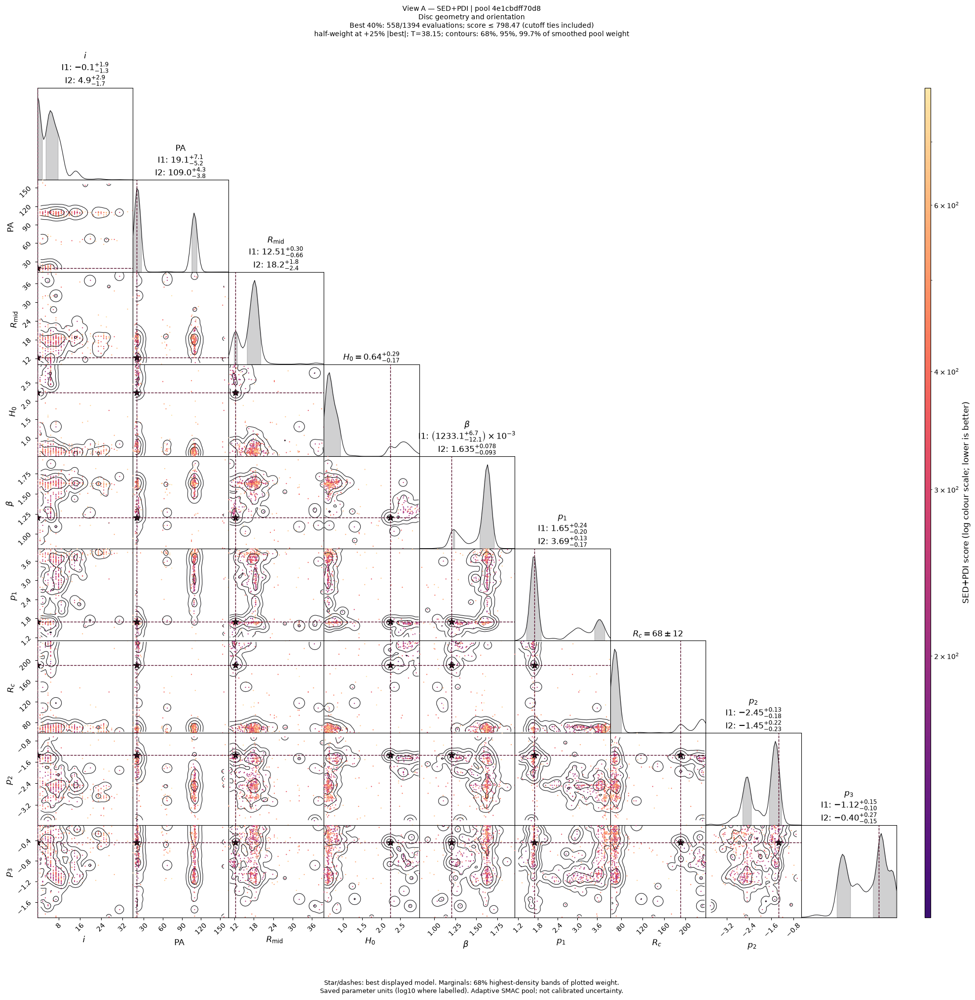

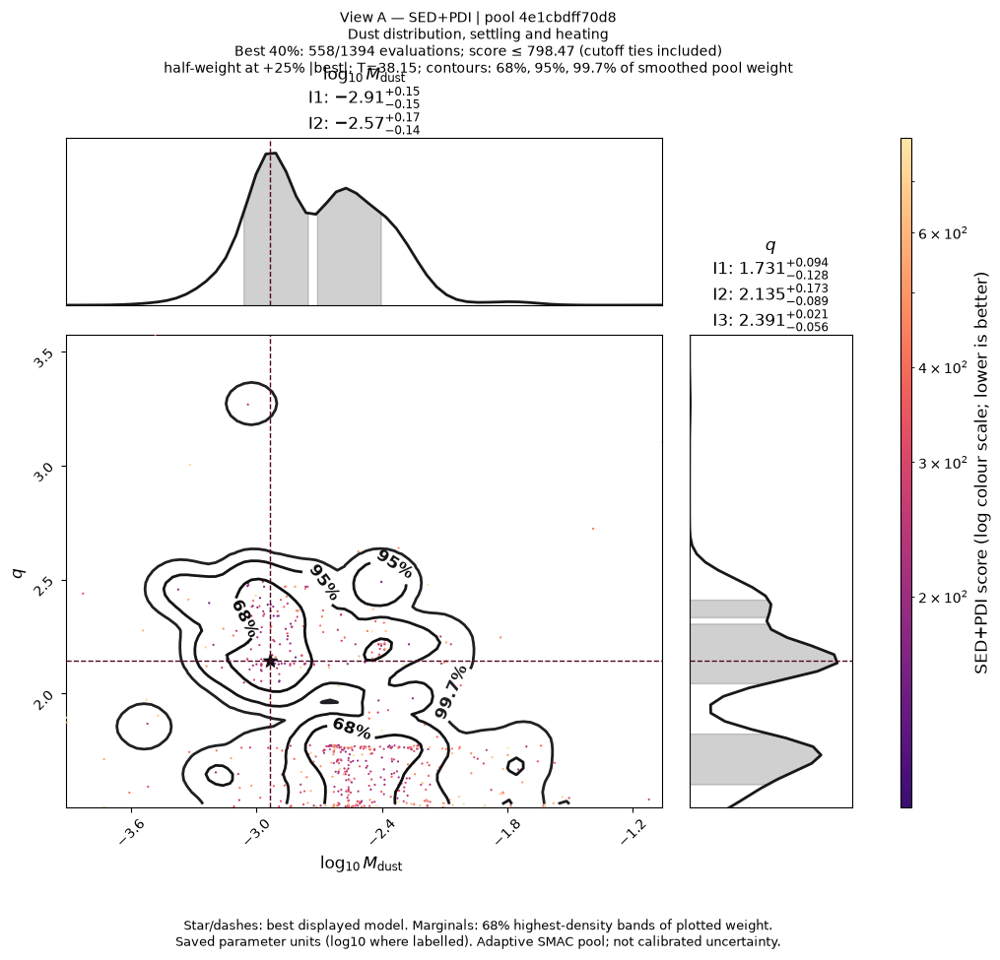

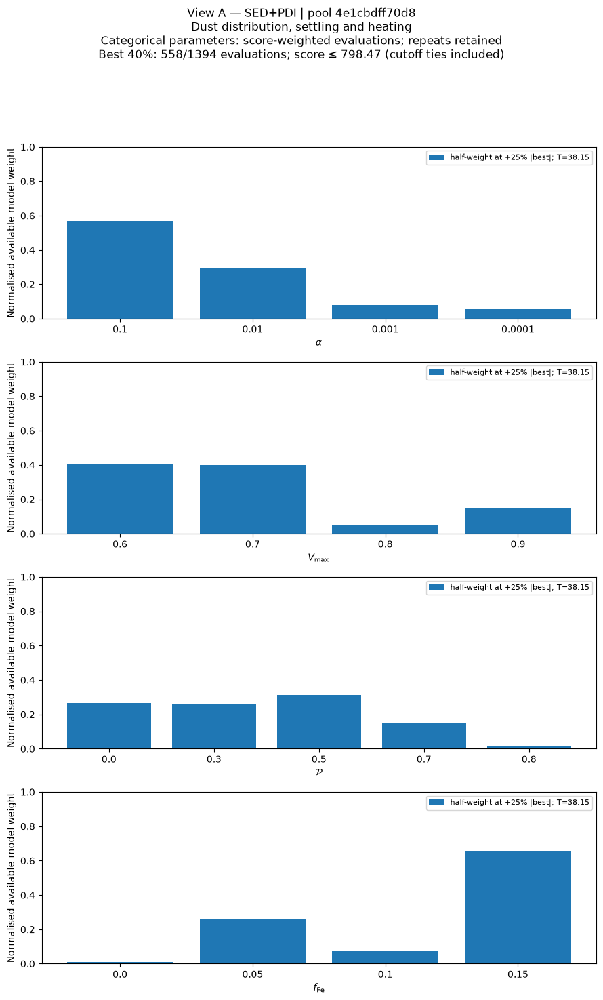

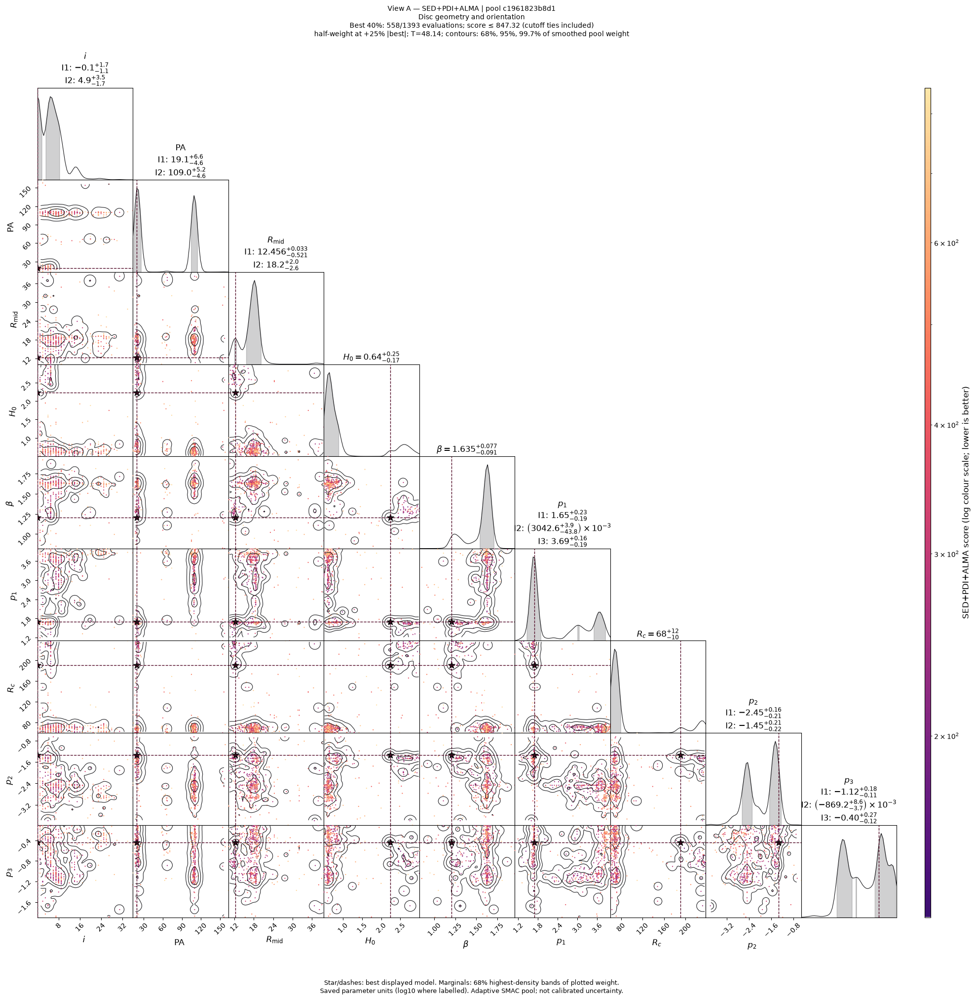

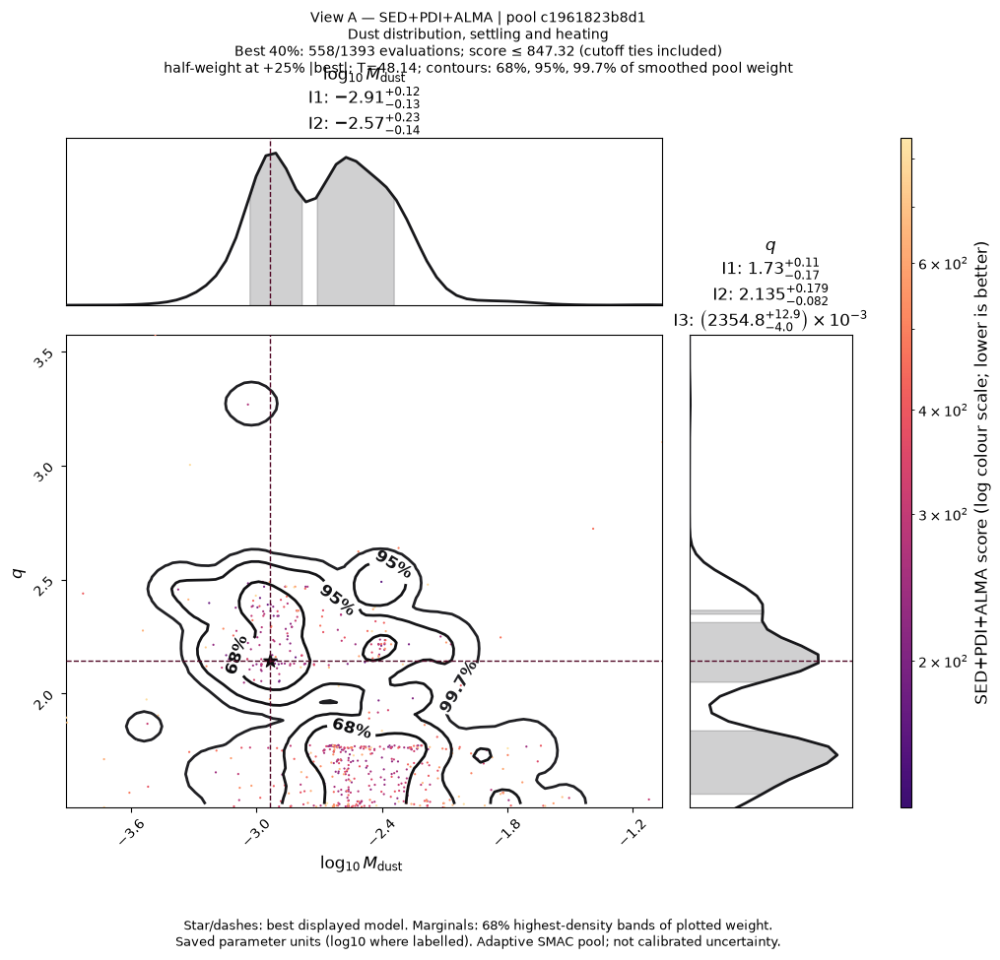

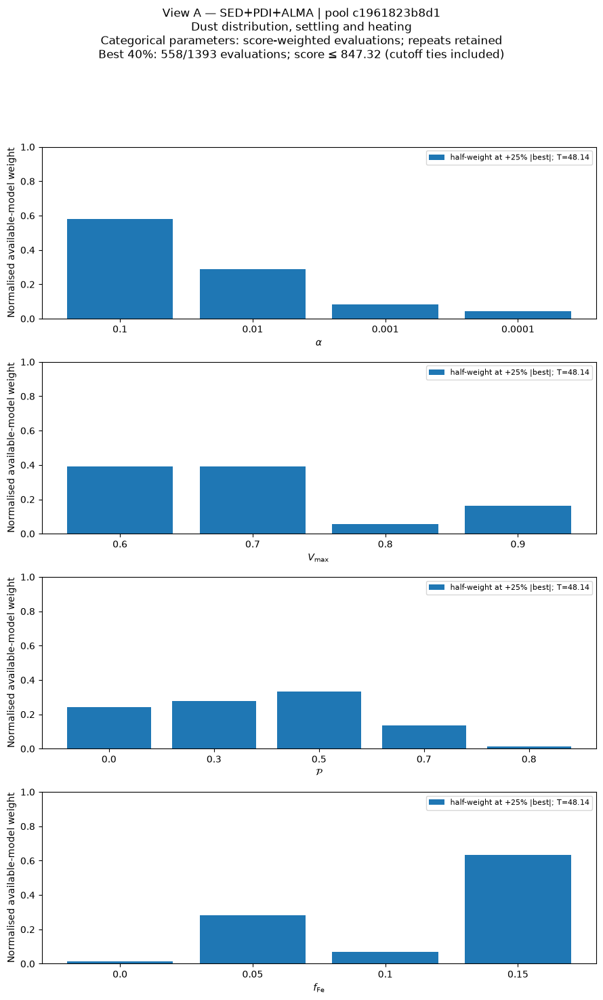

,objective,score_pool_key,requested_fraction,n_available,n_selected,realised_fraction,cutoff,cutoff_ties_included
0,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,0.4,1891,757,0.400317,25.633852,True
1,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,0.4,1393,558,0.400574,1739.442231,True
2,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,0.4,1891,757,0.400317,384.873353,True
3,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,0.4,1393,558,0.400574,1528.985026,True
4,PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,0.4,498,200,0.401606,348.750253,True
5,PDI,4e1cbdff70d81329293a5f559525f770d7cf6cc96908f6...,0.4,1394,558,0.400287,562.148986,True
6,SED,746b16227955075c991cd74bff93e1f6fb2f8c6aeac21b...,0.4,4335,1734,0.400000,70.740887,True
7,SED+ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,0.4,1891,757,0.400317,107.657049,True
8,SED+INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,0.4,1891,757,0.400317,518.974135,True
9,SED+INT+ALMA,5a226b496d938adcb809a8318936a8ecd907429b0d3eb4...,0.4,1393,558,0.400574,554.659574,True


,objective,score_pool_key,setting,label,temperature,half_weight_delta,best_score,half_weight_fraction,temperature_rule,base_measure,n_evaluations,n_configurations,n_histories,n_zero_weights,max_evaluation_weight,evaluation_weight_ess,configuration_weight_ess,selection_fraction,n_before_selection,selection_cutoff
0,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,half_weight_01,half-weight at +10% |best|,1.502641,1.041551,10.415510,0.10,fraction_of_abs_best,equal_per_evaluation_including_repeats,757,757,3,0,0.037580,110.053151,110.053151,0.4,1891,25.633852
1,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,half_weight_02,half-weight at +25% |best|,3.756601,2.603878,10.415510,0.25,fraction_of_abs_best,equal_per_evaluation_including_repeats,757,757,3,0,0.007604,417.153704,417.153704,0.4,1891,25.633852
2,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,half_weight_03,half-weight at +50% |best|,7.513203,5.207755,10.415510,0.50,fraction_of_abs_best,equal_per_evaluation_including_repeats,757,757,3,0,0.003503,619.872042,619.872042,0.4,1891,25.633852
3,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,half_weight_01,half-weight at +10% |best|,47.015072,32.588364,325.883644,0.10,fraction_of_abs_best,equal_per_evaluation_including_repeats,558,558,2,0,0.019157,120.461855,120.461855,0.4,1393,1739.442231
4,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,half_weight_02,half-weight at +25% |best|,117.537679,81.470911,325.883644,0.25,fraction_of_abs_best,equal_per_evaluation_including_repeats,558,558,2,0,0.007586,259.543176,259.543176,0.4,1393,1739.442231
5,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,half_weight_03,half-weight at +50% |best|,235.075359,162.941822,325.883644,0.50,fraction_of_abs_best,equal_per_evaluation_including_repeats,558,558,2,0,0.004529,369.806580,369.806580,0.4,1393,1739.442231
6,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,half_weight_01,half-weight at +10% |best|,16.932720,11.736867,117.368670,0.10,fraction_of_abs_best,equal_per_evaluation_including_repeats,757,757,3,0,0.011377,182.525788,182.525788,0.4,1891,384.873353
7,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,half_weight_02,half-weight at +25% |best|,42.331799,29.342167,117.368670,0.25,fraction_of_abs_best,equal_per_evaluation_including_repeats,757,757,3,0,0.005093,355.119221,355.119221,0.4,1891,384.873353
8,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,half_weight_03,half-weight at +50% |best|,84.663599,58.684335,117.368670,0.50,fraction_of_abs_best,equal_per_evaluation_including_repeats,757,757,3,0,0.003109,526.972882,526.972882,0.4,1891,384.873353
9,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,half_weight_01,half-weight at +10% |best|,39.745485,27.549471,275.494709,0.10,fraction_of_abs_best,equal_per_evaluation_including_repeats,558,558,2,0,0.025829,113.232536,113.232536,0.4,1393,1528.985026


,parameter,setting,status,n_pool,n_valid,retained_weight,omitted_weight,evaluation_weight_ess,configuration_weight_ess,reference_evaluation_id,reference_score,n_tied_best,...,upper,center_kind,summary_statistic,band_index,n_bands,summary_mass,summary_mass_scope,objective,score_pool_key,plot_style,histogram_smooth,parameter_group
0,numeric_corner,half_weight_02,plotted,757.0,757.0,1.0,0.0,417.153704,417.153704,Dubrulle/sed_interf_pdi_alma_stages [seed 2692...,10.41551,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,reference,2,Disc geometry and orientation
1,inclination,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.953826,within_interval_median,hdi,1.0,1.0,0.68,all_bands_together,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,reference,2,Disc geometry and orientation
2,disk_pa,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,28.770804,band_mode,hdi,1.0,2.0,0.68,all_bands_together,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,reference,2,Disc geometry and orientation
3,disk_pa,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,113.435971,band_mode,hdi,2.0,2.0,0.68,all_bands_together,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,reference,2,Disc geometry and orientation
4,disk_Rmid,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,20.197296,band_mode,hdi,1.0,2.0,0.68,all_bands_together,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,reference,2,Disc geometry and orientation
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
506,disk_total_dust_mass,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.783837,band_mode,hdi,1.0,2.0,0.68,all_bands_together,SED+PDI+ALMA,c1961823b8d19a47c20ff3d1a2080f7a34d05924b682eb...,reference,2,"Dust distribution, settling and heating"
507,disk_total_dust_mass,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.343509,band_mode,hdi,2.0,2.0,0.68,all_bands_together,SED+PDI+ALMA,c1961823b8d19a47c20ff3d1a2080f7a34d05924b682eb...,reference,2,"Dust distribution, settling and heating"
508,zone_1_species_1_aexp,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.838909,band_mode,hdi,1.0,3.0,0.68,all_bands_together,SED+PDI+ALMA,c1961823b8d19a47c20ff3d1a2080f7a34d05924b682eb...,reference,2,"Dust distribution, settling and heating"
509,zone_1_species_1_aexp,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.313868,band_mode,hdi,2.0,3.0,0.68,all_bands_together,SED+PDI+ALMA,c1961823b8d19a47c20ff3d1a2080f7a34d05924b682eb...,reference,2,"Dust distribution, settling and heating"


,objective,score_pool_key,parameter_group,status,reason
0,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,Disc geometry and orientation,plots_created,
1,ALMA,e1db003279056f4edc64749435dbdd19de011698b449e4...,"Dust distribution, settling and heating",plots_created,
2,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,Disc geometry and orientation,plots_created,
3,All,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,"Dust distribution, settling and heating",plots_created,
4,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,Disc geometry and orientation,plots_created,
5,INT,7edcf07463a9a448ef02f1c44540b852039cded1d9b73c...,"Dust distribution, settling and heating",plots_created,
6,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,Disc geometry and orientation,plots_created,
7,INT+PDI+ALMA,82fa15e82a71ae2c5391d493ad733ebe8c0f71cd92d075...,"Dust distribution, settling and heating",plots_created,
8,PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,Disc geometry and orientation,plots_created,
9,PDI,253672fdf7b91ca17227caf56415b89247afef9cc23773...,"Dust distribution, settling and heating",plots_created,


In [20]:
import importlib
import score_weighted_pool as score_weighted_module
# Reload the edited plotting helper when this cell is rerun in an existing kernel.
importlib.reload(score_weighted_module)
from score_weighted_pool import score_weighted_pool, plot_score_weighted_pool, group_parameter_references
from importlib.util import find_spec
from importlib.metadata import version

weighted_parts, temperature_parts, weighted_coverage_parts, weighted_status = [], [], [], []
weighted_selection_parts, weighted_membership_parts = [], []
chainconsumer_available = find_spec('chainconsumer') is not None
score_weighted_package_version = version('chainconsumer') if chainconsumer_available else None
weighted_parameters = SCORE_WEIGHTED_PARAMETERS if SCORE_WEIGHTED_PARAMETERS is not None else list(cost_references)
unknown_weighted_parameters = set(weighted_parameters)-set(cost_references)
if unknown_weighted_parameters:
    raise ValueError(f'Unknown/non-independent weighted parameters: {sorted(unknown_weighted_parameters)}')
weighted_references = {name: cost_references[name] for name in weighted_parameters}
weighted_parameter_groups = group_parameter_references(weighted_references, SCORE_WEIGHTED_PARAMETER_GROUPS)
pool_views['score_weighted_parameter_groups'] = pd.DataFrame([
    dict(parameter_group=label, parameter=name, coordinates=ref['kind'])
    for label, refs in weighted_parameter_groups.items() for name, ref in refs.items()])
display(pool_views['score_weighted_parameter_groups'])
# A rerun replaces the previous weighted figures, including the former full corner.
for name in list(figures):
    if name.startswith('available_per_objective_score_weighted_'):
        del figures[name]
if SCORE_WEIGHTED_ENABLED and not chainconsumer_available:
    print('Weight tables will be computed; plots require %pip install chainconsumer==1.3.0 in this kernel.')
if SCORE_WEIGHTED_ENABLED and not view_a_members.empty:
    if SCORE_WEIGHTED_OBJECTIVES is not None:
        unknown_objectives = set(SCORE_WEIGHTED_OBJECTIVES)-set(objective_design())
        if unknown_objectives:
            raise ValueError(f'Unknown weighted objectives: {sorted(unknown_objectives)}')
    for group_index, ((objective, key), candidates) in enumerate(
            view_a_members.groupby(['comparison', 'score_pool_key'], sort=True), 1):
        if SCORE_WEIGHTED_OBJECTIVES is not None and objective not in SCORE_WEIGHTED_OBJECTIVES:
            continue
        candidates = candidates.reset_index(drop=True)
        original_scores = score_matrix(candidates, {objective: objective_design()[objective]})[objective]
        retain, selection_cutoff = competitive_mask(original_scores, 'fraction', SCORE_WEIGHTED_RETAIN_FRACTION)
        n_before_selection = len(candidates)
        weighted_selection_parts.append(pd.DataFrame([dict(objective=objective, score_pool_key=key,
            requested_fraction=SCORE_WEIGHTED_RETAIN_FRACTION, n_available=n_before_selection,
            n_selected=int(retain.sum()), realised_fraction=float(retain.mean()),
            cutoff=selection_cutoff, cutoff_ties_included=True)]))
        weighted_membership_parts.append(candidates[['evaluation_id','parameter_hash','history','score_pool_key']]
            .assign(objective=objective, objective_score=original_scores, retained=retain))
        candidates = candidates.loc[retain].copy().reset_index(drop=True)
        absolute_deltas = SCORE_WEIGHTED_ABSOLUTE_DELTAS.get(
            (objective, key), SCORE_WEIGHTED_ABSOLUTE_DELTAS.get(objective))
        try:
            weighted, temperatures = score_weighted_pool(candidates, objective,
                objective_design()[objective], SCORE_WEIGHTED_HALF_WEIGHT_FRACTIONS, absolute_deltas)
        except ValueError as error:
            weighted_status.append(dict(objective=objective, score_pool_key=key,
                                        status='weighting_skipped', reason=str(error)))
            continue
        temperatures = temperatures.assign(selection_fraction=SCORE_WEIGHTED_RETAIN_FRACTION,
            n_before_selection=n_before_selection, selection_cutoff=selection_cutoff)
        weighted_parts.append(weighted)
        temperature_parts.append(temperatures)
        if chainconsumer_available:
            for parameter_group_index, (label, refs) in enumerate(weighted_parameter_groups.items(), 1):
                # Weights/selection are computed once above, shared by all physical groups.
                plots, plotted_coverage = plot_score_weighted_pool(candidates, weighted, temperatures,
                    refs, SCORE_WEIGHTED_CONTOUR_MASSES, SCORE_WEIGHTED_BINS,
                    SCORE_WEIGHTED_SMOOTH, SCORE_WEIGHTED_MIN_ESS,
                    style=SCORE_WEIGHTED_STYLE, reference_setting=SCORE_WEIGHTED_REFERENCE_SETTING,
                    color_scale=SCORE_WEIGHTED_COLOR_SCALE, parameter_group=label,
                    complete_references=weighted_references)
                weighted_coverage_parts.append(plotted_coverage)
                for kind, fig in plots.items():
                    show(f'available_per_objective_score_weighted_{group_index:02d}_group_{parameter_group_index:02d}_{kind}', fig)
                weighted_status.append(dict(objective=objective, score_pool_key=key, parameter_group=label,
                    status='plots_created' if plots else 'no_supported_plots', reason=''))
            continue
        else:
            status = 'weights_only_missing_chainconsumer'
        weighted_status.append(dict(objective=objective, score_pool_key=key, status=status, reason=''))
for name, parts in [('score_weights', weighted_parts), ('score_temperatures', temperature_parts),
                    ('score_weighted_coverage', weighted_coverage_parts),
                    ('score_weighted_selection', weighted_selection_parts),
                    ('score_weighted_membership', weighted_membership_parts)]:
    pool_views[name] = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
pool_views['score_weighted_status'] = pd.DataFrame(weighted_status)
display(pool_views['score_weighted_selection'])
display(pool_views['score_temperatures'])
# Show numeric plot support explicitly; full categorical coverage remains in pool_views.
weighted_coverage = pool_views['score_weighted_coverage']
if not weighted_coverage.empty:
    display(weighted_coverage.loc[weighted_coverage.parameter.eq('numeric_corner')
        | weighted_coverage.status.isin(['constant_or_unavailable', 'descriptive_marginal_summary'])].dropna(axis=1, how='all'))
display(pool_views['score_weighted_status'])


## Fully scored supplement — native winners and a fixed all-observable reference

The following diagnostics retain the original fully scored analysis as a supplement. They use the largest full-score compatibility subgroup **within the physical pool selected above**, and may contain fewer candidates than views A/B. They do not replace the primary available-objective and shared-comparison results.


**Native winner:** best recorded final-budget cost within a history, objective and compatibility group. All exact ties are retained. This answers what a run found under its actual objective. Its parameter row and score vector are exported. Missing observations remain NaN; the notebook never invents cross-evaluation scores.

**Common-pool winner:** best candidate after rescoring one fixed, compatible, fully scored pool. This isolates objective changes from candidate availability, but its pool was generated adaptively. A poor common-pool optimum for SED does not prove a dedicated SED run could not do better.

The same ConfigSpace is necessary but insufficient: templates, dust assumptions, distance, corrections, instrumental mode, observations, numerical fidelity and scoring version must agree. The loader separates known compatibility metadata and records historical-file hashes. Current templates and incomplete historical metadata cannot prove identical historical physics or data. Readable IDs are snapshot-local; save the ID/provenance mapping.

Final-budget means **configured** final budget, not the highest stage that happened to finish. Failed, penalty and cost-mismatch records are excluded from comparisons but counted in coverage. Product stages are not automatically accuracy levels: current fidelity documentation says budget does not itself change photon counts. Band and chromatic interferometry are separate products.

**Physical glossary for the tested two-zone runs:** the launch uses `--2ZONE_CONT_LHC` and `--share-zone-composition`. `disk_Rmid` is the joining radius in au, not an inner-radius multiplier; zone masses are derived from total dust mass and continuous surface density. `disk_total_dust_mass` is the combined dust mass in solar masses, not total gas+dust mass. `zone_1_scale_height` is the height at the saved reference radius (7.2 au here); flaring controls its radial variation. `zone_1_surface_density_exp` and `zone_2_surface_density_exp` are signed radial surface-density exponents. The tapered zone uses `Rc` in au and exponent `q=2+zone_2_-gamma_exp`: preserve that signed saved parameter, not its negation. Inclination and `disk_pa` are degrees. `aexp` describes the grain-size distribution; porosity, iron volume fraction and `Vmax` control dust optical properties, and `alpha_viscosity` enters settling. Dust composition is shared across zones for these runs, and saved parameter ties are excluded from independent dimensions. Fixed grain-size limits, distance and reference radius are assumptions, not constrained parameters. The saved ConfigSpace table supplies exact bounds/choices; consult the run template for its MCFOST conventions.


In [21]:
full_pool_available = np.isfinite(base_candidates[SUBSETS['All']]).all(axis=1).any()
if full_pool_available:
    final = evaluations.loc[evaluations.usable & evaluations.cost_terms_match
        & np.isclose(evaluations.budget, evaluations.configured_max_budget)].copy()
    # Preserve ties and unique evaluation IDs; never infer equivalence from a local config_id.
    native_keys = ['history','objective_key','comparison_key']
    native_best = final.loc[final.cost.eq(final.groupby(native_keys).cost.transform('min'))].copy()
    display(native_best[['model_id','history','objective_key','cost',*SUBSETS['All']]])

    complete = base_candidates.loc[np.isfinite(base_candidates[SUBSETS['All']]).all(axis=1)].copy()
    # Map full keys to readable names; do not group by truncated hashes.
    keys = sorted(complete.comparison_key.unique())
    pool_names = {key:f'Common pool {i:02d}' for i,key in enumerate(keys,1)}
    complete['common_pool'] = complete.comparison_key.map(pool_names)
    pool_inventory = complete.groupby('common_pool').agg(n=('evaluation_id','size'),
        unique_parameters=('parameter_hash','nunique'), histories=('history','nunique'),
        products=('products','first'), compatibility=('comparison_key','first'))
    display(pool_inventory)
    selected_pool_id = pool_inventory.n.idxmax()  # Largest fully scored subgroup within the selected physical pool.
    if selected_pool_id not in pool_inventory.index:
        raise ValueError('POOL_ID must match an inventory label.')
    pool = complete.loc[complete.common_pool.eq(selected_pool_id)].copy().reset_index(drop=True)
    assert pool.evaluation_id.is_unique
    repeat_counts = pool.groupby('parameter_hash').agg(n=('evaluation_id','size'),
        histories=('history','nunique')).query('n > 1')
    print('Selected:',selected_pool_id, 'evaluations:',len(pool), 'histories:',pool.history.nunique())
    print('Repeated exact parameter fingerprints:',len(repeat_counts), '(all evaluations retained)')

    definitions = {item['name']:item for item in configspaces[pool.history.iloc[0]]['hyperparameters']}
    if PARAMETERS is None:
        PARAMETERS = [c[7:] for c in pool if c.startswith('param__')
            and definitions.get(c[7:],{}).get('type') != 'constant'
            and pool[c].nunique(dropna=True)>1
            and not pool[c].dropna().map(lambda x:isinstance(x,str) and 'param__'+x in pool).any()]
    references = {name:parameter_reference(pool,name,definitions[name],period=None,bins=HISTOGRAM_BINS)
                  for name in PARAMETERS}
    parameter_dictionary = pd.DataFrame([dict(parameter=name, **{k:v for k,v in definitions[name].items() if k!='name'},
                                            analysis_coordinates=references[name]['kind']) for name in PARAMETERS])
    display(parameter_dictionary)
    display(native_best.reindex(columns=['model_id','history','objective_key','cost',
        *['param__'+name for name in PARAMETERS]]))
    # Every model retains all independent and fixed/derived saved values in the pool table.
    objectives = objective_design()
    additions = addition_design(objectives)
    scores = score_matrix(pool,objectives)
    group_scores = pd.DataFrame({name:pool[columns].sum(axis=1) for name,columns in GROUPS.items()})
    # Native costs were audited against native objectives; subset rescoring need not equal them.
    display(pd.DataFrame({'objective':objectives.keys(), 'groups':list(objectives.values())}))

else:
    print('No fully scored supplement: views A/B above remain available; later supplemental diagnostics are skipped.')


,model_id,history,objective_key,cost,score_sed,score_pionier,score_gravity,score_matisse_l,score_matisse_n,score_pdi_V,score_pdi_I,score_pdi_H,score_alma
1004,Model 0009,Dubrulle/sed [seed 609655],SED,14.196439,14.196439,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2938,Model 2934,Dubrulle/sed_alma [seed 609070],SED+ALMA,38.208401,21.444554,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.763848
3974,Model 3973,Dubrulle/sed_interf [seed 85033],SED+INT(band),173.783291,27.701759,15.608666,44.124382,79.813491,6.534993,NaN,NaN,NaN,NaN
4924,Model 4918,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,"SED+INT(band)+PDI(V,I,H)+ALMA",328.441622,21.433702,28.617403,52.675863,41.280913,1.539497,26.266573,24.377261,104.063620,28.186791
6272,Model 5306,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],"SED+INT(band)+PDI(V,I,H)+ALMA",325.883644,36.195498,24.878022,41.897135,57.610297,3.383909,32.233481,34.906319,73.113735,21.665247
7872,Model 7861,Dubrulle/sed_pdi [seed 326699],"SED+PDI(V,I,H)",116.273093,31.709042,NaN,NaN,NaN,NaN,27.675702,30.501196,26.387153,NaN
8001,Model 7006,Dubrulle/sed_pdi [seed 326699],"SED+PDI(V,I,H)",208.316300,35.217862,NaN,NaN,NaN,NaN,25.025116,28.127136,119.946184,NaN


,n,unique_parameters,histories,products,compatibility
common_pool,,,,,
Common pool 01,1393,1393,2,"alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",5607e60fbf67c428dcfbfb01676c674e7dccadd7c7fcaf...


Selected: Common pool 01 evaluations: 1393 histories: 2
Repeated exact parameter fingerprints: 0 (all evaluations retained)


,parameter,type,choices,weights,default_value,meta,analysis_coordinates,lower,upper,log
0,alpha_viscosity,categorical,"[0.1, 0.01, 0.001, 0.0001]",NaN,0.01,None,categorical,NaN,NaN,NaN
1,disk_Rmid,uniform_float,NaN,NaN,18.00,None,linear,10.0000,40.0,False
2,disk_pa,uniform_int,NaN,NaN,100.00,None,linear,0.0000,180.0,False
3,disk_total_dust_mass,uniform_float,NaN,NaN,0.01,None,log10,0.0001,0.1,True
4,inclination,uniform_int,NaN,NaN,19.00,None,linear,0.0000,50.0,False
5,zone_1_flaring_exp,uniform_float,NaN,NaN,1.20,None,linear,0.8000,2.0,False
6,zone_1_scale_height,uniform_float,NaN,NaN,1.40,None,linear,0.5000,3.0,False
7,zone_1_species_1_Vmax,categorical,"[0.6, 0.7, 0.8, 0.9]",NaN,0.70,None,categorical,NaN,NaN,NaN
8,zone_1_species_1_aexp,uniform_float,NaN,NaN,2.75,None,linear,1.5000,4.0,False
9,zone_1_species_1_component_2_volume_fraction_iron,categorical,"[0.0, 0.05, 0.1, 0.15]",NaN,0.05,None,categorical,NaN,NaN,NaN


,model_id,history,objective_key,cost,param__alpha_viscosity,param__disk_Rmid,param__disk_pa,param__disk_total_dust_mass,param__inclination,param__zone_1_flaring_exp,param__zone_1_scale_height,param__zone_1_species_1_Vmax,param__zone_1_species_1_aexp,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_2_-gamma_exp,param__zone_2_Rc,param__zone_2_surface_density_exp
1004,Model 0009,Dubrulle/sed [seed 609655],SED,14.196439,0.0100,11.424848,130,0.001223,2,1.238277,1.420884,0.6,1.502445,0.10,0.7,2.535161,-0.444373,66,-0.684644
2938,Model 2934,Dubrulle/sed_alma [seed 609070],SED+ALMA,38.208401,0.0100,39.436725,17,0.003581,9,1.280956,1.099286,0.8,2.038953,0.05,0.0,1.382950,-1.167700,68,-3.018313
3974,Model 3973,Dubrulle/sed_interf [seed 85033],SED+INT(band),173.783291,0.1000,20.298449,40,0.000380,24,1.029682,2.581672,0.6,2.655453,0.00,0.3,2.998731,-1.715973,67,-3.591374
4924,Model 4918,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,"SED+INT(band)+PDI(V,I,H)+ALMA",328.441622,0.1000,18.711771,109,0.002319,8,1.627379,0.629450,0.7,1.771169,0.05,0.5,2.853411,-1.152520,71,-2.877700
6272,Model 5306,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],"SED+INT(band)+PDI(V,I,H)+ALMA",325.883644,0.0100,19.044252,20,0.001565,0,1.638657,0.848920,0.6,2.363889,0.15,0.3,1.680526,-0.373196,68,-1.565449
7872,Model 7861,Dubrulle/sed_pdi [seed 326699],"SED+PDI(V,I,H)",116.273093,0.0001,32.076510,20,0.015195,5,1.088499,1.326136,0.7,1.667383,0.15,0.7,1.540384,-1.536962,117,-1.468848
8001,Model 7006,Dubrulle/sed_pdi [seed 326699],"SED+PDI(V,I,H)",208.316300,0.0001,32.076510,20,0.017883,7,1.088499,1.299306,0.7,1.667383,0.10,0.7,1.560828,-1.545158,117,-1.468848


,objective,groups
0,SED,[SED]
1,SED+INT,"[SED, INT]"
2,SED+PDI,"[SED, PDI]"
3,SED+ALMA,"[SED, ALMA]"
4,SED+INT+PDI,"[SED, INT, PDI]"
5,SED+INT+ALMA,"[SED, INT, ALMA]"
6,SED+PDI+ALMA,"[SED, PDI, ALMA]"
7,All,"[SED, INT, PDI, ALMA]"
8,INT,[INT]
9,PDI,[PDI]


## Fully scored supplement — 4. What changes in the best models and predictive trade-offs?

Each row below is an objective's common-pool winner, including ties, with all four original group scores and its actual parameter vector. Off-objective scores assess tension on the **same saved simulations**. They are not independent validation: candidates may have been generated by an all-data optimiser.

The regret matrix divides each column's score excess by the absolute best score for that objective. Zero means this pool's best; a larger number means a worse score under that column. If the best is zero, the relative regret is undefined and masked. These are descriptive ratios, not probabilities. Compare full vectors, not totals from different objectives.

,selected_by,model_id,history,all_data_cost,group_SED,group_INT,group_PDI,group_ALMA,param__alpha_viscosity,param__disk_Rmid,param__disk_pa,param__disk_total_dust_mass,param__inclination,param__zone_1_flaring_exp,param__zone_1_scale_height,param__zone_1_species_1_Vmax,param__zone_1_species_1_aexp,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_2_-gamma_exp,param__zone_2_Rc,param__zone_2_surface_density_exp
0,SED,Model 6997,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],515.394513,17.533823,257.130069,211.048005,29.682617,0.100,10.322184,22,0.001050,5,1.428482,2.444890,0.7,2.104888,0.10,0.0,1.647908,-0.808341,231,-1.928176
1,SED+INT,Model 4644,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,403.894632,18.631023,117.368670,245.125399,22.769540,0.100,18.976679,107,0.002754,14,1.641346,0.611100,0.8,1.624151,0.05,0.5,3.358231,-0.962794,71,-2.466121
2,SED+PDI,Model 5547,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],468.897970,18.955672,335.431877,86.805179,27.705242,0.100,12.276518,19,0.001157,0,1.203607,2.230871,0.7,2.145216,0.15,0.0,1.689055,-0.438629,191,-1.336948
3,SED+ALMA,Model 6432,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],2216.943923,21.238739,190.790168,1988.461385,16.453630,0.001,24.248008,0,0.012536,2,1.427908,0.739464,0.7,2.164077,0.15,0.8,1.510985,-0.592012,98,-2.682628
4,SED+INT+PDI,Model 5719,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],328.452614,47.757332,128.814984,123.110959,28.769340,0.010,18.920636,20,0.000910,0,1.680229,0.848341,0.6,2.483984,0.15,0.3,1.680526,-0.299890,68,-1.622359
5,SED+INT+ALMA,Model 4644,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,403.894632,18.631023,117.368670,245.125399,22.769540,0.100,18.976679,107,0.002754,14,1.641346,0.611100,0.8,1.624151,0.05,0.5,3.358231,-0.962794,71,-2.466121
6,SED+PDI+ALMA,Model 5547,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],468.897970,18.955672,335.431877,86.805179,27.705242,0.100,12.276518,19,0.001157,0,1.203607,2.230871,0.7,2.145216,0.15,0.0,1.689055,-0.438629,191,-1.336948
7,All,Model 5306,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],325.883644,36.195498,127.769363,140.253536,21.665247,0.010,19.044252,20,0.001565,0,1.638657,0.848920,0.6,2.363889,0.15,0.3,1.680526,-0.373196,68,-1.565449
8,INT,Model 4644,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,403.894632,18.631023,117.368670,245.125399,22.769540,0.100,18.976679,107,0.002754,14,1.641346,0.611100,0.8,1.624151,0.05,0.5,3.358231,-0.962794,71,-2.466121
9,PDI,Model 5547,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],468.897970,18.955672,335.431877,86.805179,27.705242,0.100,12.276518,19,0.001157,0,1.203607,2.230871,0.7,2.145216,0.15,0.0,1.689055,-0.438629,191,-1.336948


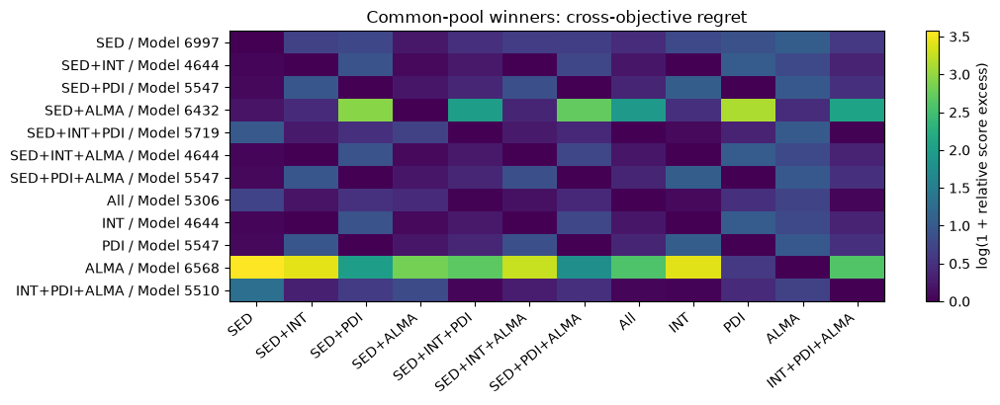

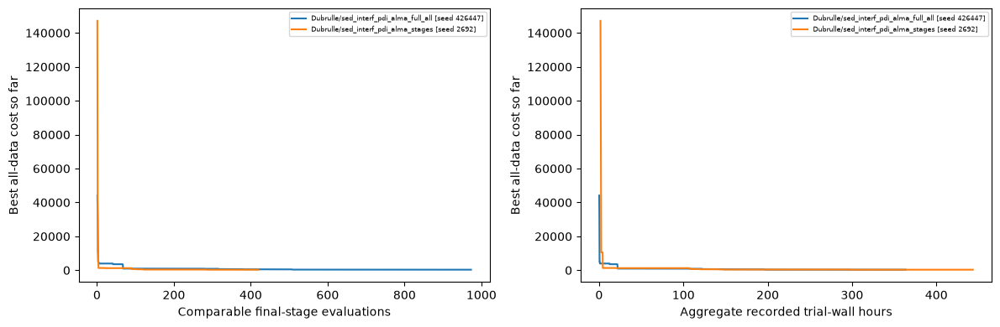

In [22]:
if full_pool_available:
    winner_parts = []
    for objective in scores:
        indices = scores.index[scores[objective].eq(scores[objective].min())]
        winners = pool.loc[indices].copy()
        winners['selected_by'] = objective
        for group in group_scores:
            winners['group_'+group] = group_scores.loc[indices,group]
        winners['all_data_cost'] = scores.loc[indices,'All']
        winner_parts.append(winners)
    common_best = pd.concat(winner_parts,ignore_index=True)
    display(common_best[['selected_by','model_id','history','all_data_cost',
        *['group_'+name for name in GROUPS], *['param__'+name for name in PARAMETERS]]])
    # All tied winners get a separate row rather than averaging their parameter values.
    winner_indices = pool.set_index('evaluation_id').index.get_indexer(common_best.evaluation_id)
    regret = scores.iloc[winner_indices].reset_index(drop=True)
    regret = (regret-scores.min())/scores.min().abs().replace(0,np.nan)
    regret.index = common_best.selected_by+' / '+common_best.model_id
    show('winner_cross_objective_regret',plot_heatmap(np.log1p(regret),
         'Common-pool winners: cross-objective regret', 'log(1 + relative score excess)'))

    # Compare convergence only under the same target objective/compatibility group.
    # Cumulative evaluation time sums all recorded trial durations, including failures/lower stages.
    # It is aggregate trial-wall time, NOT elapsed scheduler time or CPU-hours.
    time_rows = evaluations.sort_values(['history','endtime','record_index']).copy()
    time_rows['aggregate_trial_hours'] = time_rows.time_seconds.fillna(0).clip(lower=0).groupby(time_rows.history).cumsum()/3600
    elapsed = time_rows.set_index('evaluation_id').aggregate_trial_hours
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    progress_parts=[]
    for history,rows in pool.groupby('history',sort=False):
        ordered=rows.sort_values(['endtime','record_index'])
        best=ordered.cost.cummin()
        axes[0].plot(np.arange(1,len(ordered)+1),best,label=history)
        axes[1].plot(ordered.evaluation_id.map(elapsed),best,label=history)
        progress_parts.append(pd.DataFrame({'history':history,'evaluation_id':ordered.evaluation_id,
            'final_evaluation_count':np.arange(1,len(ordered)+1),'best_all_cost':best,
            'aggregate_trial_hours':ordered.evaluation_id.map(elapsed)}))
    for ax,label in zip(axes,['Comparable final-stage evaluations','Aggregate recorded trial-wall hours']):
        ax.set(xlabel=label,ylabel='Best all-data cost so far');ax.legend(fontsize=6)
    fig.tight_layout();show('search_progress',fig)
    progress=pd.concat(progress_parts,ignore_index=True)


## Fully scored supplement — 5. Dataset attribution: actual values, contraction and movement

We compare **every single-group addition** in the factorial design, including leave-one-out additions into All. For example, SED→SED+INT asks what INT adds to SED; SED+PDI+ALMA→All asks what INT adds conditional on the other three. Agreement supports attribution; disagreement indicates interactions or competing preferences.

- `shift`: numeric Wasserstein distance divided by the fixed allowed parameter span (log coordinates for logarithmic parameters), or categorical total-variation distance. It measures distribution change, not necessarily improved constraint.
- `width_ratio`: new/old 10–90% width; below one means restriction. Undefined if the old width is zero. Categories have fractions instead of widths.
- `median_shift`: signed median movement divided by allowed span; log coordinates where declared.
- `sample_jaccard`: overlap of selected model IDs divided by their union; detects reselection.
- `supported`: both selections have at least MIN_MODELS valid values. Sparse results stay in tables but are masked in summary heatmaps.

Value tables include minimum, quartiles, median, maximum, boundary occupancy, category fractions and **all tied best parameter values**. A vector of medians need not correspond to any evaluated model. Physical values preserve saved units; no unit is guessed from an ambiguous name. Numeric categorical choices (e.g. porosity) remain categories. Log-sampling changes metric coordinates, not physical units or scores.

,objective,parameter,kind,n_selected,supported,minimum_in_parameter_units,q10_in_parameter_units,q25_in_parameter_units,median_in_parameter_units,q75_in_parameter_units,q90_in_parameter_units,maximum_in_parameter_units,category_fractions,best_parameter_values,fraction_near_boundary
360,SED,alpha_viscosity,categorical,108,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""0.1"": 0.6851851851851852, ""0.01"": 0.24074074...",[0.1],NaN
361,SED,disk_Rmid,linear,108,True,10.040751,11.717787,15.598214,17.666140,18.647524,18.864743,34.617200,NaN,[10.32218352775],0.018519
362,SED,disk_pa,linear,108,True,0.000000,19.000000,22.000000,107.500000,109.000000,110.000000,177.000000,NaN,[22],0.027778
363,SED,disk_total_dust_mass,log10,108,True,0.000300,0.000989,0.001252,0.002466,0.003732,0.005980,0.043994,NaN,[0.0010496503997],0.000000
364,SED,inclination,linear,108,True,0.000000,0.000000,4.000000,7.000000,9.000000,16.000000,26.000000,NaN,[5],0.120370
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
535,INT+PDI+ALMA,zone_1_species_1_porosity,categorical,212,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""0.0"": 0.09433962264150944, ""0.3"": 0.35377358...",[0.3],NaN
536,INT+PDI+ALMA,zone_1_surface_density_exp,linear,212,True,1.606664,1.668871,1.680505,3.006853,3.630624,3.729024,3.998767,NaN,[1.680155062913],0.004717
537,INT+PDI+ALMA,zone_2_-gamma_exp,linear,212,True,-1.869853,-1.179434,-1.080845,-0.738983,-0.350336,-0.194280,-0.104541,NaN,[-0.1369577836508],0.047170
538,INT+PDI+ALMA,zone_2_Rc,linear,212,True,60.000000,63.000000,67.000000,70.000000,72.000000,75.000000,237.000000,NaN,[68],0.127358


,scope,mode,level,objective,n_pool,n_selected,cutoff,best_score
0,pooled,allowance,0.1,SED,1393,17,19.287205,17.533823
1,pooled,allowance,0.1,SED+INT,1393,20,149.599662,135.999693
2,pooled,allowance,0.1,SED+PDI,1393,1,116.336936,105.760851
3,pooled,allowance,0.1,SED+ALMA,1393,11,41.461606,37.692370
4,pooled,allowance,0.1,SED+INT+PDI,1393,24,329.651602,299.683274
...,...,...,...,...,...,...,...,...
67,pooled,fraction,0.2,All,1393,279,551.718309,325.883644
68,pooled,fraction,0.2,INT,1393,279,190.790168,117.368670
69,pooled,fraction,0.2,PDI,1393,279,201.706293,86.805179
70,pooled,fraction,0.2,ALMA,1393,279,21.905606,10.415510


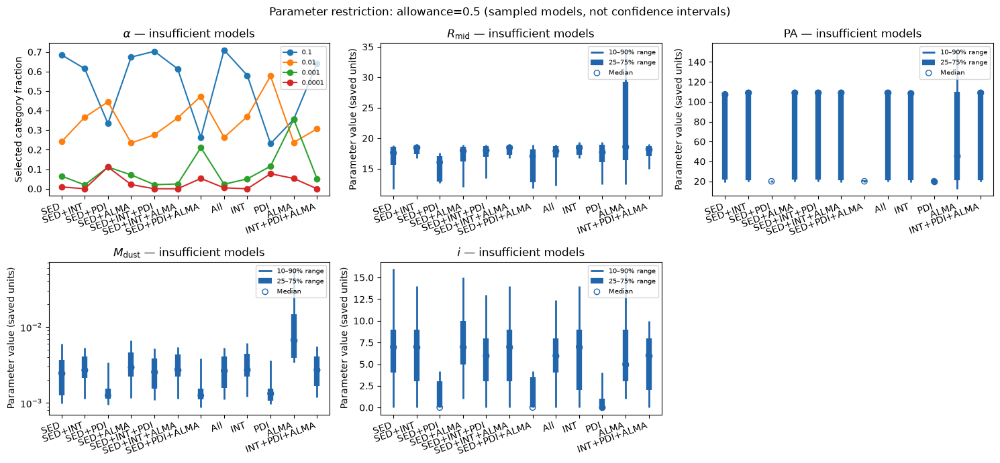

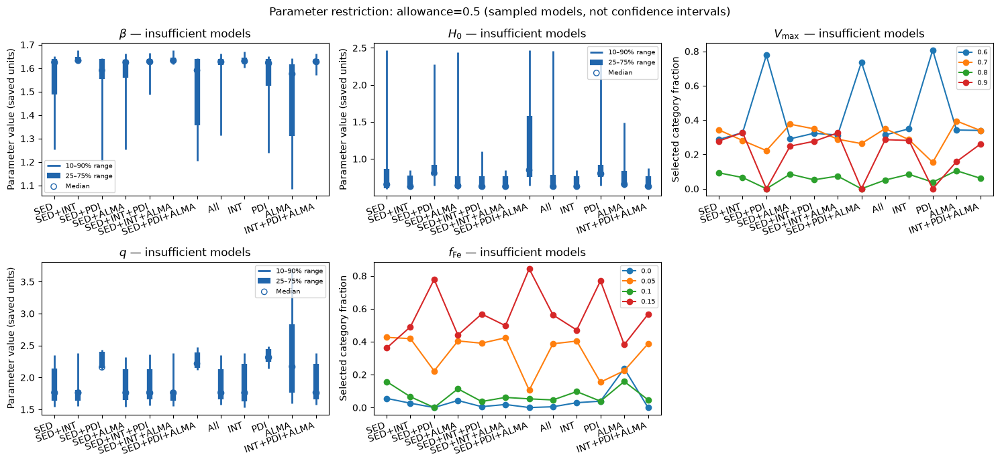

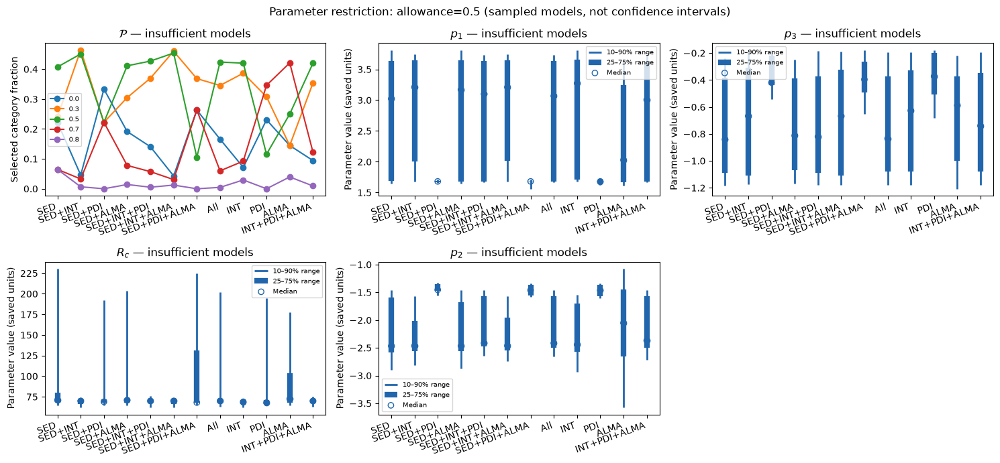

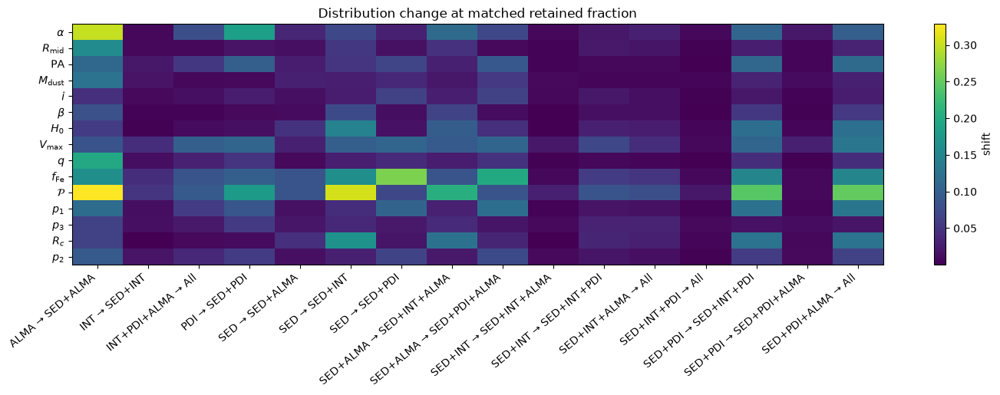

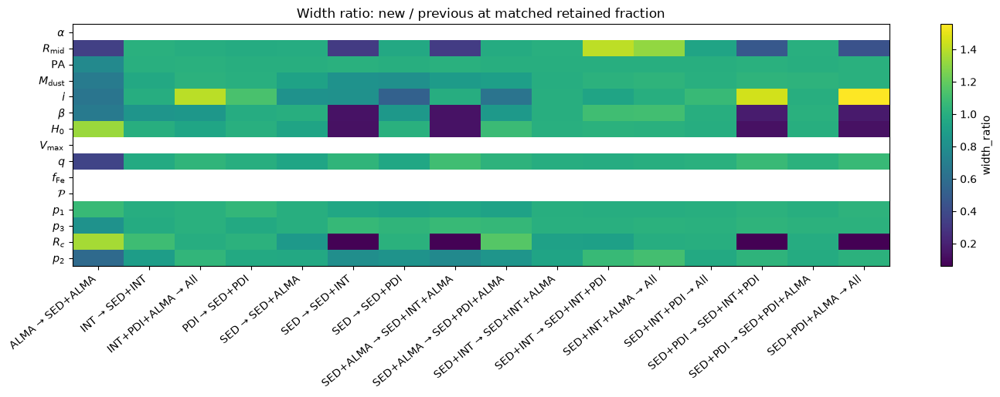

In [23]:
if full_pool_available:
    selection_levels={'allowance':sorted(set(RELATIVE_ALLOWANCES+[DISPLAY_ALLOWANCE])),
                      'fraction':sorted(set(MATCHED_FRACTIONS+[DISPLAY_FRACTION]))}

    metrics,selection_counts,effects=restriction_tables(pool,scores,definitions,references,additions,
        selection_levels,ABSOLUTE_ALLOWANCE,MIN_MODELS)

    main_values=metrics[(metrics.scope=='pooled') & (metrics['mode']=='allowance')
                       & np.isclose(metrics.level,DISPLAY_ALLOWANCE)].copy()

    value_columns=['objective','parameter','kind','n_selected','supported','minimum_in_parameter_units',
        'q10_in_parameter_units','q25_in_parameter_units','median_in_parameter_units',
        'q75_in_parameter_units','q90_in_parameter_units','maximum_in_parameter_units',
        'category_fractions','best_parameter_values','fraction_near_boundary']

    display(main_values.reindex(columns=value_columns))
    display(selection_counts[selection_counts.scope.eq('pooled')])

    # Actual value intervals, not only width. All objectives are comparisons, not a chronological sequence.
    order={name:i for i,name in enumerate(objectives)}
    plot_metrics=metrics[metrics.scope.eq('pooled')].copy()
    plot_metrics['step']=plot_metrics.objective.map(order)
    plot_metrics['subset']=plot_metrics.objective
    for first in range(0,len(PARAMETERS),5):
        show(f'parameter_values_{first}',plot_restriction(plot_metrics,PARAMETERS[first:first+5],
                                                       mode='allowance',value=DISPLAY_ALLOWANCE))
    matched=effects[(effects.scope=='pooled')&(effects['mode']=='fraction')
                    &np.isclose(effects.level,DISPLAY_FRACTION)].copy()

    matched['contrast']=matched.before+' → '+matched.after

    for field,title in [('shift','Distribution change'),('width_ratio','Width ratio: new / previous')]:
        matrix=matched.assign(value=matched[field].where(matched.supported)).pivot(
            index='parameter',columns='contrast',values='value')
        show('attribution_'+field,plot_heatmap(matrix,title+' at matched retained fraction',field))


## Fully scored supplement — 6. Robustness: thresholds, histories, prefixes and statistical uncertainty

A restriction should survive more than one allowance, the matched-fraction control, and comparisons within source histories. Pooled effects can be driven by unequal sampling density (973 versus 420 candidates in the initial test). Per-history results and leave-one-history-out results expose that; they do not erase sampling bias. Chronological prefix checks ask whether values and best costs keep moving as more candidates arrive.

**Statistical reporting:** do not attach ordinary KS-test, correlation or permutation p-values to thousands of optimiser-selected rows. Trials are adaptive, dependent and not draws from a parameter posterior. Resampling individual rows does not create independent experiments. Report effect sizes, sample counts, threshold sensitivity and history variation now.

An optional bootstrap below requires at least five **explicitly verified independent, comparable histories**. It resamples history-level effects; its interval describes repeatability of mean distribution shift under that run design. It is not a physical parameter confidence interval and five runs are a practical minimum, not a universal guarantee. The current all-data and staged histories are different strategies, so the default list is empty and no interval is fabricated. For calibrated parameter uncertainty, use a validated likelihood with reoptimised profiles or simulation-based coverage tests on mock observations.

In [24]:
if full_pool_available:
    robustness=effects[effects.scope.ne('pooled')].copy()
    display(robustness[(robustness['mode']=='fraction')&np.isclose(robustness.level,DISPLAY_FRACTION)])
    # Each row is a history/objective best and selected parameter distribution.
    history_values=metrics[(metrics.scope!='pooled')&(metrics['mode']=='allowance')
                          &np.isclose(metrics.level,DISPLAY_ALLOWANCE)]
    display(history_values[history_values.objective.eq('All')].reindex(columns=['scope',*value_columns]))

    prefix_rows=[]
    for history,rows in pool.groupby('history',sort=False):
        ordered=rows.sort_values(['endtime','record_index'])
        for fraction in PREFIX_FRACTIONS:
            prefix=ordered.iloc[:max(1,int(np.ceil(len(ordered)*fraction)))]
            keep,cutoff=competitive_mask(scores.loc[prefix.index,'All'],'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
            sample=prefix.loc[keep]
            for name,ref in references.items():
                from observation_convergence_utils import parameter_metrics
                row,_,_=parameter_metrics(prefix,sample,name,definitions[name],min_models=MIN_MODELS,reference=ref)
                prefix_rows.append(dict(history=history,prefix_fraction=fraction,best_cost=scores.loc[prefix.index,'All'].min(),**row))
    prefix_stability=pd.DataFrame(prefix_rows)
    display(prefix_stability.reindex(columns=['history','prefix_fraction','parameter','n_selected','supported',
        'best_cost','q10_in_parameter_units','median_in_parameter_units','q90_in_parameter_units']))
    # With two histories, these comparisons are simply each history versus the pooled selection.
    keep,_=competitive_mask(scores.All,'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
    pooled_selected=pool.loc[keep]
    leave_history_rows=[]
    for history in pool.history.unique():
        remaining=pool[pool.history.ne(history)]
        if remaining.empty:continue
        selected_mask,_=competitive_mask(scores.loc[remaining.index,'All'],'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
        for name,ref in references.items():
            leave_history_rows.append(dict(omitted_history=history,parameter=name,
                **distribution_effect(pooled_selected,remaining.loc[selected_mask],name,ref)))
    leave_history_out=pd.DataFrame(leave_history_rows)
    display(leave_history_out)
    bootstrap_intervals=pd.DataFrame()
    if VERIFIED_REPLICATE_HISTORIES:
        if not set(VERIFIED_REPLICATE_HISTORIES)<=set(pool.history):
            raise ValueError('Unknown verified history names.')
        bootstrap_intervals=bootstrap_history_effects(effects,VERIFIED_REPLICATE_HISTORIES,
                                                     BOOTSTRAP_REPETITIONS,RANDOM_SEED)
        display(bootstrap_intervals)
    else:
        print('No verified replicate design: reporting descriptive robustness, not bootstrap confidence intervals.')


,scope,mode,level,before,after,added,parameter,kind,sample_jaccard,supported,n_before,n_after,shift,width_ratio,median_shift
2400,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,fraction,0.1,SED,SED+INT,INT,alpha_viscosity,categorical,0.507692,True,98,98,0.091837,NaN,NaN
2401,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,fraction,0.1,SED,SED+INT,INT,disk_Rmid,linear,0.507692,True,98,98,0.019084,0.694167,0.003738
2402,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,fraction,0.1,SED,SED+INT,INT,disk_pa,linear,0.507692,True,98,98,0.014909,0.634921,0.000000
2403,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,fraction,0.1,SED,SED+INT,INT,disk_total_dust_mass,log10,0.507692,True,98,98,0.025543,0.684367,-0.001654
2404,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,fraction,0.1,SED,SED+INT,INT,inclination,linear,0.507692,True,98,98,0.038163,0.666667,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4075,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],fraction,0.1,INT+PDI+ALMA,All,SED,zone_1_species_1_porosity,categorical,0.448276,True,42,42,0.119048,NaN,NaN
4076,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],fraction,0.1,INT+PDI+ALMA,All,SED,zone_1_surface_density_exp,linear,0.448276,True,42,42,0.000475,1.017741,0.000000
4077,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],fraction,0.1,INT+PDI+ALMA,All,SED,zone_2_-gamma_exp,linear,0.448276,True,42,42,0.011426,0.966396,-0.002461
4078,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],fraction,0.1,INT+PDI+ALMA,All,SED,zone_2_Rc,linear,0.448276,True,42,42,0.034837,1.297581,0.000000


,scope,objective,parameter,kind,n_selected,supported,minimum_in_parameter_units,q10_in_parameter_units,q25_in_parameter_units,median_in_parameter_units,q75_in_parameter_units,q90_in_parameter_units,maximum_in_parameter_units,category_fractions,best_parameter_values,fraction_near_boundary
1545,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,alpha_viscosity,categorical,148,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""0.1"": 0.8581081081081081, ""0.01"": 0.14189189...",[0.1],NaN
1546,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,disk_Rmid,linear,148,True,10.599592,16.532918,17.025522,18.345998,18.686839,18.973678,22.205216,NaN,[18.711771211785],0.006757
1547,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,disk_pa,linear,148,True,107.000000,108.000000,109.000000,110.000000,110.000000,111.000000,113.000000,NaN,[109],0.000000
1548,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,disk_total_dust_mass,log10,148,True,0.001325,0.002302,0.002495,0.003177,0.004625,0.005730,0.022131,NaN,[0.0023194728269],0.000000
1549,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,inclination,linear,148,True,0.000000,4.000000,6.000000,7.000000,9.000000,14.000000,17.000000,NaN,[8],0.013514
1550,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,zone_1_flaring_exp,linear,148,True,1.468500,1.602473,1.625320,1.627696,1.635294,1.668004,1.873334,NaN,[1.627379099739],0.000000
1551,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,zone_1_scale_height,linear,148,True,0.501067,0.587605,0.597693,0.612015,0.629368,0.696150,0.759404,NaN,[0.629450095884],0.033784
1552,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,zone_1_species_1_Vmax,categorical,148,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""0.6"": 0.17567567567567569, ""0.7"": 0.33783783...",[0.7],NaN
1553,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,zone_1_species_1_aexp,linear,148,True,1.507056,1.530960,1.601129,1.707111,1.763223,1.771180,1.774260,NaN,[1.7711690395832],0.121622
1554,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,All,zone_1_species_1_component_2_volume_fraction_iron,categorical,148,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""0.0"": 0.006756756756756757, ""0.05"": 0.547297...",[0.05],NaN


,history,prefix_fraction,parameter,n_selected,supported,best_cost,q10_in_parameter_units,median_in_parameter_units,q90_in_parameter_units
0,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.5,alpha_viscosity,22,True,510.980146,NaN,NaN,NaN
1,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.5,disk_Rmid,22,True,510.980146,17.044295,18.919323,19.513663
2,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.5,disk_pa,22,True,510.980146,66.200000,110.000000,110.000000
3,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.5,disk_total_dust_mass,22,True,510.980146,0.002355,0.006532,0.010401
4,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.5,inclination,22,True,510.980146,3.400000,22.500000,26.000000
...,...,...,...,...,...,...,...,...,...
85,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],1.0,zone_1_species_1_porosity,70,True,325.883644,NaN,NaN,NaN
86,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],1.0,zone_1_surface_density_exp,70,True,325.883644,1.614403,1.677233,1.689055
87,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],1.0,zone_2_-gamma_exp,70,True,325.883644,-0.889857,-0.413108,-0.145891
88,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],1.0,zone_2_Rc,70,True,325.883644,66.900000,69.000000,233.300000


,omitted_history,parameter,n_before,n_after,shift,width_ratio,median_shift
0,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,alpha_viscosity,217,70,0.309677,NaN,NaN
1,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,disk_Rmid,217,70,0.048950,1.095774,-0.016390
2,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,disk_pa,217,70,0.336505,0.054945,-0.494444
3,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,disk_total_dust_mass,217,70,0.093868,0.623122,-0.111176
4,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,inclination,217,70,0.080129,0.403226,-0.110000
5,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,zone_1_flaring_exp,217,70,0.075720,1.148192,-0.003391
6,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,zone_1_scale_height,217,70,0.243657,1.117189,0.099812
7,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,zone_1_species_1_Vmax,217,70,0.307834,NaN,NaN
8,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,zone_1_species_1_aexp,217,70,0.156993,0.433539,0.189466
9,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,zone_1_species_1_component_2_volume_fraction_iron,217,70,0.348848,NaN,NaN


No verified replicate design: reporting descriptive robustness, not bootstrap confidence intervals.


## Fully scored supplement — 7. Sensitivity and compensation are different questions

A parameter is **sensitive** when changing it affects predictions/score. It is **identifiable** only if other parameters cannot compensate while preserving fit. Marginal score correlations are insufficient for either global sensitivity or identifiability in adaptive samples.

Here we implement two exploratory checks:
1. Paired numeric Spearman associations in all candidates versus the selected sample, separately by history as well as pooled. Strong selected associations suggest trade-offs to investigate; a mixture of solution families or conditioning on low total score can itself create correlations. Zero correlation does not exclude curved or higher-dimensional compensation. Categories are excluded from numeric correlation and handled in mixed-distance families.
2. Sampled score envelopes by parameter bin/category, with counts. They show where good saved models exist; they are **not profile likelihoods**, because the other parameters were not reoptimised at each value. Sparse bins are masked. A high envelope in an unsampled region cannot establish exclusion.

For a stronger follow-up, fix each suspect parameter at 10–20 grid values and reoptimise the others from multiple family seeds. Then profile pairs showing compensation. A validated emulator can accelerate that design, but validate on held-out whole histories and fresh space-filling simulations before computing fANOVA/Sobol effects. Surrogate importance depends on the chosen input measure and does not establish identifiability ([Hutter et al. 2014](https://proceedings.mlr.press/v32/hutter14.html)).

,x,y,n_all,rho_all,n_selected,rho_selected,change_in_rho,scope
142,inclination,zone_2_Rc,420,0.450575,70,0.796730,0.346155,Dubrulle/sed_interf_pdi_alma_stages [seed 2692]
152,zone_1_scale_height,zone_2_-gamma_exp,420,-0.465869,70,-0.780428,-0.314559,Dubrulle/sed_interf_pdi_alma_stages [seed 2692]
162,zone_2_-gamma_exp,zone_2_Rc,420,-0.526679,70,-0.772625,-0.245946,Dubrulle/sed_interf_pdi_alma_stages [seed 2692]
45,zone_1_species_1_aexp,zone_1_surface_density_exp,1393,-0.342447,217,-0.770108,-0.427660,pooled
148,zone_1_flaring_exp,zone_2_Rc,420,-0.482930,70,-0.769984,-0.287054,Dubrulle/sed_interf_pdi_alma_stages [seed 2692]
137,inclination,zone_1_flaring_exp,420,-0.346233,70,-0.762765,-0.416532,Dubrulle/sed_interf_pdi_alma_stages [seed 2692]
15,disk_pa,zone_1_surface_density_exp,1393,0.391577,217,0.760995,0.369418,pooled
14,disk_pa,zone_1_species_1_aexp,1393,-0.148270,217,-0.743104,-0.594833,pooled
145,zone_1_flaring_exp,zone_1_species_1_aexp,420,0.059998,70,0.742739,0.682740,Dubrulle/sed_interf_pdi_alma_stages [seed 2692]
113,disk_Rmid,zone_1_flaring_exp,420,0.068891,70,0.721634,0.652743,Dubrulle/sed_interf_pdi_alma_stages [seed 2692]


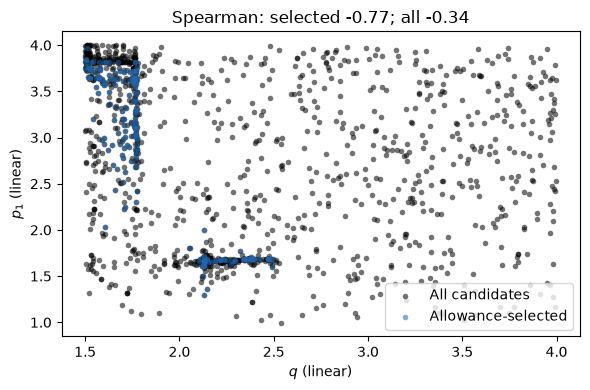

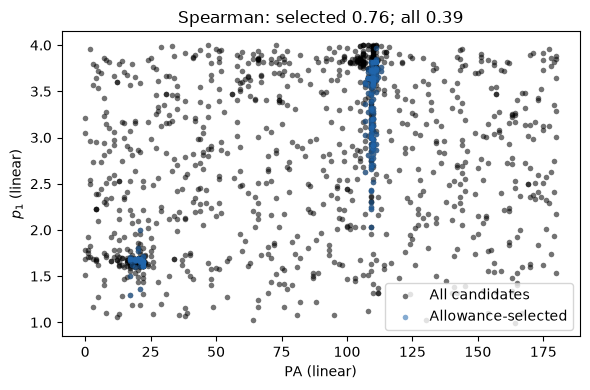

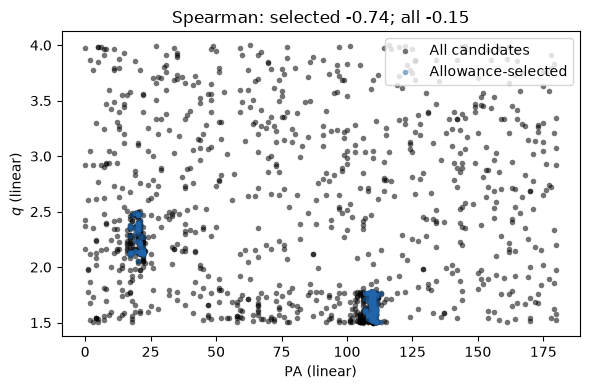

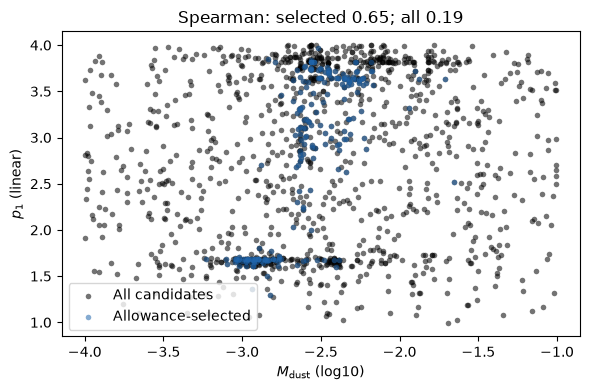

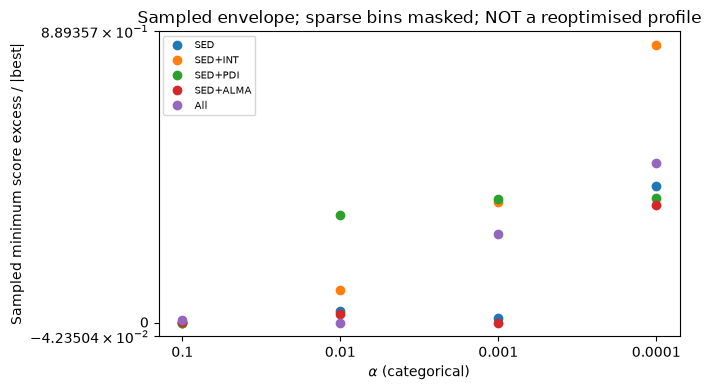

...

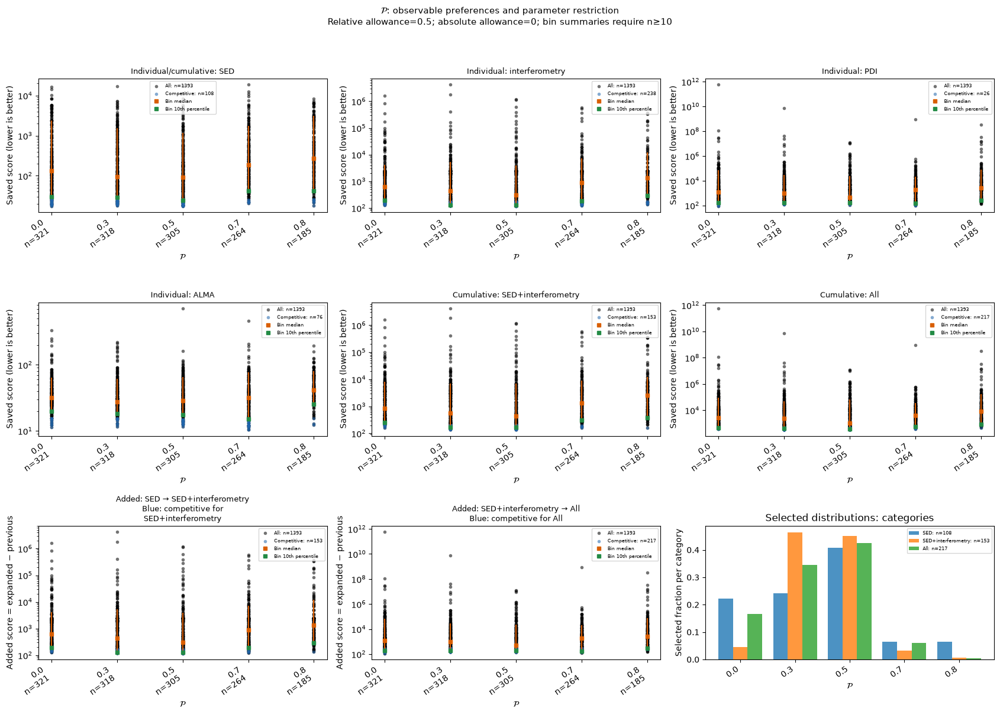

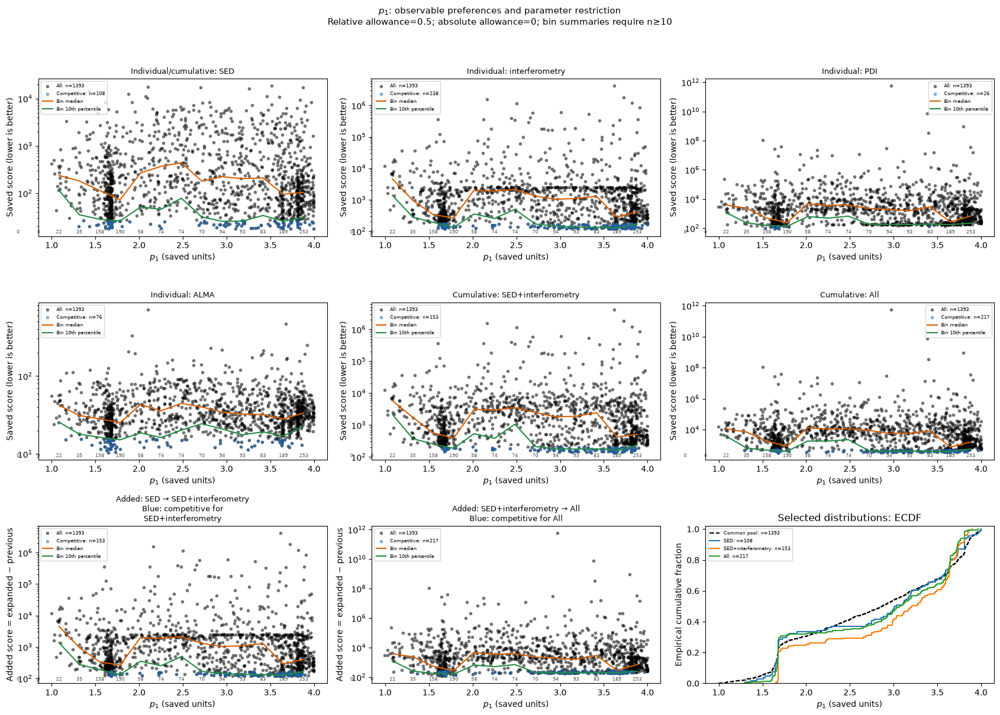

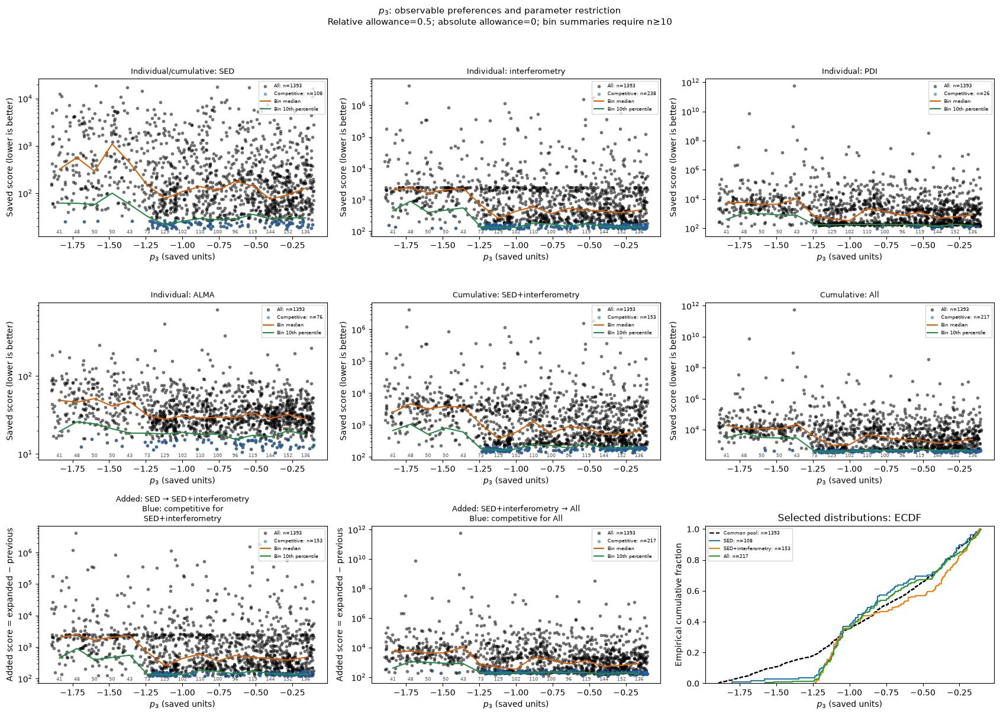

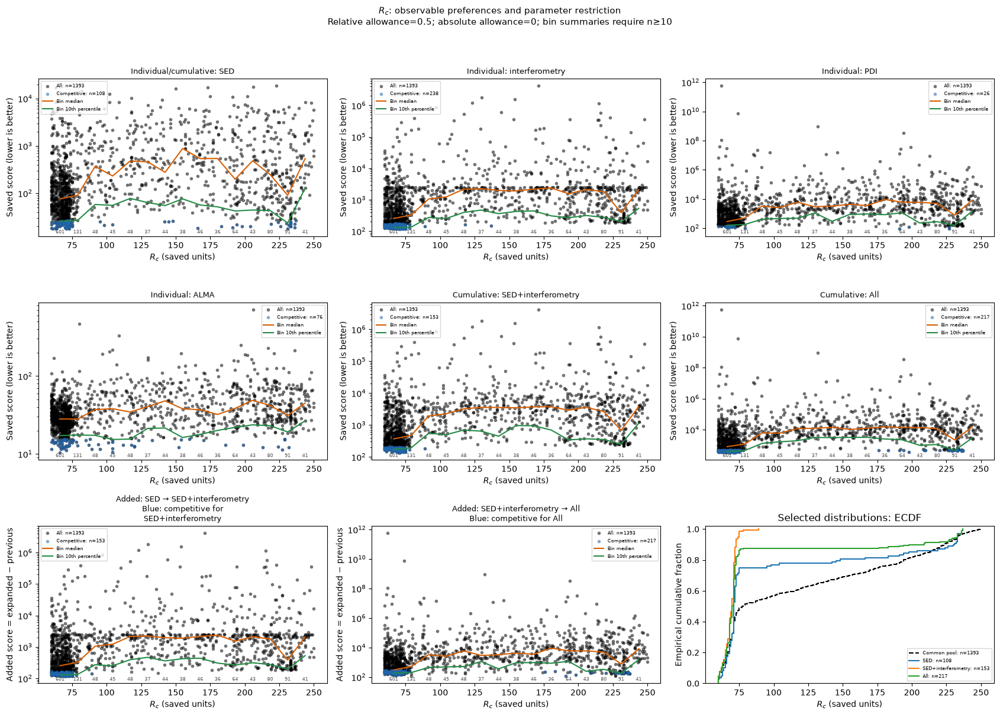

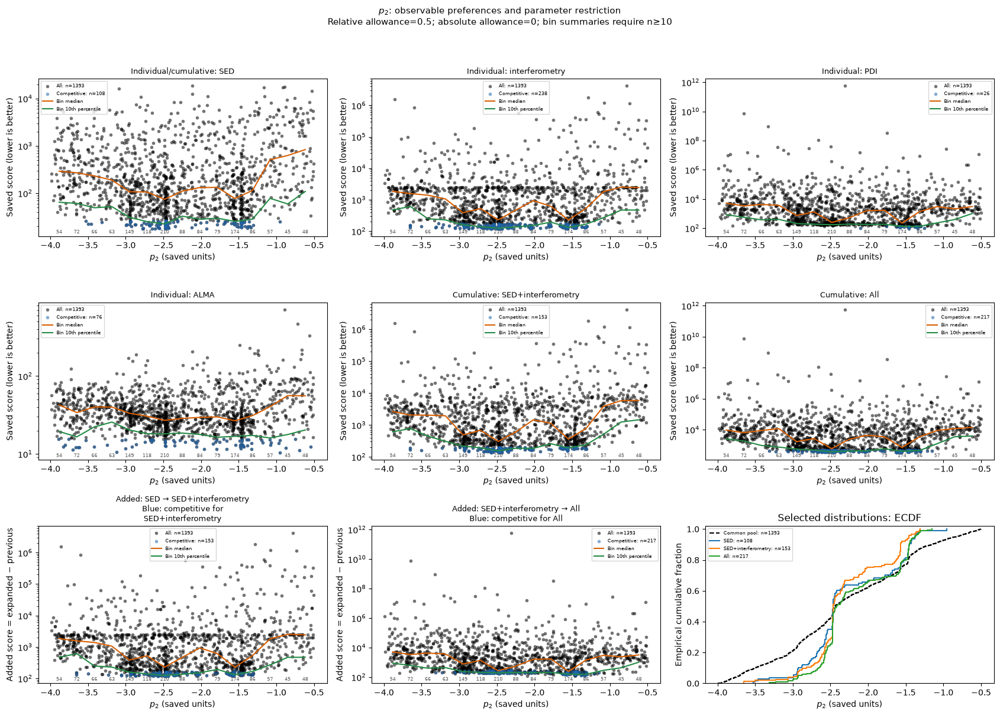

In [25]:
if full_pool_available:
    pair_parts=[]
    for scope,rows in [('pooled',pool),*pool.groupby('history',sort=False)]:
        keep,_=competitive_mask(scores.loc[rows.index,'All'],'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
        table=association_table(rows,rows.loc[keep],references,MIN_MODELS)
        table['scope']=scope;pair_parts.append(table)
    associations=pd.concat(pair_parts,ignore_index=True)
    display(associations.sort_values('rho_selected',key=lambda x:x.abs(),ascending=False).head(30))
    strongest=associations[associations.scope.eq('pooled')].dropna(subset=['rho_selected']).sort_values(
        'rho_selected',key=lambda x:x.abs(),ascending=False).head(PAIR_PLOTS)
    for row in strongest.itertuples():
        fig,ax=plt.subplots(figsize=(6,4))
        for frame,color,label in [(pool,'black','All candidates'),(pooled_selected,'#2166ac','Allowance-selected')]:
            x=parameter_values(frame,row.x,references[row.x]);y=parameter_values(frame,row.y,references[row.y])
            paired=pd.concat([x.rename('x'),y.rename('y')],axis=1).dropna()
            ax.scatter(paired.x,paired.y,s=POINT_SIZE,alpha=POINT_ALPHA,color=color,marker='o',linewidths=0,label=label)
        ax.set(xlabel=f'{parameter_label(row.x)} ({references[row.x]["kind"]})',ylabel=f'{parameter_label(row.y)} ({references[row.y]["kind"]})',
               title=f'Spearman: selected {row.rho_selected:.2f}; all {row.rho_all:.2f}')
        ax.legend();fig.tight_layout();show('pair_'+row.x+'_'+row.y,fig)

    # All model parameters, using the same coordinate definitions as View A.
    profile_references = cost_references
    profiles=empirical_profiles(pool,scores,profile_references,PROFILE_MIN_MODELS)
    for name in profile_references:
        if name not in profile_references:
            print('Skipping unavailable profile:',name);continue
        fig,ax=plt.subplots(figsize=(7,4))
        for objective in ['SED','SED+INT','SED+PDI','SED+ALMA','All']:
            rows=profiles[(profiles.parameter==name)&(profiles.objective==objective)]
            denominator=abs(scores[objective].min())
            if denominator==0:continue
            ax.plot(rows.position,(rows.excess_minimum/denominator).where(rows.supported),
                    marker='o',linestyle='none' if profile_references[name]['kind']=='categorical' else '-',label=objective)
        if profile_references[name]['kind']=='categorical':
            ax.set_xticks(range(len(profile_references[name]['categories'])),profile_references[name]['categories'])
        ax.set(xlabel=f'{parameter_label(name)} ({profile_references[name]["kind"]})',ylabel='Sampled minimum score excess / |best|',
               title='Sampled envelope; sparse bins masked; NOT a reoptimised profile')
        ax.set_yscale('symlog',linthresh=1);ax.legend(fontsize=7);fig.tight_layout();show('profile_'+name,fig)
    # Detailed original-score scatter, binned medians/deciles and distributions.
    # This label is an explicit rescoring experiment, not a claimed historical sequence.
    for name in profile_references:
        if name not in profile_references:continue
        fig,_,_=parameter_score_diagnostic(pool,name,profile_references[name],['SED','SED+interferometry','All'],
            allowance=DISPLAY_ALLOWANCE,absolute_allowance=ABSOLUTE_ALLOWANCE,
            min_bin_models=PROFILE_MIN_MODELS,score_scale='log',point_size=POINT_SIZE,point_alpha=POINT_ALPHA)
        show('score_values_'+name,fig)


## Fully scored supplement — 8. Are different parameter combinations competitive?

We retain candidates within FAMILY_ALLOWANCE of the all-data minimum, then calculate a mixed distance: mean absolute span-scaled numeric difference (log coordinates where declared), with 0/1 differences for categories. Every varied parameter gets equal weight. This is an interpretable **diagnostic convention**, not a physical equivalence metric; correlated/derived parameters must not be counted twice. Missing or out-of-bound values stop the distance calculation rather than being imputed.

Complete-linkage grouping is repeated at several distance cuts. Distinct groups with comparable costs are sampled alternative families, not statistically established modes. Dependence on cut, allowance and history must be inspected. A single group cannot prove uniqueness. PA remains linear; no circular wrapping is introduced.

The Pareto set contains candidates for which no other saved candidate is at least as good in every observable group and strictly better in one. This reveals trade-offs without changing score weights. Comparable scalar scores do **not** mean the same predicted data: the retained evaluation IDs identify models for later residual/image/visibility comparison and independent noise repeats.

,distance_cut,family,n,best_score,best_ids,histories,largest_distance_to_best,cutoff
0,0.1,1,10,325.883644,"[""Dubrulle/sed_interf_pdi_alma_stages [seed 26...",Dubrulle/sed_interf_pdi_alma_stages [seed 2692],0.075451,358.472009
1,0.1,2,1,354.460127,"[""Dubrulle/sed_interf_pdi_alma_stages [seed 26...",Dubrulle/sed_interf_pdi_alma_stages [seed 2692],0.161203,358.472009
2,0.1,3,6,328.441622,"[""Dubrulle/sed_interf_pdi_alma_full_all [seed ...",Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.432625,358.472009
3,0.1,4,5,350.034292,"[""Dubrulle/sed_interf_pdi_alma_full_all [seed ...",Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.430777,358.472009
4,0.1,5,4,332.768300,"[""Dubrulle/sed_interf_pdi_alma_full_all [seed ...",Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.363416,358.472009
5,0.1,6,1,343.979807,"[""Dubrulle/sed_interf_pdi_alma_full_all [seed ...",Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.329640,358.472009
6,0.1,7,1,356.626765,"[""Dubrulle/sed_interf_pdi_alma_full_all [seed ...",Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.344072,358.472009
7,0.1,8,1,350.754745,"[""Dubrulle/sed_interf_pdi_alma_full_all [seed ...",Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.291713,358.472009
8,0.1,9,1,355.157522,"[""Dubrulle/sed_interf_pdi_alma_full_all [seed ...",Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.367880,358.472009
9,0.1,10,1,351.328166,"[""Dubrulle/sed_interf_pdi_alma_full_all [seed ...",Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,0.218662,358.472009


,model_id,history,objective_score,score_excess,distance_to_best,param__alpha_viscosity,param__disk_Rmid,param__disk_pa,param__disk_total_dust_mass,param__inclination,param__zone_1_flaring_exp,param__zone_1_scale_height,param__zone_1_species_1_Vmax,param__zone_1_species_1_aexp,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_2_-gamma_exp,param__zone_2_Rc,param__zone_2_surface_density_exp
14,Model 4889,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,348.240779,22.357134,0.432625,0.10,18.655307,109,0.002246,9,1.624002,0.596913,0.7,1.772237,0.05,0.5,3.729082,-1.235648,61,-2.611047
0,Model 4600,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,350.034292,24.150648,0.430777,0.10,17.025522,109,0.003169,7,1.625789,0.596913,0.9,1.525761,0.05,0.5,3.646483,-1.047819,71,-2.471084
19,Model 4964,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,343.346465,17.462821,0.430366,0.10,16.167399,109,0.002319,7,1.684414,0.599071,0.7,1.773216,0.05,0.5,3.497196,-1.166859,71,-2.678837
12,Model 4810,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,343.628782,17.745137,0.427727,0.10,17.025522,109,0.003324,5,1.625789,0.597728,0.7,1.766688,0.05,0.5,3.595533,-1.108966,73,-2.660416
3,Model 4628,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,352.688897,26.805253,0.418656,0.10,18.167702,109,0.002105,9,1.630495,0.596913,0.9,1.753253,0.05,0.5,3.392733,-1.125095,71,-2.471084
15,Model 4918,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,328.441622,2.557978,0.414368,0.10,18.711771,109,0.002319,8,1.627379,0.629450,0.7,1.771169,0.05,0.5,2.853411,-1.152520,71,-2.877700
9,Model 4739,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,353.563741,27.680096,0.414198,0.10,18.691385,109,0.002496,10,1.628332,0.596913,0.9,1.763138,0.05,0.5,3.105812,-1.107147,71,-2.471084
5,Model 4694,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,346.713450,20.829806,0.413646,0.10,18.593174,109,0.002461,7,1.630495,0.602120,0.7,1.651410,0.05,0.5,3.191182,-1.080644,71,-2.471084
13,Model 4882,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,353.532314,27.648669,0.410777,0.10,18.711771,109,0.002319,7,1.625789,0.597728,0.7,1.771169,0.05,0.5,3.034814,-1.157202,66,-2.538027
4,Model 4686,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,355.157522,29.273877,0.367880,0.10,17.004146,110,0.005399,8,1.661320,0.624361,0.7,1.763469,0.05,0.3,3.720150,-1.081450,63,-2.473879


,model_id,history,group_SED,group_INT,group_PDI,group_ALMA
257,Model 4179,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,136.536293,1998.703179,173.581330,11.512129
295,Model 4221,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,35.764971,371.161360,1858.971519,13.099721
306,Model 4234,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,59.841670,707.303244,3988.079722,12.103022
383,Model 4319,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,264.277663,1080.300459,767.241048,11.388233
520,Model 4472,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,19.651504,121.271386,211.921872,18.133393
...,...,...,...,...,...,...
1343,Model 5719,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],47.757332,128.814984,123.110959,28.769340
1344,Model 5730,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],20.224168,204.792962,122.784155,23.418608
1351,Model 5768,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],166.813140,129.804095,126.283906,19.700629
1363,Model 5830,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],52.659030,150.911128,131.730622,19.159347


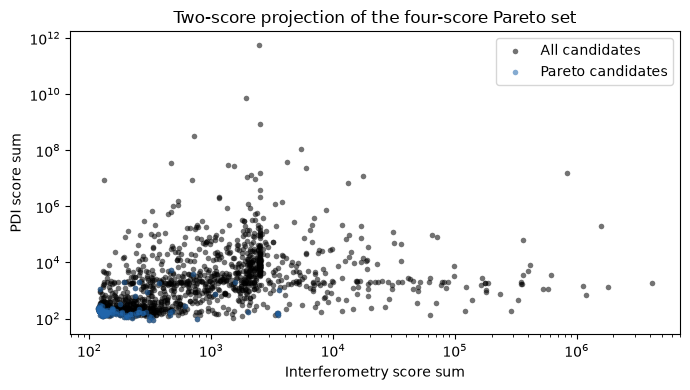

sampled_families  selected_candidates
allowance distance_cut                                       
0.10      0.1                         10                   31
          0.2                          4                   31
          0.3                          3                   31
0.25      0.1                         23                   91
          0.2                         12                   91
          0.3                          5                   91
0.50      0.1                         50                  217
          0.2                         20                  217
          0.3                          8                  217

,x,y,n_all,rho_all,n_selected,rho_selected,change_in_rho,distance_cut,family


Within-family correlations are masked when fewer than MIN_MODELS candidates are available.


In [26]:
if full_pool_available:
    family_members,family_summary=alternative_families(pool,scores.All,references,FAMILY_ALLOWANCE,
        ABSOLUTE_ALLOWANCE,FAMILY_DISTANCE_CUTS)
    display(family_summary)
    # One copy per evaluation for the candidate follow-up table; clustering cuts remain in family_members.
    alternatives=family_members.drop_duplicates('evaluation_id').copy()
    display(alternatives[['model_id','history','objective_score','score_excess','distance_to_best',
                          *['param__'+name for name in PARAMETERS]]].sort_values('distance_to_best',ascending=False))
    pareto=pool.loc[pareto_mask(group_scores)].copy()
    for group in GROUPS:pareto['group_'+group]=group_scores.loc[pareto.index,group]
    display(pareto[['model_id','history',*['group_'+name for name in GROUPS]]])
    fig,ax=plt.subplots(figsize=(7,4))
    for frame,color,label in [(pool,'black','All candidates'),(pareto,'#2166ac','Pareto candidates')]:
        ax.scatter(group_scores.loc[frame.index,'INT'],group_scores.loc[frame.index,'PDI'],
                   color=color,s=POINT_SIZE,alpha=POINT_ALPHA,marker='o',linewidths=0,label=label)
    ax.set(xlabel='Interferometry score sum',ylabel='PDI score sum',title='Two-score projection of the four-score Pareto set')
    if group_scores.INT.gt(0).all():ax.set_xscale('log')
    if group_scores.PDI.gt(0).all():ax.set_yscale('log')
    ax.legend();fig.tight_layout();show('pareto_projection',fig)

    # Repeat family counting across tolerances. Families may merge/split with either setting.
    family_resolution_parts=[]
    for allowance in sorted(set(RELATIVE_ALLOWANCES+[FAMILY_ALLOWANCE])):
        _,summary=alternative_families(pool,scores.All,references,allowance,
                                      ABSOLUTE_ALLOWANCE,FAMILY_DISTANCE_CUTS)
        summary['allowance']=allowance;family_resolution_parts.append(summary)
    family_resolution=pd.concat(family_resolution_parts,ignore_index=True)
    display(family_resolution.groupby(['allowance','distance_cut']).agg(
        sampled_families=('family','size'),selected_candidates=('n','sum')))
    # Inspect whether pooled associations persist within a family; do not infer them from mixtures.
    family_pair_parts=[]
    for (cut,family),members in family_members.groupby(['distance_cut','family']):
        frame=pool.loc[pool.evaluation_id.isin(members.evaluation_id)]
        table=association_table(pool,frame,references,MIN_MODELS)
        table['distance_cut']=cut;table['family']=family
        family_pair_parts.append(table)
    family_associations=pd.concat(family_pair_parts,ignore_index=True)
    display(family_associations.dropna(subset=['rho_selected']).head(20))
    print('Within-family correlations are masked when fewer than MIN_MODELS candidates are available.')


## Fully scored supplement — 9. Explicit weight sensitivity experiment

The original objective remains unchanged. This section **only** rescales one observable group's contribution by WEIGHT_FACTORS in a temporary analysis vector. It asks whether reasonable changes to arbitrary relative priorities switch the winning family. This is particularly relevant for empirical PDI weights and ALMA energy normalisation. It does not propose a corrected likelihood or select preferred new weights. It changes observational influence and therefore must be labelled separately from original-score results.

The selection-overlap statistic compares each perturbed allowance-selected set with the original all-data selection. A different winner with a nearly unchanged original cost may indicate a fragile choice among competitive alternatives.

In [27]:
if full_pool_available:
    weight_rows=[]
    original_mask,_=competitive_mask(scores.All,'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
    original_ids=set(pool.loc[original_mask,'evaluation_id'])
    for group in GROUPS:
        for factor in WEIGHT_FACTORS:
            perturbed=scores.All+(factor-1)*group_scores[group]
            mask,_=competitive_mask(perturbed,'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
            selected_ids=set(pool.loc[mask,'evaluation_id'])
            winners=pool.loc[perturbed.eq(perturbed.min())]
            for index,row in winners.iterrows():
                weight_rows.append(dict(group=group,factor=factor,model_id=row.model_id,
                    evaluation_id=row.evaluation_id,history=row.history,modified_minimum=perturbed.min(),
                    original_all_cost=scores.loc[index,'All'],n_selected=int(mask.sum()),
                    jaccard=len(original_ids&selected_ids)/len(original_ids|selected_ids),
                    **{name:row['param__'+name] for name in PARAMETERS}))
    weight_sensitivity=pd.DataFrame(weight_rows)
    display(weight_sensitivity)


,group,factor,model_id,evaluation_id,history,modified_minimum,original_all_cost,n_selected,jaccard,alpha_viscosity,disk_Rmid,disk_pa,disk_total_dust_mass,inclination,zone_1_flaring_exp,zone_1_scale_height,zone_1_species_1_Vmax,zone_1_species_1_aexp,zone_1_species_1_component_2_volume_fraction_iron,zone_1_species_1_porosity,zone_1_surface_density_exp,zone_2_-gamma_exp,zone_2_Rc,zone_2_surface_density_exp
0,SED,0.5,Model 5719,Dubrulle/sed_interf_pdi_alma_stages [seed 2692...,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],304.573948,328.452614,214,0.882096,0.01,18.920636,20,0.000910,0,1.680229,0.848341,0.6,2.483984,0.15,0.3,1.680526,-0.299890,68,-1.622359
1,SED,1.0,Model 5306,Dubrulle/sed_interf_pdi_alma_stages [seed 2692...,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],325.883644,325.883644,217,1.000000,0.01,19.044252,20,0.001565,0,1.638657,0.848920,0.6,2.363889,0.15,0.3,1.680526,-0.373196,68,-1.565449
2,SED,2.0,Model 4918,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,349.875324,328.441622,192,0.876147,0.10,18.711771,109,0.002319,8,1.627379,0.629450,0.7,1.771169,0.05,0.5,2.853411,-1.152520,71,-2.877700
3,INT,0.5,Model 5306,Dubrulle/sed_interf_pdi_alma_stages [seed 2692...,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],261.998963,325.883644,219,0.855319,0.01,19.044252,20,0.001565,0,1.638657,0.848920,0.6,2.363889,0.15,0.3,1.680526,-0.373196,68,-1.565449
4,INT,1.0,Model 5306,Dubrulle/sed_interf_pdi_alma_stages [seed 2692...,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],325.883644,325.883644,217,1.000000,0.01,19.044252,20,0.001565,0,1.638657,0.848920,0.6,2.363889,0.15,0.3,1.680526,-0.373196,68,-1.565449
5,INT,2.0,Model 4918,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,452.555298,328.441622,213,0.837607,0.10,18.711771,109,0.002319,8,1.627379,0.629450,0.7,1.771169,0.05,0.5,2.853411,-1.152520,71,-2.877700
6,PDI,0.5,Model 4918,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,Dubrulle/sed_interf_pdi_alma_full_all [seed 42...,251.087896,328.441622,199,0.848889,0.10,18.711771,109,0.002319,8,1.627379,0.629450,0.7,1.771169,0.05,0.5,2.853411,-1.152520,71,-2.877700
7,PDI,1.0,Model 5306,Dubrulle/sed_interf_pdi_alma_stages [seed 2692...,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],325.883644,325.883644,217,1.000000,0.01,19.044252,20,0.001565,0,1.638657,0.848920,0.6,2.363889,0.15,0.3,1.680526,-0.373196,68,-1.565449
8,PDI,2.0,Model 5719,Dubrulle/sed_interf_pdi_alma_stages [seed 2692...,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],451.563573,328.452614,204,0.838428,0.01,18.920636,20,0.000910,0,1.680229,0.848341,0.6,2.483984,0.15,0.3,1.680526,-0.299890,68,-1.622359
9,ALMA,0.5,Model 5719,Dubrulle/sed_interf_pdi_alma_stages [seed 2692...,Dubrulle/sed_interf_pdi_alma_stages [seed 2692],314.067944,328.452614,212,0.976959,0.01,18.920636,20,0.000910,0,1.680229,0.848341,0.6,2.483984,0.15,0.3,1.680526,-0.299890,68,-1.622359


## Fully scored supplement — 10. New plan in set

**design:** all combinations, each with the *same* ConfigSpace, template, data version, scoring version, corrections and numerical settings. Each objective should have a constant product set during the comparison experiment. Use one interferometry mode throughout.

| Design | Products |
|---|---|
| SED | sed |
| SED + INT | sed, chosen vis2 mode |
| SED + PDI | sed, pdi_V, pdi_I, pdi_H |
| SED + ALMA | sed, alma |
| SED + INT + PDI | sed, chosen vis2 mode, pdi_V, pdi_I, pdi_H |
| SED + INT + ALMA | sed, chosen vis2 mode, alma |
| SED + PDI + ALMA | sed, pdi_V, pdi_I, pdi_H, alma |
| All | sed, chosen vis2 mode, pdi_V, pdi_I, pdi_H, alma |
|INT+PDI+ALMA| chosen vis2 mode, pdi_V, pdi_I, pdi_H, alma |


Start with 3 independent optimiser seeds × 1,000 target-fidelity evaluations per objective, then extend to at least 5 seeds × 2,000 where feasible or until stability criteria are met. 


**Stopping evidence:** incumbent score and selected values stable across successive budget extensions; new seeds recover all known families; matched-fraction attribution stable; no unresolved boundary pile-up; targeted profiles and fresh coverage do not reveal better basins. Repeat representative models from each family with 5–10 independent simulation seeds initially; compare score gaps to measured Monte Carlo scatter before calling them distinguishable. Increase repeats if scatter is comparable to family gaps.

For formal inference: first calibrate likelihood/noise and residual adequacy, then use multistart one-/two-parameter profiles with nuisance reoptimisation or a validated multimodal posterior exploration. Use synthetic-data injection/recovery with the actual covariance to test interval coverage. A sensitivity ranking alone never proves uniqueness.

## Fully scored supplement — 11. Export and interpretation checklist

Read evidence in this order: cost/provenance audit → native/common winners → actual parameter values → matched-fraction effects → per-history/threshold stability → compensation and sampled families → residual-level follow-up.

A robust result is a **qualified statement**, for example: “Adding INT reduces the sampled flaring-exponent interval under both selection rules and across comparable histories.” A stronger statement such as “INT measures flaring to ±0.02” requires a calibrated statistical model and coverage evidence.

The notebook can demonstrate sampled alternatives and fragile preferences. It cannot prove absence of undiscovered alternatives, assign physical confidence intervals from empirical losses, or decide whether two models predict indistinguishable observations from scalar scores alone. Exports preserve all necessary evaluation IDs for that next comparison.

In [28]:
if full_pool_available:
    tables={'inventory':inventory,'coverage':coverage,'cost_audit':cost_audit,'recorded_scoring':recorded_scoring,
        'native_best':native_best,'pool_inventory':pool_inventory.reset_index(),'common_pool':pool,
        'parameter_dictionary':parameter_dictionary,'repeat_counts':repeat_counts.reset_index(),
        'common_best':common_best,'score_matrix':scores.assign(evaluation_id=pool.evaluation_id),
        'cross_objective_regret':regret.reset_index(),'progress':progress,
        'parameter_metrics':metrics,'selection_counts':selection_counts,'dataset_effects':effects,
        'history_values':history_values,'prefix_stability':prefix_stability,'leave_history_out':leave_history_out,
        'bootstrap_intervals':bootstrap_intervals,'associations':associations,'sampled_profiles':profiles,
        'family_members':family_members,'family_summary':family_summary,
        'family_resolution':family_resolution,'family_associations':family_associations,'pareto':pareto,
        'weight_sensitivity':weight_sensitivity,'run_design':run_design,'followup_candidates':followup_candidates}
    source_hashes_after={str(path):hashlib.sha256(path.read_bytes()).hexdigest() for path in source_paths}
    assert source_hashes_before==source_hashes_after, 'Modelling source changed during analysis; investigate.'
    settings=dict(run_folders={k:str(v) for k,v in RUN_FOLDERS.items()},pool=selected_pool_id,
        objectives=objectives,parameters=PARAMETERS,references=references,selection_levels=selection_levels,
        absolute_allowance=ABSOLUTE_ALLOWANCE,display_allowance=DISPLAY_ALLOWANCE,display_fraction=DISPLAY_FRACTION,
        min_models=MIN_MODELS,histogram_bins=HISTOGRAM_BINS,profile_min_models=PROFILE_MIN_MODELS,
        profile_parameters=list(profile_references),point_size=POINT_SIZE,point_alpha=POINT_ALPHA,pair_plots=PAIR_PLOTS,
        family_allowance=FAMILY_ALLOWANCE,family_distance_cuts=FAMILY_DISTANCE_CUTS,weight_factors=WEIGHT_FACTORS,
        prefix_fractions=PREFIX_FRACTIONS,verified_replicates=VERIFIED_REPLICATE_HISTORIES,
        bootstrap_repetitions=BOOTSTRAP_REPETITIONS,random_seed=RANDOM_SEED,
        current_modelling_source_hashes=source_hashes_after,
        analysis_source_hashes={name:hashlib.sha256((NOTEBOOK_DIR/name).read_bytes()).hexdigest()
            for name in ['model_analysis_utils.py','run_summary_utils.py','observation_convergence_utils.py']})
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
        for name,table in tables.items():table.to_csv(OUTPUT_DIR/(name+'.csv'),index=False)
        for name,figure in figures.items():figure.savefig(OUTPUT_DIR/(name+'.png'),dpi=140,bbox_inches='tight')
        (OUTPUT_DIR/'full_pool_settings.json').write_text(json.dumps(settings,indent=2))
        print('Exported to',OUTPUT_DIR)
    else:
        print('Exports disabled; tables and figures available in memory.')
    print('Verified modelling source unchanged during execution.')
    print('Analysis:',len(pool),'unique saved evaluations;',len(PARAMETERS),'varied parameters;',len(objectives),'rescoring objectives.')


NameError: name 'run_design' is not defined

## Export the two primary views

Exports include every candidate membership, tied winner, selection count, parameter summary and shared-comparison effect. `view`, `comparison` and full compatibility keys distinguish results. The fully scored supplement has separate settings. No posterior interpretation is attached to either view.


In [ ]:
view_settings=dict(run_folders={k:str(v) for k,v in RUN_FOLDERS.items()},
    physical_pool=selected_physical_pool, physical_pool_key=base_candidates.physical_pool_key.iloc[0],
    final_budget_only=True, repeated_evaluations='retained separately',
    native_cost_audit=True, parameters=view_parameters, references=view_references,
    objectives=objective_design(), selection_levels=view_selection_levels,
    absolute_allowance=ABSOLUTE_ALLOWANCE, min_models=MIN_MODELS,
    view_a_cost_allowances=VIEW_A_COST_ALLOWANCES, view_a_cost_absolute_slack=0.,
    view_a_panels_per_page=VIEW_A_PANELS_PER_PAGE,
    views={'available_per_objective':'Different candidates allowed; no attribution across objectives',
           'shared_per_comparison':'Identical candidates for both objectives; union of required scores'},
    history_hashes=inventory[['history','history_sha256']].to_dict('records'),
    analysis_source_hashes={name:hashlib.sha256((NOTEBOOK_DIR/name).read_bytes()).hexdigest()
        for name in ['model_analysis_utils.py','run_summary_utils.py','observation_convergence_utils.py','parameter_labels.py','score_weighted_pool.py']})
view_settings['score_weighting'] = dict(enabled=SCORE_WEIGHTED_ENABLED,
    base_measure='equal_per_retained_evaluation_including_repeats',
    retain_fraction=SCORE_WEIGHTED_RETAIN_FRACTION, cutoff_ties_included=True,
    temperature_rule='half_weight_delta / log(2)', objectives=SCORE_WEIGHTED_OBJECTIVES,
    parameters=weighted_parameters, references=weighted_references,
    parameter_groups={label: list(refs) for label, refs in weighted_parameter_groups.items()},
    numeric_support='shared complete cases across all selected numeric parameters',
    half_weight_fractions=SCORE_WEIGHTED_HALF_WEIGHT_FRACTIONS,
    absolute_overrides=[dict(objective=k[0] if isinstance(k, tuple) else k,
        score_pool_key=k[1] if isinstance(k, tuple) else None, deltas=v)
        for k,v in SCORE_WEIGHTED_ABSOLUTE_DELTAS.items()],
    contour_masses=SCORE_WEIGHTED_CONTOUR_MASSES, bins=SCORE_WEIGHTED_BINS,
    smooth=SCORE_WEIGHTED_SMOOTH, min_weight_ess=SCORE_WEIGHTED_MIN_ESS,
    plot_style=SCORE_WEIGHTED_STYLE, reference_setting=SCORE_WEIGHTED_REFERENCE_SETTING,
    cloud_color="original objective score", color_scale=SCORE_WEIGHTED_COLOR_SCALE,
    color_map="magma[0.20:0.95], full score range without clipping", reference_lines="best displayed evaluation, not known truth",
    multimodal=True, marginal_summary="68% HDI bands of smoothed plotted weight; mass shared across bands",
    chainconsumer_version=score_weighted_package_version,
    interpretation='Descriptive distribution conditional on best-score fraction of adaptive saved evaluation pool')
assert source_hashes_before=={str(path):hashlib.sha256(path.read_bytes()).hexdigest() for path in source_paths}
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    physical_pool_inventory.to_csv(OUTPUT_DIR/'physical_pool_inventory.csv')
    for name,table in pool_views.items():table.to_csv(OUTPUT_DIR/('pool_views_'+name+'.csv'),index=False)
    for name,figure in figures.items():
        if name.startswith(('available_per_objective_','shared_per_comparison_')):
            figure.savefig(OUTPUT_DIR/(name+'.png'),dpi=140,bbox_inches='tight')
    (OUTPUT_DIR/'pool_views_settings.json').write_text(json.dumps(view_settings,indent=2))
    print('Exported both primary pool views to',OUTPUT_DIR)
else:
    print('Both primary views are available in pool_views; exports disabled.')
